# Proyecto Integrador - Cash Optimization
## Avance 2: Ingeniería de Características
### Maestría en Inteligencia Artificial Aplicada - Tecnológico de Monterrey

Dr. Horacio Martínez Alfaro

**Equipo 9**

- Oscar Benjamín Zacarías Villegas (A01797160)
- Mariana Paola De los Cobos Kingston (A01796922)
- Gerardo Tenorio Castillo (A01139576)

Este notebook transforma el panel longitudinal validado en el Avance 1 en dos conjuntos de características reproducibles y listos para la fase de modelado. El objetivo predictivo permanece fijo:

$$
y_{t+1}=\mathrm{numero\_operaciones}_{t+1}
$$

La preparación respeta el orden temporal y evita utilizar información posterior al mes de predicción.


## 1. Objetivo y alcance de E2

El problema es de **aprendizaje supervisado de regresión** con horizonte de un mes. Para cada observación contractual del mes $t$, el objetivo es estimar `operaciones_t1`, correspondiente al número de operaciones del mes calendario siguiente.

E2 se concentra exclusivamente en preparación de datos e ingeniería de características. No se selecciona aún un modelo final ni se implementa el optimizador Multipricing.

La unidad contractual conserva:

`fecha_corte × id_grupo × id_cliente × línea_contrato × convenio × producto × subproducto × moneda`.

Los identificadores contractuales se mantienen para trazabilidad, pero no necesariamente ingresan como predictores directos.


## 2. Hallazgos heredados de E1

Las decisiones de esta etapa se apoyan en los resultados obtenidos en el EDA ejecutado sobre la base real.


| Hallazgo E1 | Evidencia | Implicación E2 |
|---|---|---|
| Cobertura del target | 82.38% de observaciones con t+1 válido | Entrenar únicamente con targets válidos y reportar composición por split |
| Continuidad temporal | Cobertura heterogénea y ruptura septiembre-octubre 2025 | Usar split exclusivamente temporal |
| Persistencia transaccional | Operaciones en t contienen señal sobre t+1 | Crear lags y estadísticas históricas |
| Asimetría | Distribuciones numéricas con colas largas | Evaluar log1p y Yeo-Johnson |
| Outliers | Extremos plausiblemente reales en banca corporativa | Conservar extremos y usar escalamiento robusto |
| Missing categórico | Moneda e industria compatibles con MAR | Categoría `Desconocido` + indicador de ausencia |
| Seniority | 18,028 fallos de parseo en E1 | Derivar antigüedad e indicador de fecha no interpretable |
| Cardinalidad | Grupo/cliente/línea/convenio/subproducto con cardinalidad elevada | Excluir IDs directos y tratar subproducto de forma controlada |
| Negocio | Variable constante | Excluir del espacio predictivo |
| Heterogeneidad tarifaria | 42.21% de grupos con al menos un contexto multitarifa | Mantener granularidad contractual y añadir contexto agregado del grupo |
| Repricing | 5,908 eventos; respuesta posterior heterogénea | Crear features históricas de repricing sin inferencia causal |
| Peers | Cobertura y diversidad suficientes en industria-producto | Evaluar estadísticas peer sin utilizar target futuro |


### Librerías y configuración reproducible


In [1]:
from pathlib import Path
from itertools import combinations
import gc
import json
import os
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import sparse
from scipy.spatial.distance import jensenshannon
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, mutual_info_regression, f_regression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler, PowerTransformer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 240)
pd.set_option('display.max_colwidth', None)
warnings.filterwarnings("ignore", category=FutureWarning)


## 3. Preparación del panel supervisado

`df_raw` se conserva sin modificaciones. Las coerciones de tipo y derivaciones se realizan sobre `df_eda`. La carga está preparada para Google Colab: busca primero el archivo en el entorno actual y `/content/`; si es necesario, monta Google Drive y busca la ruta del proyecto. Los artefactos de E2 se persisten junto a la base para que sobrevivan al cierre de la sesión.

La preparación conserva únicamente observaciones con llave contractual unívoca para evitar construir representaciones tarifarias artificiales. El target `operaciones_t1` se asigna solo cuando existe exactamente el siguiente mes calendario para la misma unidad longitudinal.


In [2]:
COLUMNAS = [
    "id_grupo", "id_cliente", "negocio", "línea_contrato", "producto",
    "subproducto", "convenio", "moneda", "numero_operaciones",
    "tarifa_vigente", "tarifa_anaquel", "ingreso_bruto", "seniority",
    "fecha_corte", "industria"
]

RUTAS_CANDIDATAS = []
ruta_env = os.getenv("BASE_MULTIPRICING_PATH")
if ruta_env:
    RUTAS_CANDIDATAS.append(Path(ruta_env).expanduser())

RUTAS_CANDIDATAS.extend([
    Path.cwd() / "Base_multipricing.csv",
    Path.cwd() / "data" / "Base_multipricing.csv",
    Path("/content/Base_multipricing.csv"),
    Path("/content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/Base_multipricing.csv"),
])


def localizar_base():
    for ruta in RUTAS_CANDIDATAS:
        if ruta.exists():
            return ruta

    try:
        from google.colab import drive  # type: ignore
        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")
        ruta_colab = Path(
            "/content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/Base_multipricing.csv"
        )
        if ruta_colab.exists():
            return ruta_colab
    except Exception:
        pass

    candidatas = "\n".join(f"- {p}" for p in RUTAS_CANDIDATAS)
    raise FileNotFoundError(
        "No se encontró Base_multipricing.csv. Coloque el archivo en una de estas rutas "
        "o defina BASE_MULTIPRICING_PATH:\n" + candidatas
    )


RUTA_DATOS = localizar_base()
ARTIFACT_DIR = RUTA_DATOS.parent / "artifacts_e2"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Archivo utilizado: {RUTA_DATOS}")
print(f"Directorio persistente de artefactos: {ARTIFACT_DIR}")

# Referencia original: no se modifica durante el notebook.
df_raw = pd.read_csv(
    RUTA_DATOS,
    index_col=False,
    names=COLUMNAS,
    header=None,
    low_memory=False,
)

# Copia de trabajo. Se distinguen nulos originales de fallos de parseo.
df_eda = df_raw.copy(deep=True)
NUMERICAS_ORIGINALES = ["numero_operaciones", "tarifa_vigente", "tarifa_anaquel", "ingreso_bruto"]
FECHAS_ORIGINALES = ["seniority", "fecha_corte"]
FECHA_MINIMA_VALIDA = pd.Timestamp("1900-01-01")
validacion_parseo = []

for col in NUMERICAS_ORIGINALES:
    original = df_raw[col]
    convertida = pd.to_numeric(original, errors="coerce")
    fail = original.notna() & convertida.isna()
    validacion_parseo.append({
        "variable": col,
        "tipo_original": str(original.dtype),
        "n_null_original": int(original.isna().sum()),
        "n_parse_fail": int(fail.sum()),
        "n_null_final": int(convertida.isna().sum()),
    })
    df_eda[col] = convertida

for col in FECHAS_ORIGINALES:
    original = df_raw[col]
    convertida = pd.to_datetime(original, errors="coerce").dt.normalize()
    convertida = convertida.where(convertida >= FECHA_MINIMA_VALIDA)
    fail = original.notna() & convertida.isna()
    validacion_parseo.append({
        "variable": col,
        "tipo_original": str(original.dtype),
        "n_null_original": int(original.isna().sum()),
        "n_parse_fail": int(fail.sum()),
        "n_null_final": int(convertida.isna().sum()),
    })
    df_eda[col] = convertida

validacion_parseo = pd.DataFrame(validacion_parseo)
df_eda["seniority_invalido"] = (
    df_raw["seniority"].notna() & df_eda["seniority"].isna()
).astype("int8")
df_eda["missing_moneda"] = df_eda["moneda"].isna().astype("int8")
df_eda["missing_industria"] = df_eda["industria"].isna().astype("int8")

print("Forma de la fuente:", df_raw.shape)
print("Rango temporal:", df_eda["fecha_corte"].min(), "→", df_eda["fecha_corte"].max())
display(validacion_parseo)
display(df_eda.head())


Mounted at /content/drive
Archivo utilizado: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/Base_multipricing.csv
Directorio persistente de artefactos: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e2
Forma de la fuente: (870591, 15)
Rango temporal: 2023-09-30 00:00:00 → 2026-08-31 00:00:00


,variable,tipo_original,n_null_original,n_parse_fail,n_null_final
0,numero_operaciones,int64,0,0,0
1,tarifa_vigente,float64,0,0,0
2,tarifa_anaquel,float64,0,0,0
3,ingreso_bruto,float64,0,0,0
4,seniority,object,0,18028,18028
5,fecha_corte,object,0,0,0


,id_grupo,id_cliente,negocio,línea_contrato,producto,subproducto,convenio,moneda,numero_operaciones,tarifa_vigente,tarifa_anaquel,ingreso_bruto,seniority,fecha_corte,industria,seniority_invalido,missing_moneda,missing_industria
0,Grupo_634,37867548,GTB,Linea_1,CONCENTRACION INMEDIATA EMPRESARIAL CIE,COMISION CIE,000000610690,MXP,1,10.4452,0.0,10.4452,2002-12-17,2025-04-30,INSTITUTIONS,0,0,0
1,Grupo_634,37867548,GTB,Linea_1,CONCENTRACION INMEDIATA EMPRESARIAL CIE,COMISION CIE,000000610690,MXP,0,0.0000,0.0,10.4452,2002-12-17,2024-08-31,INSTITUTIONS,0,0,0
2,Grupo_634,37867548,GTB,Linea_1,CONCENTRACION INMEDIATA EMPRESARIAL CIE,COMISION CIE,000000610690,MXP,1,10.4452,0.0,10.4452,2002-12-17,2023-10-31,INSTITUTIONS,0,0,0
3,Grupo_634,37867548,GTB,Linea_1,CONCENTRACION INMEDIATA EMPRESARIAL CIE,COMISION CIE,000000610690,MXP,0,0.0000,0.0,10.4452,2002-12-17,2025-05-31,INSTITUTIONS,0,0,0
4,Grupo_634,37867548,GTB,Linea_1,CONCENTRACION INMEDIATA EMPRESARIAL CIE,COMISION CIE,000000610690,MXP,1,10.4452,0.0,10.4452,2002-12-17,2024-09-30,INSTITUTIONS,0,0,0


In [3]:
LLAVE_UNIDAD = [
    "id_grupo", "id_cliente", "línea_contrato", "convenio",
    "producto", "subproducto", "moneda"
]
LLAVE_OBSERVACION = ["fecha_corte"] + LLAVE_UNIDAD

multiplicidad = (
    df_eda.groupby(LLAVE_OBSERVACION, dropna=False, observed=True)["numero_operaciones"]
    .transform("size")
)
df_panel = df_eda.loc[multiplicidad.eq(1)].copy()

print(f"Filas fuente: {len(df_eda):,}")
print(f"Filas en panel unívoco: {len(df_panel):,} ({100*len(df_panel)/len(df_eda):.2f}%)")

Filas fuente: 870,591
Filas en panel unívoco: 842,914 (96.82%)


In [4]:
def indice_mes(serie_fechas):
    return serie_fechas.dt.year * 12 + serie_fechas.dt.month

# Target exacto t+1.
df_target = df_panel.sort_values(LLAVE_UNIDAD + ["fecha_corte"]).copy()
g_target = df_target.groupby(LLAVE_UNIDAD, dropna=False, observed=True, sort=False)

df_target["mes_idx"] = indice_mes(df_target["fecha_corte"])
df_target["fecha_siguiente_observada"] = g_target["fecha_corte"].shift(-1)
df_target["mes_idx_siguiente"] = indice_mes(df_target["fecha_siguiente_observada"])
df_target["gap_hacia_siguiente"] = df_target["mes_idx_siguiente"] - df_target["mes_idx"]
df_target["operaciones_siguiente_observadas"] = g_target["numero_operaciones"].shift(-1)
df_target["operaciones_t1"] = np.where(
    df_target["gap_hacia_siguiente"].eq(1),
    df_target["operaciones_siguiente_observadas"],
    np.nan,
)
df_target["fecha_target"] = df_target["fecha_corte"] + pd.offsets.MonthEnd(1)

cobertura_target = 100 * df_target["operaciones_t1"].notna().mean()
print(f"Panel unívoco: {len(df_target):,}")
print(f"Targets t+1 válidos: {df_target['operaciones_t1'].notna().sum():,}")
print(f"Cobertura target: {cobertura_target:.2f}%")

Panel unívoco: 842,914
Targets t+1 válidos: 694,384
Cobertura target: 82.38%


## 4. Política temporal y control de leakage

Para una fila de fecha $t$, una característica puede utilizar información del propio mes $t$ o de meses anteriores, pero nunca información posterior. Las operaciones de $t+1$ se reservan exclusivamente como target.

**Contrato de scoring.** Las características contemporáneas de operaciones, grupo y peers presuponen que la estimación de $t+1$ se realiza después del cierre del mes $t$, cuando la actividad del periodo ya está disponible. Bajo este contrato, utilizar información del propio mes $t$ no constituye fuga de información.

Los parámetros aprendidos —cortes de discretización, imputaciones, transformaciones, codificación, escalamiento, selección y PCA— se ajustan únicamente con Train. Validation y Test pueden describirse como diagnóstico fuera de muestra, pero no intervienen en las decisiones de ingeniería de características.


## 5. Split temporal Train / Validation / Test

La separación se define por `fecha_corte`:

- **Train:** septiembre 2023 – agosto 2025. Se utiliza para aprender transformaciones, selección y parámetros del pipeline.
- **Validation:** septiembre 2025 – febrero 2026. Se reserva para desarrollo y comparación de modelos en E3.
- **Test:** marzo 2026 – julio 2026. Permanece aislado de cualquier decisión de ingeniería o selección y se reserva como holdout final.

Validation contiene deliberadamente la ruptura de continuidad detectada alrededor de septiembre-octubre de 2025. El split nunca se aleatoriza.


In [5]:
def asignar_split(fecha):
    if pd.Timestamp("2023-09-01") <= fecha <= pd.Timestamp("2025-08-31"):
        return "train"
    if pd.Timestamp("2025-09-01") <= fecha <= pd.Timestamp("2026-02-28"):
        return "validation"
    if pd.Timestamp("2026-03-01") <= fecha <= pd.Timestamp("2026-07-31"):
        return "test"
    return "fuera_split"

df_target["split"] = df_target["fecha_corte"].map(asignar_split)
model_mask = df_target["operaciones_t1"].notna() & df_target["split"].isin(["train", "validation", "test"])

df_model_base = df_target.loc[model_mask].copy()
print(df_model_base["split"].value_counts())

split
train         498093
validation     99012
test           97279
Name: count, dtype: int64


### Checkpoint 1 — Validez del split temporal


,fecha_min,fecha_max,n_filas,n_unidades,n_grupos,n_productos,media_target,mediana_target,pct_target_cero
split,,,,,,,,,
train,2023-09-30,2025-08-31,498093,7134,694,15,1653.290548,22.0,5.341171
validation,2025-09-30,2026-02-28,99012,6288,678,14,1554.523290,22.0,5.760918
test,2026-03-31,2026-07-31,97279,5843,675,13,1568.472435,22.0,5.205646


split,test,train,validation
producto,,,
APIS EMPRESARIALES,0.19,0.19,0.24
BBVA NET CASH,33.17,32.98,30.80
CENTRALIZACION DE CUENTAS,2.15,2.34,2.74
CONCENTRACION INMEDIATA EMPRESARIAL CIE,4.69,16.49,7.58
CREDIPROVEEDORES,0.00,0.01,0.00
DEPOSITO EMPRESARIAL,6.10,5.91,6.11
DEPOSITO EMPRESARIAL DOLARES,0.42,0.36,0.41
DOMICILIACION,0.86,0.73,0.80
HOST TO HOST SERVICIOS,3.01,2.32,3.40


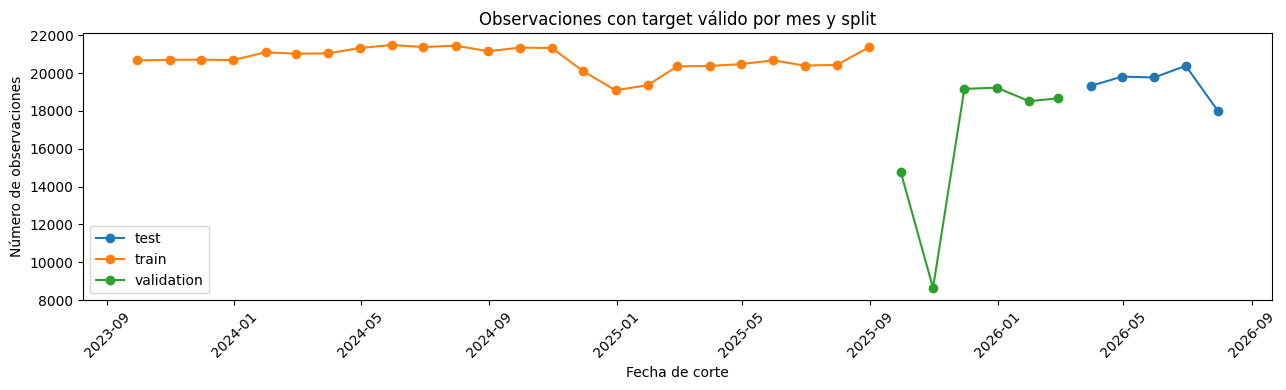

In [6]:
resumen_split = (
    df_model_base.groupby("split", observed=True)
    .agg(
        fecha_min=("fecha_corte", "min"),
        fecha_max=("fecha_corte", "max"),
        n_filas=("operaciones_t1", "size"),
        n_unidades=("convenio", "nunique"),
        n_grupos=("id_grupo", "nunique"),
        n_productos=("producto", "nunique"),
        media_target=("operaciones_t1", "mean"),
        mediana_target=("operaciones_t1", "median"),
        pct_target_cero=("operaciones_t1", lambda s: 100*s.eq(0).mean()),
    )
    .reindex(["train", "validation", "test"])
)
display(resumen_split)

composicion_producto_split = pd.crosstab(
    df_model_base["producto"], df_model_base["split"], normalize="columns"
).mul(100).round(2)
display(composicion_producto_split)

mensual_split = df_model_base.groupby(["fecha_corte", "split"], observed=True).size().rename("n").reset_index()
fig, ax = plt.subplots(figsize=(13, 4))
for split, sub in mensual_split.groupby("split", observed=True):
    ax.plot(sub["fecha_corte"], sub["n"], marker="o", label=split)
ax.set_title("Observaciones con target válido por mes y split")
ax.set_xlabel("Fecha de corte")
ax.set_ylabel("Número de observaciones")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

if resumen_split["n_filas"].isna().any() or (resumen_split["n_filas"] <= 0).any():
    raise RuntimeError("Alguno de los splits quedó vacío. Revise la cobertura temporal antes de continuar.")

if not (
    resumen_split.loc["train", "fecha_max"] < resumen_split.loc["validation", "fecha_min"]
    and resumen_split.loc["validation", "fecha_max"] < resumen_split.loc["test", "fecha_min"]
):
    raise RuntimeError("Los splits temporales se traslapan.")

# 6. FE-A1 — Generación de nuevas características

**Objetivo.** Convertir los hallazgos del EDA y la estructura longitudinal del negocio en variables disponibles al cierre de $t$ que puedan aportar información para estimar `operaciones_t1`.

**Justificación.** La historia transaccional mostró persistencia elevada; pricing y repricing son centrales para el caso Multipricing; la heterogeneidad interna de los grupos exige contexto agregado; y la comparación con peers y la profundidad de la relación pueden aportar señal adicional. Por ello se construyen familias diferenciadas y se evalúa su utilidad exclusivamente con Train.

La construcción se realiza sobre el panel longitudinal completo para conservar la historia previa a cada fila. Ninguna feature utiliza información posterior a $t$.


## FE-A1.1 Historia transaccional

Para predecir $t+1$ es válido utilizar la información completa disponible al cierre de $t$. Los lags se validan contra mes calendario real. `ops_media_3m` exige información completa en $t,t-1,t-2$ y `ops_media_6m` exige los seis meses consecutivos $t$ a $t-5$.


In [7]:
df_feat = df_target  # df_target ya está ordenado longitudinalmente; se reutiliza para evitar una copia masiva
g = df_feat.groupby(LLAVE_UNIDAD, dropna=False, observed=True, sort=False)

df_feat["ops_t"] = df_feat["numero_operaciones"]

# Lags exactos de operaciones. Se construyen 1..6; solo algunos se exponen como features finales.
for k in range(1, 7):
    ops_shift = g["numero_operaciones"].shift(k)
    mes_shift = g["mes_idx"].shift(k)
    valido = (df_feat["mes_idx"] - mes_shift).eq(k)
    df_feat[f"_ops_lag_{k}"] = ops_shift.where(valido)

for k in [1, 2, 3, 6]:
    df_feat[f"ops_lag_{k}"] = df_feat[f"_ops_lag_{k}"]
    df_feat[f"ops_lag_{k}_disponible"] = df_feat[f"ops_lag_{k}"].notna().astype("int8")

cols_3 = ["ops_t", "_ops_lag_1", "_ops_lag_2"]
cols_6 = ["ops_t"] + [f"_ops_lag_{k}" for k in range(1, 6)]

df_feat["ops_hist_n_3"] = df_feat[cols_3].notna().sum(axis=1).astype("int8")
df_feat["ops_hist_n_6"] = df_feat[cols_6].notna().sum(axis=1).astype("int8")

df_feat["ops_media_3m"] = df_feat[cols_3].mean(axis=1, skipna=False)
df_feat["ops_mediana_3m"] = df_feat[cols_3].median(axis=1, skipna=False)
df_feat["ops_std_3m"] = df_feat[cols_3].std(axis=1, ddof=0, skipna=False)
df_feat["ops_media_6m"] = df_feat[cols_6].mean(axis=1, skipna=False)
df_feat["ops_std_6m"] = df_feat[cols_6].std(axis=1, ddof=0, skipna=False)

df_feat["ops_delta_1m"] = df_feat["ops_t"] - df_feat["ops_lag_1"]
df_feat["ops_pct_change_1m"] = np.where(
    df_feat["ops_lag_1"].gt(0),
    df_feat["ops_delta_1m"] / df_feat["ops_lag_1"],
    np.nan,
)

### Checkpoint 2 — Cobertura histórica


In [8]:
features_hist = [
    "ops_lag_1", "ops_lag_2", "ops_lag_3", "ops_lag_6",
    "ops_media_3m", "ops_mediana_3m", "ops_std_3m", "ops_media_6m", "ops_std_6m"
]

mask_model = df_feat["operaciones_t1"].notna() & df_feat["split"].isin(["train", "validation", "test"])
base_cov = df_feat.loc[mask_model]

cob_hist = []
for col in features_hist:
    row = {"feature": col}
    for split in ["train", "validation", "test"]:
        s = base_cov.loc[base_cov["split"].eq(split), col]
        row[f"pct_disponible_{split}"] = 100 * s.notna().mean()
    cob_hist.append(row)
display(pd.DataFrame(cob_hist))

# Cobertura de lags por producto en Train.
cob_producto_lags = (
    base_cov.loc[base_cov["split"].eq("train")]
    .groupby("producto", observed=True)
    [["ops_lag_1", "ops_lag_3", "ops_lag_6"]]
    .agg(lambda s: 100*s.notna().mean())
    .round(2)
)
display(cob_producto_lags)

,feature,pct_disponible_train,pct_disponible_validation,pct_disponible_test
0,ops_lag_1,91.643729,84.453400,94.348215
1,ops_lag_2,84.851624,70.642952,89.823086
2,ops_lag_3,78.869609,57.764715,86.237523
3,ops_lag_6,63.129576,41.498000,59.208051
4,ops_media_3m,84.851624,70.642952,89.823086
5,ops_mediana_3m,84.851624,70.642952,89.823086
6,ops_std_3m,84.851624,70.642952,89.823086
7,ops_media_6m,68.090698,43.677534,70.201174
8,ops_std_6m,68.090698,43.677534,70.201174


,ops_lag_1,ops_lag_3,ops_lag_6
producto,,,
APIS EMPRESARIALES,93.99,82.93,68.60
BBVA NET CASH,89.15,73.86,56.20
CENTRALIZACION DE CUENTAS,95.37,86.34,73.02
CONCENTRACION INMEDIATA EMPRESARIAL CIE,91.89,79.29,64.20
CREDIPROVEEDORES,93.75,81.25,62.50
DEPOSITO EMPRESARIAL,93.00,81.79,67.16
DEPOSITO EMPRESARIAL DOLARES,91.91,79.36,65.00
DOMICILIACION,93.70,82.60,67.53
HOST TO HOST SERVICIOS,94.24,83.62,68.77


## FE-A1.2 Pricing


In [9]:
df_feat["tarifa_vigente_t"] = df_feat["tarifa_vigente"]
df_feat["tarifa_anaquel_t"] = df_feat["tarifa_anaquel"]
df_feat["ingreso_bruto_t"] = df_feat["ingreso_bruto"]

df_feat["anaquel_valido"] = df_feat["tarifa_anaquel_t"].gt(0).astype("int8")
df_feat["posicion_tarifaria"] = np.where(
    df_feat["tarifa_anaquel_t"].gt(0),
    df_feat["tarifa_vigente_t"] / df_feat["tarifa_anaquel_t"],
    np.nan,
)
df_feat["descuento_rel_anaquel"] = 1 - df_feat["posicion_tarifaria"]
df_feat["gap_anaquel"] = df_feat["tarifa_anaquel_t"] - df_feat["tarifa_vigente_t"]

# Tarifa del mes calendario anterior.
tarifa_shift = g["tarifa_vigente"].shift(1)
mes_prev = g["mes_idx"].shift(1)
prev_mes_valido = (df_feat["mes_idx"] - mes_prev).eq(1)
df_feat["tarifa_lag_1"] = tarifa_shift.where(prev_mes_valido)
df_feat["delta_tarifa_1m"] = df_feat["tarifa_vigente_t"] - df_feat["tarifa_lag_1"]
df_feat["pct_delta_tarifa_1m"] = np.where(
    df_feat["tarifa_lag_1"].gt(0),
    df_feat["delta_tarifa_1m"] / df_feat["tarifa_lag_1"],
    np.nan,
)

# Sustituir cualquier infinito accidental por NaN explícito.
ratio_cols = ["posicion_tarifaria", "descuento_rel_anaquel", "pct_delta_tarifa_1m", "ops_pct_change_1m"]
df_feat[ratio_cols] = df_feat[ratio_cols].replace([np.inf, -np.inf], np.nan)

### Checkpoint 3 — Calidad de ratios tarifarios


,valor
n_tarifa_anaquel_cero,191099.000000
pct_tarifa_anaquel_cero,38.366128
n_posicion_valida,306994.000000
n_ratio_gt_1,23506.000000
n_ratio_gt_5,919.000000


,posicion_tarifaria
0.01,0.000000
0.05,0.000000
0.25,0.000000
0.50,0.660380
0.75,1.000000
0.95,1.161107
0.99,3.593163


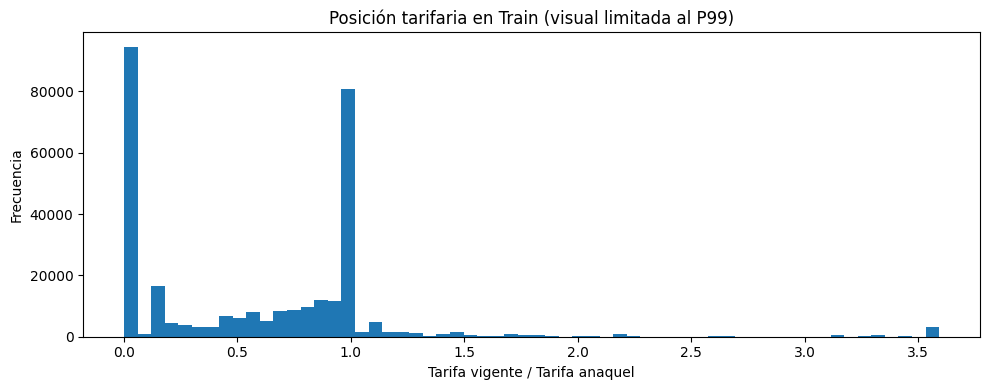

In [10]:
train_ck = df_feat.loc[mask_model & df_feat["split"].eq("train")]
ratio = train_ck["posicion_tarifaria"]
resumen_ratio = pd.Series({
    "n_tarifa_anaquel_cero": int(train_ck["tarifa_anaquel_t"].eq(0).sum()),
    "pct_tarifa_anaquel_cero": 100*train_ck["tarifa_anaquel_t"].eq(0).mean(),
    "n_posicion_valida": int(ratio.notna().sum()),
    "n_ratio_gt_1": int(ratio.gt(1).sum()),
    "n_ratio_gt_5": int(ratio.gt(5).sum()),
})
display(resumen_ratio.to_frame("valor"))
display(ratio.quantile([.01,.05,.25,.50,.75,.95,.99]).rename("posicion_tarifaria").to_frame())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(ratio.clip(upper=ratio.quantile(.99)).dropna(), bins=60)
ax.set_title("Posición tarifaria en Train (visual limitada al P99)")
ax.set_xlabel("Tarifa vigente / Tarifa anaquel")
ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## FE-A1.3 Repricing

Se conserva el criterio exploratorio de E1: un repricing requiere dos meses consecutivos, ambas tarifas estrictamente positivas y un cambio absoluto de al menos 5%. El historial se reinicia cuando la unidad presenta un hueco mensual, por lo que `meses_desde_repricing` representa meses **consecutivos observados** desde el último evento y no propaga información a través de periodos sin observación.


In [11]:
comparacion_repricing_valida = (
    prev_mes_valido
    & df_feat["tarifa_lag_1"].gt(0)
    & df_feat["tarifa_vigente_t"].gt(0)
)
df_feat["cambio_tarifa_pct"] = np.where(
    comparacion_repricing_valida,
    100 * (df_feat["tarifa_vigente_t"] / df_feat["tarifa_lag_1"] - 1),
    np.nan,
)
UMBRAL_REPRICING = 5.0
df_feat["repricing_flag_t"] = df_feat["cambio_tarifa_pct"].abs().ge(UMBRAL_REPRICING).astype("int8")

g_rep = df_feat.groupby(LLAVE_UNIDAD, dropna=False, observed=True, sort=False)
gap_prev_rep = df_feat["mes_idx"] - g_rep["mes_idx"].shift(1)

# Bloques de continuidad: cada hueco mensual inicia un historial nuevo.
df_feat["_nuevo_bloque_continuidad"] = (~gap_prev_rep.eq(1)).astype("int8")
df_feat["_bloque_continuidad"] = (
    df_feat.groupby(LLAVE_UNIDAD, dropna=False, observed=True, sort=False)["_nuevo_bloque_continuidad"]
    .cumsum()
    .astype("int32")
)

# Eventos previos exactos. Una ventana de 3 meses es válida solo si t-1 y t-2 existen.
for k in [1, 2]:
    flag_shift = g_rep["repricing_flag_t"].shift(k)
    idx_shift = g_rep["mes_idx"].shift(k)
    exacto = (df_feat["mes_idx"] - idx_shift).eq(k)
    df_feat[f"_repricing_lag_{k}"] = flag_shift.where(exacto)

df_feat["repricing_ultimo_mes"] = df_feat["_repricing_lag_1"].fillna(0).astype("int8")
ventana_rep3_completa = df_feat["_repricing_lag_1"].notna() & df_feat["_repricing_lag_2"].notna()
df_feat["repricing_ultimos_3m"] = np.where(
    ventana_rep3_completa,
    df_feat["repricing_flag_t"]
    + df_feat["_repricing_lag_1"].fillna(0)
    + df_feat["_repricing_lag_2"].fillna(0),
    np.nan,
)

# Último repricing conocido dentro del bloque continuo observado.
df_feat["_evento_repricing_mes"] = df_feat["mes_idx"].where(df_feat["repricing_flag_t"].eq(1))
df_feat["_evento_repricing_mag"] = df_feat["cambio_tarifa_pct"].where(df_feat["repricing_flag_t"].eq(1))
df_feat["_evento_repricing_dir"] = np.where(
    df_feat["repricing_flag_t"].eq(1),
    np.where(df_feat["cambio_tarifa_pct"].gt(0), "subida", "bajada"),
    None,
)

seg_cols = LLAVE_UNIDAD + ["_bloque_continuidad"]
g_seg = df_feat.groupby(seg_cols, dropna=False, observed=True, sort=False)
df_feat["_ultimo_repricing_mes_idx"] = g_seg["_evento_repricing_mes"].ffill()
df_feat["magnitud_ultimo_repricing"] = g_seg["_evento_repricing_mag"].ffill()
df_feat["direccion_ultimo_repricing"] = g_seg["_evento_repricing_dir"].ffill().fillna("sin_historial")
df_feat["meses_desde_repricing"] = df_feat["mes_idx"] - df_feat["_ultimo_repricing_mes_idx"]


### Checkpoint 4 — Cobertura de repricing


In [12]:
train_ck = df_feat.loc[mask_model & df_feat["split"].eq("train")]
print(f"Observaciones Train con repricing en t: {100*train_ck['repricing_flag_t'].mean():.2f}%")
print(f"Observaciones Train con historial de repricing conocido: {100*train_ck['meses_desde_repricing'].notna().mean():.2f}%")
display(train_ck["meses_desde_repricing"].describe().to_frame())
display(
    train_ck.loc[train_ck["repricing_flag_t"].eq(1)]
    .groupby("producto", observed=True).size().rename("eventos_repricing").sort_values(ascending=False).to_frame()
)
display(train_ck["magnitud_ultimo_repricing"].abs().quantile([.5,.9,.95,.99,1]).rename("magnitud_abs_pct").to_frame())

Observaciones Train con repricing en t: 0.99%
Observaciones Train con historial de repricing conocido: 9.03%


,meses_desde_repricing
count,44998.000000
mean,6.128295
std,4.775271
min,0.000000
25%,2.000000
50%,5.000000
75%,10.000000
max,22.000000


,eventos_repricing
producto,
CONCENTRACION INMEDIATA EMPRESARIAL CIE,2644
BBVA NET CASH,839
DEPOSITO EMPRESARIAL,618
SERVICIO INTEGRAL DE TESORERIA (SIT),591
SWIFT,92
DOMICILIACION,69
HOST TO HOST SERVICIOS,37
OPERACION T.I.B.,35
CENTRALIZACION DE CUENTAS,15


,magnitud_abs_pct
0.50,10.267253
0.90,57.232596
0.95,100.000000
0.99,235.769657
1.00,4500.000000


## FE-A1.4 Variables de calendario


In [13]:
df_feat["mes"] = df_feat["fecha_corte"].dt.month.astype("int8")
df_feat["trimestre"] = ("T" + df_feat["fecha_corte"].dt.quarter.astype(str))
df_feat["mes_sin"] = np.sin(2*np.pi*df_feat["mes"]/12)
df_feat["mes_cos"] = np.cos(2*np.pi*df_feat["mes"]/12)
mes_inicio = int(df_feat["mes_idx"].min())
df_feat["meses_desde_inicio"] = df_feat["mes_idx"] - mes_inicio

## FE-A1.5 Antigüedad


In [14]:
valid_seniority = df_feat["seniority"].notna() & df_feat["fecha_corte"].notna() & (df_feat["seniority"] <= df_feat["fecha_corte"])
mes_seniority = indice_mes(df_feat["seniority"])
df_feat["antiguedad_meses"] = np.where(
    valid_seniority,
    df_feat["mes_idx"] - mes_seniority,
    np.nan,
)
# seniority_invalido ya identifica fallos de parseo detectados desde la fuente.
print("Cobertura antigüedad:", round(100*pd.Series(df_feat["antiguedad_meses"]).notna().mean(), 2), "%")

Cobertura antigüedad: 97.92 %


## FE-A1.6 Contexto de grupo

Estas características describen la composición del grupo en el mismo mes $t$ sin colapsar la unidad contractual que será predicha. Los totales de operaciones corresponden al universo contractual unívoco utilizado por el panel supervisado.


In [15]:
g_grupo = df_feat.groupby(["fecha_corte", "id_grupo"], dropna=False, observed=True, sort=False)
df_feat["grupo_ops_total_t"] = g_grupo["numero_operaciones"].transform("sum")
df_feat["grupo_n_unidades"] = g_grupo["convenio"].transform("size")
df_feat["grupo_n_productos"] = g_grupo["producto"].transform("nunique")
df_feat["grupo_n_subproductos"] = g_grupo["subproducto"].transform("nunique")
df_feat["grupo_n_clientes"] = g_grupo["id_cliente"].transform("nunique")
df_feat["grupo_n_lineas"] = g_grupo["línea_contrato"].transform("nunique")
df_feat["grupo_n_convenios"] = g_grupo["convenio"].transform("nunique")
df_feat["grupo_n_tarifas"] = g_grupo["tarifa_vigente"].transform("nunique")
df_feat["grupo_tarifa_media"] = g_grupo["tarifa_vigente"].transform("mean")
df_feat["grupo_tarifa_std"] = g_grupo["tarifa_vigente"].transform("std")

df_feat["share_ops_grupo"] = np.where(
    df_feat["grupo_ops_total_t"].gt(0),
    df_feat["ops_t"] / df_feat["grupo_ops_total_t"],
    np.nan,
)

ops_grupo_producto = df_feat.groupby(
    ["fecha_corte", "id_grupo", "producto"], dropna=False, observed=True, sort=False
)["numero_operaciones"].transform("sum")
ops_grupo_subproducto = df_feat.groupby(
    ["fecha_corte", "id_grupo", "subproducto"], dropna=False, observed=True, sort=False
)["numero_operaciones"].transform("sum")

df_feat["share_producto_ops_grupo"] = np.where(
    df_feat["grupo_ops_total_t"].gt(0),
    ops_grupo_producto / df_feat["grupo_ops_total_t"],
    np.nan,
)
df_feat["share_subproducto_ops_grupo"] = np.where(
    df_feat["grupo_ops_total_t"].gt(0),
    ops_grupo_subproducto / df_feat["grupo_ops_total_t"],
    np.nan,
)


### Checkpoint 5 — Contexto grupo


In [16]:
train_ck = df_feat.loc[mask_model & df_feat["split"].eq("train")]
display(train_ck[[
    "grupo_n_unidades", "grupo_n_productos", "grupo_n_subproductos", "grupo_n_tarifas", "share_ops_grupo"
]].describe().T)

contextos_multitarifa = (
    train_ck.groupby(["fecha_corte", "id_grupo", "producto", "subproducto"], observed=True, dropna=False)["tarifa_vigente_t"]
    .nunique()
)
print(f"Contextos grupo-producto-subproducto-mes con >1 tarifa en Train: {100*contextos_multitarifa.gt(1).mean():.2f}%")

,count,mean,std,min,25%,50%,75%,max
grupo_n_unidades,498093.0,199.886493,194.412007,1.0,47.00000,136.000000,301.000000,737.0
grupo_n_productos,498093.0,6.568817,2.494753,1.0,5.00000,7.000000,8.000000,12.0
grupo_n_subproductos,498093.0,42.992762,23.153516,1.0,27.00000,45.000000,58.000000,113.0
grupo_n_tarifas,498093.0,14.268076,8.623372,1.0,9.00000,14.000000,18.000000,54.0
share_ops_grupo,497610.0,0.029132,0.112971,0.0,0.00004,0.000471,0.004975,1.0


Contextos grupo-producto-subproducto-mes con >1 tarifa en Train: 5.82%


## FE-A1.7 Vinculación del grupo

La vinculación se representa mediante componentes observables de **permanencia, amplitud, profundidad y estabilidad**. No se construye un score con pesos arbitrarios. Todas las variables se calculan con información disponible hasta $t$ y se validan contra `operaciones_t1` únicamente en Train.


In [17]:
# Tabla grupo-mes para historia causal a nivel grupo.
grupo_mes = (
    df_feat.groupby(["id_grupo", "fecha_corte"], dropna=False, observed=True, sort=False)
    .agg(
        grupo_ops_total_t=("numero_operaciones", "sum"),
        grupo_antiguedad_max_meses=("antiguedad_meses", "max"),
        grupo_antiguedad_mediana_meses=("antiguedad_meses", "median"),
    )
    .reset_index()
    .sort_values(["id_grupo", "fecha_corte"])
)
grupo_mes["mes_idx"] = indice_mes(grupo_mes["fecha_corte"])

gg = grupo_mes.groupby("id_grupo", dropna=False, observed=True, sort=False)
primera_fecha = gg["fecha_corte"].transform("min")
grupo_mes["grupo_antiguedad_observada_meses"] = indice_mes(grupo_mes["fecha_corte"]) - indice_mes(primera_fecha)
grupo_mes["grupo_meses_observado"] = gg.cumcount() + 1
meses_transcurridos = grupo_mes["grupo_antiguedad_observada_meses"] + 1
grupo_mes["grupo_pct_meses_activo"] = np.where(
    meses_transcurridos.gt(0),
    grupo_mes["grupo_meses_observado"] / meses_transcurridos,
    np.nan,
)

# Conteos históricos distintos por primera aparición: resultado causal para cada t.
def acumulado_distintos(data, entidad_col, out_col):
    first_seen = (
        data.groupby(["id_grupo", entidad_col], dropna=False, observed=True)["fecha_corte"]
        .min()
        .reset_index()
    )
    nuevos = (
        first_seen.groupby(["id_grupo", "fecha_corte"], dropna=False, observed=True)
        .size().rename("_nuevos").reset_index()
    )
    base = grupo_mes[["id_grupo", "fecha_corte"]].merge(
        nuevos, on=["id_grupo", "fecha_corte"], how="left"
    )
    base["_nuevos"] = base["_nuevos"].fillna(0)
    base[out_col] = base.groupby("id_grupo", dropna=False, observed=True)["_nuevos"].cumsum()
    return base[["id_grupo", "fecha_corte", out_col]]

grupo_mes = grupo_mes.merge(
    acumulado_distintos(df_feat, "producto", "grupo_n_productos_hist"),
    on=["id_grupo", "fecha_corte"], how="left"
)
grupo_mes = grupo_mes.merge(
    acumulado_distintos(df_feat, "subproducto", "grupo_n_subproductos_hist"),
    on=["id_grupo", "fecha_corte"], how="left"
)

# Historia transaccional del grupo con meses calendario exactos.
gg = grupo_mes.groupby("id_grupo", dropna=False, observed=True, sort=False)
for k in range(1, 6):
    ops_shift = gg["grupo_ops_total_t"].shift(k)
    mes_shift = gg["mes_idx"].shift(k)
    valido = (grupo_mes["mes_idx"] - mes_shift).eq(k)
    grupo_mes[f"_grupo_ops_lag_{k}"] = ops_shift.where(valido)

grupo_mes["grupo_ops_lag_1"] = grupo_mes["_grupo_ops_lag_1"]
gcols3 = ["grupo_ops_total_t", "_grupo_ops_lag_1", "_grupo_ops_lag_2"]
gcols6 = ["grupo_ops_total_t"] + [f"_grupo_ops_lag_{k}" for k in range(1, 6)]
grupo_mes["grupo_hist_n_3"] = grupo_mes[gcols3].notna().sum(axis=1).astype("int8")
grupo_mes["grupo_hist_n_6"] = grupo_mes[gcols6].notna().sum(axis=1).astype("int8")
grupo_mes["grupo_ops_media_3m"] = grupo_mes[gcols3].mean(axis=1, skipna=False)
grupo_mes["grupo_ops_media_6m"] = grupo_mes[gcols6].mean(axis=1, skipna=False)
grupo_mes["grupo_ops_std_3m"] = grupo_mes[gcols3].std(axis=1, ddof=0, skipna=False)
grupo_mes["grupo_ops_std_6m"] = grupo_mes[gcols6].std(axis=1, ddof=0, skipna=False)
grupo_mes["grupo_ops_cv_6m"] = np.where(
    grupo_mes["grupo_ops_media_6m"].gt(0),
    grupo_mes["grupo_ops_std_6m"] / grupo_mes["grupo_ops_media_6m"],
    np.nan,
)

vinc_grupo_cols = [
    "grupo_antiguedad_max_meses", "grupo_antiguedad_mediana_meses",
    "grupo_antiguedad_observada_meses", "grupo_meses_observado", "grupo_pct_meses_activo",
    "grupo_n_productos_hist", "grupo_n_subproductos_hist",
    "grupo_ops_lag_1", "grupo_ops_media_3m", "grupo_ops_media_6m",
    "grupo_ops_std_3m", "grupo_ops_std_6m", "grupo_ops_cv_6m",
    "grupo_hist_n_3", "grupo_hist_n_6",
]
df_feat = df_feat.merge(
    grupo_mes[["id_grupo", "fecha_corte"] + vinc_grupo_cols],
    on=["id_grupo", "fecha_corte"], how="left", validate="many_to_one", sort=False
)

# El merge puede reconstruir el índice; se recalcula explícitamente la máscara supervisada.
mask_model = df_feat["operaciones_t1"].notna() & df_feat["split"].isin(["train", "validation", "test"])

# Amplitud/diversificación contemporánea.
df_feat["grupo_ratio_diversificacion"] = np.where(
    df_feat["grupo_n_subproductos"].gt(0),
    df_feat["grupo_n_productos"] / df_feat["grupo_n_subproductos"],
    np.nan,
)
df_feat["grupo_subproductos_por_producto"] = np.where(
    df_feat["grupo_n_productos"].gt(0),
    df_feat["grupo_n_subproductos"] / df_feat["grupo_n_productos"],
    np.nan,
)

VINCULACION_SUBFAMILIAS = {
    "Permanencia": [
        "grupo_antiguedad_max_meses", "grupo_antiguedad_mediana_meses",
        "grupo_antiguedad_observada_meses", "grupo_meses_observado", "grupo_pct_meses_activo",
    ],
    "Amplitud": [
        "grupo_n_clientes", "grupo_n_lineas", "grupo_n_convenios", "grupo_n_productos",
        "grupo_n_subproductos", "grupo_n_unidades", "grupo_n_productos_hist", "grupo_n_subproductos_hist",
    ],
    "Diversificación": ["grupo_ratio_diversificacion", "grupo_subproductos_por_producto"],
    "Estabilidad": [
        "grupo_ops_total_t", "grupo_ops_lag_1", "grupo_ops_media_3m", "grupo_ops_media_6m",
        "grupo_ops_std_3m", "grupo_ops_std_6m", "grupo_ops_cv_6m", "grupo_hist_n_3", "grupo_hist_n_6",
    ],
    "Participación": ["share_ops_grupo", "share_producto_ops_grupo", "share_subproducto_ops_grupo"],
}
VINCULACION_FEATURES = list(dict.fromkeys(
    feat for feats in VINCULACION_SUBFAMILIAS.values() for feat in feats if feat in df_feat.columns
))


### Checkpoint 6 — Vinculación del grupo y transaccionalidad futura

Se evalúan cuatro preguntas: (1) cobertura y asociación univariada; (2) comportamiento por quintiles; (3) si la señal persiste controlando aproximadamente por `ops_t`; y (4) si la vinculación se relaciona con sostener la actividad. `ratio_retencion_ops` y `caida_ops_50pct` utilizan $t+1$ exclusivamente como diagnóstico y nunca ingresan a los datasets predictivos.


,feature,subfamilia,cobertura_train_pct,n_validos,spearman,mutual_information,mediana,p25,p75
24,share_ops_grupo,Participación,99.903030,497610,0.684433,0.562942,0.000471,0.000040,0.004975
26,share_subproducto_ops_grupo,Participación,99.903030,497610,0.510470,0.437572,0.008722,0.000656,0.064374
25,share_producto_ops_grupo,Participación,99.903030,497610,0.204068,0.233298,0.150984,0.039257,0.577870
15,grupo_ops_total_t,Estabilidad,100.000000,498093,0.100594,0.148352,63647.000000,15063.000000,260515.000000
17,grupo_ops_media_3m,Estabilidad,91.381328,455164,0.101320,0.146979,63405.333333,15287.000000,268115.333333
16,grupo_ops_lag_1,Estabilidad,95.692371,476637,0.100427,0.140153,64375.000000,15159.000000,264070.000000
19,grupo_ops_std_3m,Estabilidad,91.381328,455164,0.089440,0.126577,4208.714161,942.207337,17288.327557
18,grupo_ops_media_6m,Estabilidad,78.333765,390175,0.100796,0.124117,64221.833333,15764.833333,272160.500000
10,grupo_n_unidades,Amplitud,100.000000,498093,-0.032475,0.114957,136.000000,47.000000,301.000000
20,grupo_ops_std_6m,Estabilidad,78.333765,390175,0.092960,0.110622,6248.039204,1619.203679,24091.471698


,n_features,max_abs_spearman,mediana_abs_spearman,max_MI
subfamilia,,,,
Amplitud,8,0.054754,0.015473,0.114957
Diversificación,2,0.017443,0.017443,0.083675
Estabilidad,9,0.101320,0.092960,0.148352
Participación,3,0.684433,0.510470,0.562942
Permanencia,5,0.051142,0.015622,0.080048


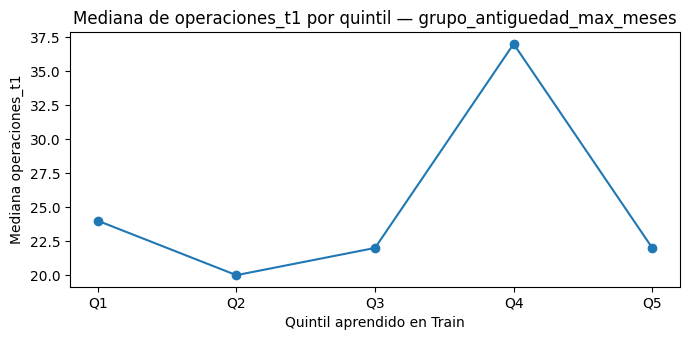

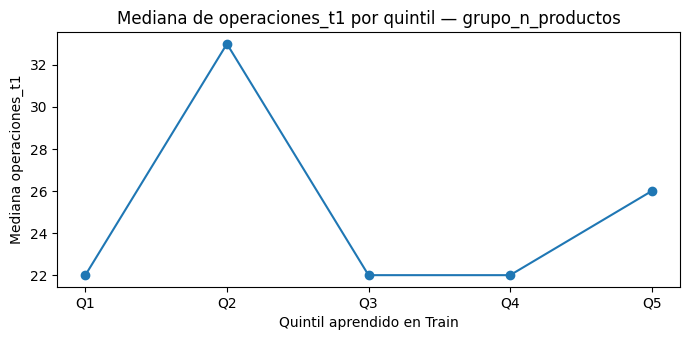

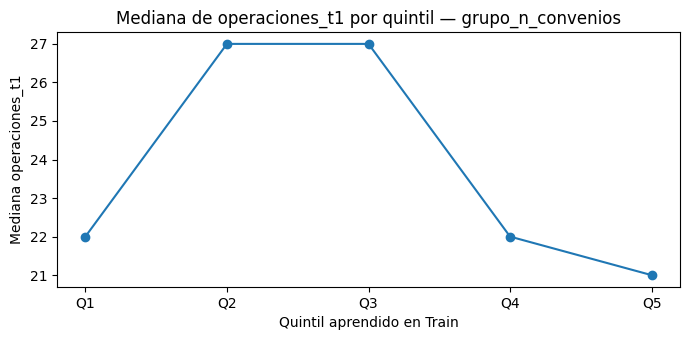

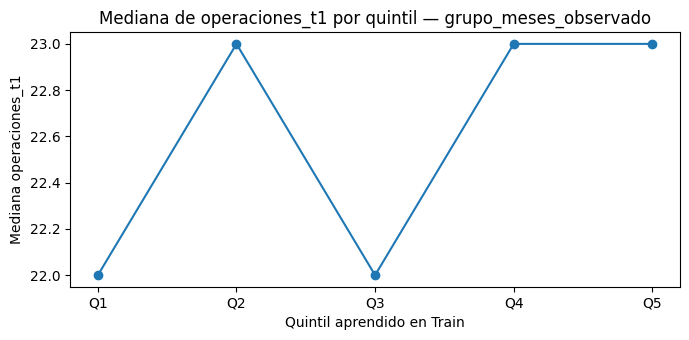

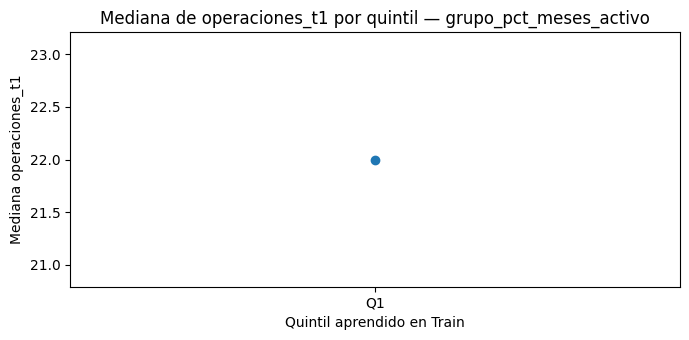

,feature,_vinc_q,n,media,mediana,p25,p75
0,grupo_antiguedad_max_meses,Q1,98007,965.988378,24.0,4.0,143.0
1,grupo_antiguedad_max_meses,Q2,98682,1121.702651,20.0,3.0,81.0
2,grupo_antiguedad_max_meses,Q3,98005,960.634131,22.0,4.0,111.0
3,grupo_antiguedad_max_meses,Q4,97266,2642.128185,37.0,4.0,212.0
4,grupo_antiguedad_max_meses,Q5,97544,2698.717133,22.0,4.0,152.0
5,grupo_n_productos,Q1,103897,759.636621,22.0,3.0,112.0
6,grupo_n_productos,Q2,97121,1803.021623,33.0,5.0,195.0
7,grupo_n_productos,Q3,101241,2125.020496,22.0,3.0,142.0
8,grupo_n_productos,Q4,161549,1720.218256,22.0,3.0,109.0
9,grupo_n_productos,Q5,34285,2228.918798,26.0,5.0,256.0


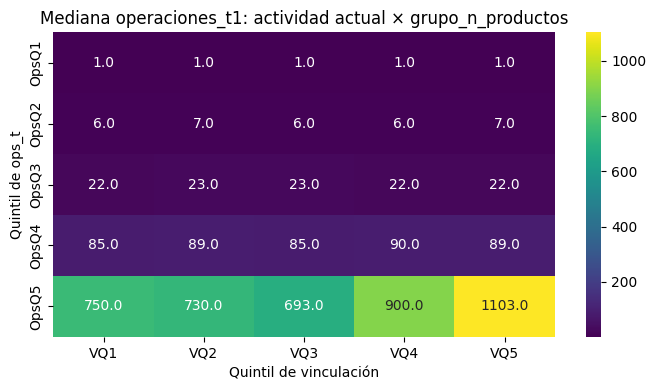

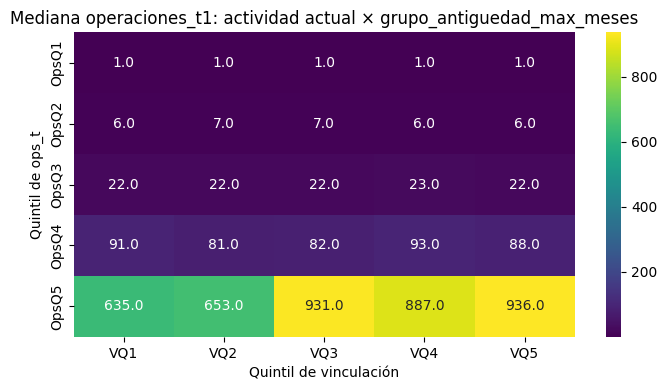

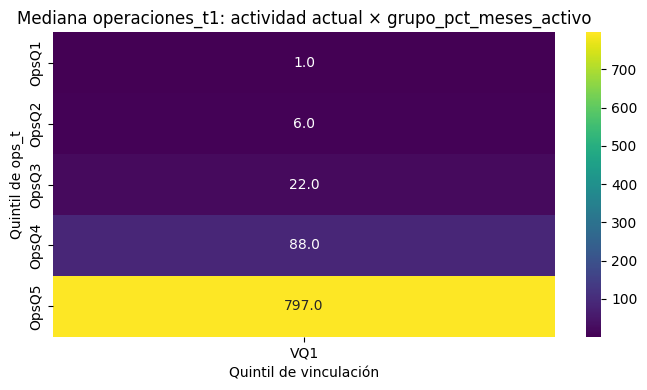

,feature,_ops_q,_vinc_q,n,media,mediana
0,grupo_n_productos,OpsQ1,VQ1,23093,90.382670,1.0
1,grupo_n_productos,OpsQ1,VQ2,19276,67.122276,1.0
2,grupo_n_productos,OpsQ1,VQ3,21973,108.763027,1.0
3,grupo_n_productos,OpsQ1,VQ4,36610,20.341246,1.0
4,grupo_n_productos,OpsQ1,VQ5,6990,11.188555,1.0
5,grupo_n_productos,OpsQ2,VQ1,19690,13.124937,6.0
6,grupo_n_productos,OpsQ2,VQ2,16014,12.544399,7.0
7,grupo_n_productos,OpsQ2,VQ3,22113,10.355854,6.0
8,grupo_n_productos,OpsQ2,VQ4,30564,11.118113,6.0
9,grupo_n_productos,OpsQ2,VQ5,5053,12.218484,7.0


,feature,_vinc_q,n,mediana_ratio_retencion,pct_caida_50
0,grupo_n_productos,VQ1,96956,1.0,7.627171
1,grupo_n_productos,VQ2,91184,1.0,6.270837
2,grupo_n_productos,VQ3,96816,1.0,6.203520
3,grupo_n_productos,VQ4,153197,1.0,5.536009
4,grupo_n_productos,VQ5,33032,1.0,4.286752
5,grupo_antiguedad_max_meses,VQ1,92192,1.0,7.131855
6,grupo_antiguedad_max_meses,VQ2,94039,1.0,5.443486
7,grupo_antiguedad_max_meses,VQ3,92273,1.0,6.092790
8,grupo_antiguedad_max_meses,VQ4,91809,1.0,6.068033
9,grupo_antiguedad_max_meses,VQ5,92756,1.0,6.025486


,feature,subfamilia,cobertura_train_pct,spearman,mutual_information,senal_condicionada,rho_validation,rho_test,signo_estable,redundancia_max,decision
11,grupo_n_productos_hist,Amplitud,100.000000,-0.002251,0.041836,NaN,0.000547,-0.019291,False,0.973931,Baja prioridad
23,grupo_hist_n_6,Estabilidad,100.000000,0.007890,0.008377,NaN,0.003453,0.008725,True,0.696497,Baja prioridad
22,grupo_hist_n_3,Estabilidad,100.000000,0.002039,0.000000,NaN,-0.002069,0.005512,False,0.675459,Baja prioridad
4,grupo_pct_meses_activo,Permanencia,100.000000,-0.014824,0.000937,0.009411,0.002319,-0.015170,False,0.149090,Baja prioridad / excluir Dataset A
24,share_ops_grupo,Participación,99.903030,0.684433,0.562942,NaN,0.673073,0.715377,True,0.672587,Conservar
26,share_subproducto_ops_grupo,Participación,99.903030,0.510470,0.437572,NaN,0.508770,0.542928,True,0.672587,Conservar
25,share_producto_ops_grupo,Participación,99.903030,0.204068,0.233298,NaN,0.192995,0.214686,True,0.387034,Conservar
15,grupo_ops_total_t,Estabilidad,100.000000,0.100594,0.148352,NaN,0.109088,0.088249,True,0.997541,Conservar
17,grupo_ops_media_3m,Estabilidad,91.381328,0.101320,0.146979,NaN,0.104035,0.088750,True,0.998836,Conservar
16,grupo_ops_lag_1,Estabilidad,95.692371,0.100427,0.140153,NaN,0.095552,0.088048,True,0.997920,Conservar


In [18]:
train_vinc = df_feat.loc[mask_model & df_feat["split"].eq("train")].copy()

# 1) Cobertura, Spearman y Mutual Information.
vinc_rows = []
mi_cols = [c for c in VINCULACION_FEATURES if pd.api.types.is_numeric_dtype(train_vinc[c])]
n_mi_vinc = min(30000, len(train_vinc))
mi_vinc_sample = train_vinc[mi_cols + ["operaciones_t1"]].sample(
    n=n_mi_vinc, random_state=RANDOM_STATE
) if len(train_vinc) > n_mi_vinc else train_vinc[mi_cols + ["operaciones_t1"]].copy()
for c in mi_cols:
    mi_vinc_sample[c] = mi_vinc_sample[c].replace([np.inf, -np.inf], np.nan)
    if not mi_vinc_sample[c].notna().any():
        mi_vinc_sample[c] = 0.0
        continue
    med = mi_vinc_sample[c].median()
    mi_vinc_sample[c] = mi_vinc_sample[c].fillna(med)
mi_vals = mutual_info_regression(
    mi_vinc_sample[mi_cols], mi_vinc_sample["operaciones_t1"], random_state=RANDOM_STATE
) if mi_cols else []
mi_vinc_map = dict(zip(mi_cols, mi_vals))

for subfam, feats in VINCULACION_SUBFAMILIAS.items():
    for feat in feats:
        if feat not in train_vinc.columns:
            continue
        tmp = train_vinc[[feat, "operaciones_t1"]].replace([np.inf, -np.inf], np.nan).dropna()
        rho = tmp[feat].corr(tmp["operaciones_t1"], method="spearman") if len(tmp) >= 3 and tmp[feat].nunique() >= 2 else np.nan
        vinc_rows.append({
            "feature": feat, "subfamilia": subfam,
            "cobertura_train_pct": 100 * train_vinc[feat].notna().mean(),
            "n_validos": len(tmp), "spearman": rho,
            "mutual_information": mi_vinc_map.get(feat, np.nan),
            "mediana": train_vinc[feat].median(), "p25": train_vinc[feat].quantile(.25),
            "p75": train_vinc[feat].quantile(.75),
        })
vinc_utilidad = pd.DataFrame(vinc_rows)
display(vinc_utilidad.sort_values("mutual_information", ascending=False))

display(
    vinc_utilidad.assign(abs_spearman=vinc_utilidad["spearman"].abs())
    .groupby("subfamilia", observed=True)
    .agg(
        n_features=("feature", "size"), max_abs_spearman=("abs_spearman", "max"),
        mediana_abs_spearman=("abs_spearman", "median"), max_MI=("mutual_information", "max")
    )
)

# Helper de cortes cuantiles aprendidos únicamente en Train.
def edges_q_train(s, q=5):
    s = s.replace([np.inf, -np.inf], np.nan).dropna()
    if s.nunique() < 2:
        return np.array([-np.inf, np.inf])
    _, edges = pd.qcut(s, q=q, retbins=True, duplicates="drop")
    edges = np.unique(edges.astype(float))
    edges[0], edges[-1] = -np.inf, np.inf
    return edges

vinc_principales = [
    c for c in [
        "grupo_antiguedad_max_meses", "grupo_n_productos", "grupo_n_convenios",
        "grupo_meses_observado", "grupo_pct_meses_activo"
    ] if c in train_vinc.columns
]

# 2) Quintiles de vinculación.
vinc_quintiles_rows = []
VINC_EDGES = {}
for feat in vinc_principales:
    edges = edges_q_train(train_vinc[feat], q=5)
    VINC_EDGES[feat] = edges
    labels = [f"Q{i+1}" for i in range(len(edges) - 1)]
    qv = pd.cut(train_vinc[feat], bins=edges, labels=labels, include_lowest=True)
    tmp = train_vinc.assign(_vinc_q=qv).dropna(subset=["_vinc_q"])
    tab = (
        tmp.groupby("_vinc_q", observed=True)["operaciones_t1"]
        .agg(n="size", media="mean", mediana="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75))
        .reset_index()
    )
    tab.insert(0, "feature", feat)
    vinc_quintiles_rows.append(tab)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(tab["_vinc_q"].astype(str), tab["mediana"], marker="o")
    ax.set_title(f"Mediana de operaciones_t1 por quintil — {feat}")
    ax.set_xlabel("Quintil aprendido en Train")
    ax.set_ylabel("Mediana operaciones_t1")
    plt.tight_layout(); plt.show()
vinc_quintiles = pd.concat(vinc_quintiles_rows, ignore_index=True) if vinc_quintiles_rows else pd.DataFrame()
display(vinc_quintiles)

# 3) Valor incremental aproximado condicionado por nivel actual de operaciones.
OPS_T_Q_EDGES_VINC = edges_q_train(train_vinc["ops_t"], q=5)
ops_labels = [f"OpsQ{i+1}" for i in range(len(OPS_T_Q_EDGES_VINC) - 1)]
train_vinc["_ops_q"] = pd.cut(train_vinc["ops_t"], OPS_T_Q_EDGES_VINC, labels=ops_labels, include_lowest=True)

cond_rows = []
cond_spearman = {}
for feat in [c for c in ["grupo_n_productos", "grupo_antiguedad_max_meses", "grupo_pct_meses_activo"] if c in train_vinc]:
    edges = VINC_EDGES.get(feat, edges_q_train(train_vinc[feat], q=5))
    vlabels = [f"VQ{i+1}" for i in range(len(edges) - 1)]
    train_vinc["_vinc_q"] = pd.cut(train_vinc[feat], edges, labels=vlabels, include_lowest=True)
    tab = (
        train_vinc.dropna(subset=["_ops_q", "_vinc_q"])
        .groupby(["_ops_q", "_vinc_q"], observed=True)["operaciones_t1"]
        .agg(n="size", media="mean", mediana="median")
        .reset_index()
    )
    tab.insert(0, "feature", feat)
    cond_rows.append(tab)

    rhos = []
    for _, sub in train_vinc.groupby("_ops_q", observed=True):
        z = sub[[feat, "operaciones_t1"]].dropna()
        if len(z) >= 100 and z[feat].nunique() >= 3:
            rhos.append(z[feat].corr(z["operaciones_t1"], method="spearman"))
    cond_spearman[feat] = float(np.nanmedian(np.abs(rhos))) if rhos else np.nan

    pivot = tab.pivot(index="_ops_q", columns="_vinc_q", values="mediana")
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="viridis", ax=ax)
    ax.set_title(f"Mediana operaciones_t1: actividad actual × {feat}")
    ax.set_xlabel("Quintil de vinculación")
    ax.set_ylabel("Quintil de ops_t")
    plt.tight_layout(); plt.show()

vinc_condicionada = pd.concat(cond_rows, ignore_index=True) if cond_rows else pd.DataFrame()
display(vinc_condicionada)

# 4) Sostenimiento: variables exclusivamente diagnósticas que usan t+1.
diag_ret = train_vinc.loc[train_vinc["ops_t"].gt(0)].copy()
diag_ret["ratio_retencion_ops"] = diag_ret["operaciones_t1"] / diag_ret["ops_t"]
diag_ret["caida_ops_50pct"] = (diag_ret["operaciones_t1"] < .5 * diag_ret["ops_t"]).astype("int8")
ret_rows = []
for feat in [c for c in ["grupo_n_productos", "grupo_antiguedad_max_meses", "grupo_pct_meses_activo"] if c in diag_ret]:
    edges = VINC_EDGES.get(feat, edges_q_train(train_vinc[feat], q=5))
    labels = [f"VQ{i+1}" for i in range(len(edges) - 1)]
    diag_ret["_vinc_q"] = pd.cut(diag_ret[feat], edges, labels=labels, include_lowest=True)
    tab = (
        diag_ret.dropna(subset=["_vinc_q"])
        .groupby("_vinc_q", observed=True)
        .agg(
            n=("operaciones_t1", "size"),
            mediana_ratio_retencion=("ratio_retencion_ops", "median"),
            pct_caida_50=("caida_ops_50pct", lambda s: 100 * s.mean()),
        ).reset_index()
    )
    tab.insert(0, "feature", feat)
    ret_rows.append(tab)
vinc_sostenimiento = pd.concat(ret_rows, ignore_index=True) if ret_rows else pd.DataFrame()
display(vinc_sostenimiento)

# 5) Estabilidad entre splits y redundancia interna para decisión documentada.
stability_rows = []
for feat in VINCULACION_FEATURES:
    row = {"feature": feat}
    for split in ["train", "validation", "test"]:
        sub = df_feat.loc[mask_model & df_feat["split"].eq(split), [feat, "operaciones_t1"]].dropna()
        row[f"rho_{split}"] = sub[feat].corr(sub["operaciones_t1"], method="spearman") if len(sub) >= 3 and sub[feat].nunique() >= 2 else np.nan
    stability_rows.append(row)
vinc_stability = pd.DataFrame(stability_rows)

corr_vinc = train_vinc[VINCULACION_FEATURES].corr(method="spearman").abs()
np.fill_diagonal(corr_vinc.values, np.nan)
redund_max = corr_vinc.max(axis=1).to_dict()

vinc_decisiones = vinc_utilidad.merge(vinc_stability, on="feature", how="left")
vinc_decisiones["senal_condicionada"] = vinc_decisiones["feature"].map(cond_spearman)
vinc_decisiones["redundancia_max"] = vinc_decisiones["feature"].map(redund_max)
vinc_decisiones["signo_estable"] = vinc_decisiones.apply(
    lambda r: len({np.sign(x) for x in [r["rho_train"], r["rho_validation"], r["rho_test"]] if pd.notna(x) and x != 0}) <= 1,
    axis=1,
)

core_interaccion = {
    "grupo_n_productos", "grupo_n_subproductos", "grupo_n_convenios", "grupo_n_clientes",
    "grupo_antiguedad_max_meses", "grupo_meses_observado", "grupo_pct_meses_activo",
    "grupo_ops_media_3m", "grupo_ops_media_6m", "share_producto_ops_grupo",
}

def decidir_vinc(r):
    cov = r["cobertura_train_pct"]
    rho = abs(r["spearman"]) if pd.notna(r["spearman"]) else 0
    mi = r["mutual_information"] if pd.notna(r["mutual_information"]) else 0
    cond = r["senal_condicionada"] if pd.notna(r["senal_condicionada"]) else 0
    if cov < 50:
        return "Eliminar"
    if rho >= .10 or mi >= .05 or cond >= .05:
        return "Conservar"
    if r["feature"] in core_interaccion:
        return "Conservar para interacción"
    return "Baja prioridad"

vinc_decisiones["decision"] = vinc_decisiones.apply(decidir_vinc, axis=1)

# Decisiones de redundancia/baja variabilidad aprendidas únicamente con Train.
VINCULACION_EXCLUIR_DATASET_A = set()
VINCULACION_EXCLUSION_REASON = {}

# Dos razones recíprocas contienen la misma información; se conserva la forma más interpretable.
if {"grupo_ratio_diversificacion", "grupo_subproductos_por_producto"}.issubset(train_vinc.columns):
    VINCULACION_EXCLUIR_DATASET_A.add("grupo_ratio_diversificacion")
    VINCULACION_EXCLUSION_REASON["grupo_ratio_diversificacion"] = (
        "redundante con grupo_subproductos_por_producto; ambas son transformaciones recíprocas"
    )

# Permanencia observada: si la relación es prácticamente perfecta, se conserva meses observados.
if {"grupo_antiguedad_observada_meses", "grupo_meses_observado"}.issubset(train_vinc.columns):
    z = train_vinc[["grupo_antiguedad_observada_meses", "grupo_meses_observado"]].dropna()
    rho_perm = z.iloc[:, 0].corr(z.iloc[:, 1], method="spearman") if len(z) >= 3 else np.nan
    if pd.notna(rho_perm) and abs(rho_perm) >= .995:
        VINCULACION_EXCLUIR_DATASET_A.add("grupo_antiguedad_observada_meses")
        VINCULACION_EXCLUSION_REASON["grupo_antiguedad_observada_meses"] = (
            f"redundante con grupo_meses_observado (Spearman Train={rho_perm:.4f})"
        )

# Una variable casi constante y sin MI relevante no aporta discriminación útil al Dataset A.
if "grupo_pct_meses_activo" in train_vinc.columns:
    s_act = train_vinc["grupo_pct_meses_activo"].dropna()
    iqr_act = s_act.quantile(.75) - s_act.quantile(.25) if len(s_act) else np.nan
    mi_row = vinc_utilidad.loc[vinc_utilidad["feature"].eq("grupo_pct_meses_activo"), "mutual_information"]
    mi_act = float(mi_row.iloc[0]) if len(mi_row) else np.nan
    if pd.notna(iqr_act) and iqr_act <= .01 and (pd.isna(mi_act) or mi_act < .01):
        VINCULACION_EXCLUIR_DATASET_A.add("grupo_pct_meses_activo")
        VINCULACION_EXCLUSION_REASON["grupo_pct_meses_activo"] = (
            f"baja variabilidad en Train (IQR={iqr_act:.4f}) y MI={mi_act:.4f}"
        )

for feat, motivo in VINCULACION_EXCLUSION_REASON.items():
    idx = vinc_decisiones["feature"].eq(feat)
    if feat == "grupo_pct_meses_activo":
        vinc_decisiones.loc[idx, "decision"] = "Baja prioridad / excluir Dataset A"
    else:
        vinc_decisiones.loc[idx, "decision"] = "Eliminar por redundancia"

display(vinc_decisiones[[
    "feature", "subfamilia", "cobertura_train_pct", "spearman", "mutual_information",
    "senal_condicionada", "rho_validation", "rho_test", "signo_estable", "redundancia_max", "decision"
]].sort_values(["decision", "mutual_information"], ascending=[True, False]))


## FE-A1.8 Peers

Las estadísticas peer se construyen por mes, porque la predicción utiliza información contemporánea disponible al cierre de $t$. La viabilidad se evalúa a nivel **peer-mes**, no acumulando todo Train. Si la granularidad principal no dispone de masa suficiente para una fila concreta, se aplica un fallback jerárquico hacia `producto`.


In [19]:
# Categoría explícita para industria faltante en la definición de peers.
df_feat["industria_peer"] = df_feat["industria"].fillna("Desconocido")
train_peer = df_feat.loc[mask_model & df_feat["split"].eq("train")].copy()

PEER_SIMPLE = ["industria_peer", "producto"]
PEER_ESPECIFICO = ["industria_peer", "producto", "subproducto"]
PEER_FALLBACK = ["producto"]


def diagnostico_peer_mes(data, cols, nombre):
    key = ["fecha_corte"] + cols
    tab = (
        data.groupby(key, observed=True, dropna=False)
        .agg(n_obs=("operaciones_t1", "size"), n_grupos=("id_grupo", "nunique"))
        .reset_index()
    )
    calificado = tab["n_obs"].ge(30) & tab["n_grupos"].ge(5)
    claves_calif = tab.loc[calificado, key]
    if len(claves_calif):
        tmp = data[key].merge(claves_calif.assign(_ok=1), on=key, how="left")
        cobertura_calificada = 100 * tmp["_ok"].fillna(0).mean()
    else:
        cobertura_calificada = 0.0

    q_obs = tab["n_obs"].quantile([.10, .25, .50, .75, .90])
    q_grp = tab["n_grupos"].quantile([.10, .25, .50, .75, .90])
    return {
        "definicion": nombre,
        "n_peer_mes": len(tab),
        "p10_obs": q_obs.loc[.10], "p25_obs": q_obs.loc[.25], "p50_obs": q_obs.loc[.50],
        "p75_obs": q_obs.loc[.75], "p90_obs": q_obs.loc[.90],
        "p10_grupos": q_grp.loc[.10], "p25_grupos": q_grp.loc[.25], "p50_grupos": q_grp.loc[.50],
        "p75_grupos": q_grp.loc[.75], "p90_grupos": q_grp.loc[.90],
        "pct_peer_mes_ge30_obs": 100 * tab["n_obs"].ge(30).mean(),
        "pct_peer_mes_ge5_grupos": 100 * tab["n_grupos"].ge(5).mean(),
        "cobertura_calificada_pct": cobertura_calificada,
    }


diag_peer = pd.DataFrame([
    diagnostico_peer_mes(train_peer, PEER_SIMPLE, "industria × producto"),
    diagnostico_peer_mes(train_peer, PEER_ESPECIFICO, "industria × producto × subproducto"),
    diagnostico_peer_mes(train_peer, PEER_FALLBACK, "producto"),
])
display(diag_peer)


def cumple_peer(row):
    return bool(
        row["cobertura_calificada_pct"] >= 95
        and row["pct_peer_mes_ge30_obs"] >= 80
        and row["pct_peer_mes_ge5_grupos"] >= 80
    )

fila_esp = diag_peer.loc[diag_peer["definicion"].eq("industria × producto × subproducto")].iloc[0]
fila_simple = diag_peer.loc[diag_peer["definicion"].eq("industria × producto")].iloc[0]

if cumple_peer(fila_esp):
    PEER_PRIMARIO = "especifico"
    PEER_NOMBRE = "industria × producto × subproducto"
elif cumple_peer(fila_simple):
    PEER_PRIMARIO = "simple"
    PEER_NOMBRE = "industria × producto"
else:
    PEER_PRIMARIO = "fallback"
    PEER_NOMBRE = "fallback jerárquico industria × producto → producto"

print("Estrategia peer definida con Train:", PEER_NOMBRE)


,definicion,n_peer_mes,p10_obs,p25_obs,p50_obs,p75_obs,p90_obs,p10_grupos,p25_grupos,p50_grupos,p75_grupos,p90_grupos,pct_peer_mes_ge30_obs,pct_peer_mes_ge5_grupos,cobertura_calificada_pct
0,industria × producto,4493,3.0,13.0,41.0,116.0,317.0,1.0,2.0,6.0,13.0,28.0,56.198531,61.495660,92.132393
1,industria × producto × subproducto,44600,1.0,1.0,4.0,10.0,26.0,1.0,1.0,2.0,5.0,10.0,8.773543,30.616592,43.942196
2,producto,331,41.0,155.0,490.0,2466.5,3464.0,8.0,21.0,81.0,216.0,520.0,94.259819,94.259819,99.992973


Estrategia peer definida con Train: fallback jerárquico industria × producto → producto


### Checkpoint 7 — Viabilidad de definición peer

La tabla anterior evalúa observaciones y diversidad de grupos **por peer-mes**. Las reglas de referencia son 95% de cobertura de filas, 80% de peer-mes con al menos 30 observaciones y 80% con al menos 5 grupos. Si ninguna definición satisface simultáneamente los criterios, se utiliza fallback jerárquico por fila en lugar de declarar que una definición insuficiente es válida.


In [20]:
def construir_estadisticas_peer(data, cols, prefijo):
    key = ["fecha_corte"] + cols
    gp = data.groupby(key, observed=True, dropna=False, sort=False)
    n = gp["ops_t"].transform("count")
    n_grupos = gp["id_grupo"].transform("nunique")
    suma_ops = gp["ops_t"].transform("sum")
    media_ops_loo = np.where(n.gt(1), (suma_ops - data["ops_t"]) / (n - 1), np.nan)
    return pd.DataFrame({
        f"_{prefijo}_n": n,
        f"_{prefijo}_grupos": n_grupos,
        f"_{prefijo}_calificado": n.ge(30) & n_grupos.ge(5),
        f"_{prefijo}_ops_media_loo": media_ops_loo,
        f"_{prefijo}_ops_mediana": gp["ops_t"].transform("median"),
        f"_{prefijo}_tarifa_mediana": gp["tarifa_vigente_t"].transform("median"),
        f"_{prefijo}_posicion_mediana": gp["posicion_tarifaria"].transform("median"),
    }, index=data.index)

stats_simple = construir_estadisticas_peer(df_feat, PEER_SIMPLE, "peer_simple")
stats_producto = construir_estadisticas_peer(df_feat, PEER_FALLBACK, "peer_producto")
stats_especifico = construir_estadisticas_peer(df_feat, PEER_ESPECIFICO, "peer_especifico")
for block in [stats_simple, stats_producto, stats_especifico]:
    for col in block.columns:
        df_feat[col] = block[col]

if PEER_PRIMARIO == "especifico":
    condiciones = [
        df_feat["_peer_especifico_calificado"],
        df_feat["_peer_simple_calificado"],
        df_feat["_peer_producto_calificado"],
    ]
    niveles = ["industria_producto_subproducto", "industria_producto", "producto"]
elif PEER_PRIMARIO == "simple":
    condiciones = [
        df_feat["_peer_simple_calificado"],
        df_feat["_peer_producto_calificado"],
    ]
    niveles = ["industria_producto", "producto"]
else:
    condiciones = [
        df_feat["_peer_simple_calificado"],
        df_feat["_peer_producto_calificado"],
    ]
    niveles = ["industria_producto", "producto"]

df_feat["peer_nivel"] = np.select(condiciones, niveles, default="no_disponible")
df_feat["peer_calificado_t"] = df_feat["peer_nivel"].ne("no_disponible").astype("int8")

MAP_PREFIJO = {
    "industria_producto_subproducto": "peer_especifico",
    "industria_producto": "peer_simple",
    "producto": "peer_producto",
}

for out_col, sufijo in [
    ("peer_n_t", "n"),
    ("peer_grupos_n_t", "grupos"),
    ("peer_ops_media_t", "ops_media_loo"),
    ("peer_ops_mediana_t", "ops_mediana"),
    ("peer_tarifa_mediana_t", "tarifa_mediana"),
    ("peer_posicion_tarifaria_mediana_t", "posicion_mediana"),
]:
    df_feat[out_col] = np.nan
    for nivel, pref in MAP_PREFIJO.items():
        mask = df_feat["peer_nivel"].eq(nivel)
        df_feat.loc[mask, out_col] = df_feat.loc[mask, f"_{pref}_{sufijo}"]

# La media de operaciones es leave-one-out. Las medianas incluyen la fila y se acompañan de n/grupos.
df_feat["ops_vs_peer"] = np.where(
    df_feat["peer_ops_mediana_t"].gt(0),
    df_feat["ops_t"] / df_feat["peer_ops_mediana_t"],
    np.nan,
)
df_feat["tarifa_vs_peer"] = np.where(
    df_feat["peer_tarifa_mediana_t"].gt(0),
    df_feat["tarifa_vigente_t"] / df_feat["peer_tarifa_mediana_t"],
    np.nan,
)
df_feat[["ops_vs_peer", "tarifa_vs_peer"]] = df_feat[["ops_vs_peer", "tarifa_vs_peer"]].replace([np.inf, -np.inf], np.nan)

peer_cobertura_nivel = (
    df_feat.loc[mask_model & df_feat["split"].eq("train"), "peer_nivel"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .rename("pct_train")
    .to_frame()
)
display(peer_cobertura_nivel)


,pct_train
peer_nivel,
industria_producto,92.602185
producto,7.390788
no_disponible,0.007027


## FE-A1.9 Catálogo de características y control de leakage


In [21]:
FAMILIAS = {
    "Historia transaccional": [
        "ops_t", "ops_lag_1", "ops_lag_2", "ops_lag_3", "ops_lag_6",
        "ops_media_3m", "ops_mediana_3m", "ops_std_3m", "ops_media_6m", "ops_std_6m",
        "ops_delta_1m", "ops_pct_change_1m", "ops_hist_n_3", "ops_hist_n_6",
        "ops_lag_1_disponible", "ops_lag_2_disponible", "ops_lag_3_disponible", "ops_lag_6_disponible"
    ],
    "Pricing": [
        "tarifa_vigente_t", "tarifa_anaquel_t", "anaquel_valido",
        "posicion_tarifaria", "descuento_rel_anaquel", "gap_anaquel", "tarifa_lag_1",
        "delta_tarifa_1m", "pct_delta_tarifa_1m"
    ],
    "Económica / Comisiones": ["ingreso_bruto_t"],
    "Repricing": [
        "repricing_flag_t", "repricing_ultimo_mes", "repricing_ultimos_3m",
        "meses_desde_repricing", "magnitud_ultimo_repricing", "direccion_ultimo_repricing"
    ],
    "Temporal": ["mes", "trimestre", "mes_sin", "mes_cos", "meses_desde_inicio"],
    "Antigüedad": ["antiguedad_meses", "seniority_invalido"],
    "Contexto grupo": ["grupo_n_tarifas", "grupo_tarifa_media", "grupo_tarifa_std"],
    "Vinculación": VINCULACION_FEATURES,
    "Peers": [
        "peer_ops_mediana_t", "peer_ops_media_t", "peer_tarifa_mediana_t",
        "peer_posicion_tarifaria_mediana_t", "peer_n_t", "peer_grupos_n_t",
        "peer_calificado_t", "peer_nivel", "ops_vs_peer", "tarifa_vs_peer"
    ],
    "Missing": ["missing_moneda", "missing_industria"],
}

mask_model = df_feat["operaciones_t1"].notna() & df_feat["split"].isin(["train", "validation", "test"])
df_model = df_feat.loc[mask_model].copy()

catalogo = []
for familia, feats in FAMILIAS.items():
    for feat in feats:
        if feat not in df_model.columns:
            continue
        row = {
            "feature": feat,
            "familia": familia,
            "tipo": str(df_model[feat].dtype),
            "fuente": "información disponible hasta t",
            "informacion_maxima": "t",
            "disponible_en_t": True,
            "usa_target": False,
            "uso": "predictor candidato",
            "incluir_X": True,
            "riesgo_leakage": "controlado: agregado contemporáneo t" if familia == "Peers" else "bajo",
        }
        for split in ["train", "validation", "test"]:
            s = df_model.loc[df_model["split"].eq(split), feat]
            row[f"pct_cobertura_{split}"] = 100 * s.notna().mean()
        catalogo.append(row)

feature_catalog = pd.DataFrame(catalogo).drop_duplicates(subset=["feature"], keep="first")
display(feature_catalog)

# Variables que usan t+1: solo diagnóstico, nunca predictores.
diagnostic_catalog = pd.DataFrame([
    {
        "feature": "ratio_retencion_ops", "familia": "Diagnóstico Vinculación", "tipo": "float",
        "fuente": "operaciones_t1 / ops_t", "informacion_maxima": "t+1", "disponible_en_t": False,
        "usa_target": True, "uso": "solo diagnóstico", "incluir_X": False, "riesgo_leakage": "alto si entrara a X",
        "pct_cobertura_train": np.nan, "pct_cobertura_validation": np.nan, "pct_cobertura_test": np.nan,
    },
    {
        "feature": "caida_ops_50pct", "familia": "Diagnóstico Vinculación", "tipo": "int",
        "fuente": "comparación operaciones_t1 vs ops_t", "informacion_maxima": "t+1", "disponible_en_t": False,
        "usa_target": True, "uso": "solo diagnóstico", "incluir_X": False, "riesgo_leakage": "alto si entrara a X",
        "pct_cobertura_train": np.nan, "pct_cobertura_validation": np.nan, "pct_cobertura_test": np.nan,
    },
])

# Liberar estructuras intermedias grandes una vez materializado el dataset supervisado.
del df_feat, df_target, df_panel, df_eda
gc.collect()


,feature,familia,tipo,fuente,informacion_maxima,disponible_en_t,usa_target,uso,incluir_X,riesgo_leakage,pct_cobertura_train,pct_cobertura_validation,pct_cobertura_test
0,ops_t,Historia transaccional,int64,información disponible hasta t,t,True,False,predictor candidato,True,bajo,100.000000,100.000000,100.000000
1,ops_lag_1,Historia transaccional,float64,información disponible hasta t,t,True,False,predictor candidato,True,bajo,91.643729,84.453400,94.348215
2,ops_lag_2,Historia transaccional,float64,información disponible hasta t,t,True,False,predictor candidato,True,bajo,84.851624,70.642952,89.823086
3,ops_lag_3,Historia transaccional,float64,información disponible hasta t,t,True,False,predictor candidato,True,bajo,78.869609,57.764715,86.237523
4,ops_lag_6,Historia transaccional,float64,información disponible hasta t,t,True,False,predictor candidato,True,bajo,63.129576,41.498000,59.208051
...,...,...,...,...,...,...,...,...,...,...,...,...,...
78,peer_nivel,Peers,object,información disponible hasta t,t,True,False,predictor candidato,True,controlado: agregado contemporáneo t,100.000000,100.000000,100.000000
79,ops_vs_peer,Peers,float64,información disponible hasta t,t,True,False,predictor candidato,True,controlado: agregado contemporáneo t,99.468172,98.802165,99.638154
80,tarifa_vs_peer,Peers,float64,información disponible hasta t,t,True,False,predictor candidato,True,controlado: agregado contemporáneo t,32.454180,22.456874,23.279433
81,missing_moneda,Missing,int8,información disponible hasta t,t,True,False,predictor candidato,True,bajo,100.000000,100.000000,100.000000


14870

## Control de leakage

El catálogo distingue predictores disponibles hasta $t$ de variables exclusivamente diagnósticas que utilizan $t+1$. Las segundas quedan marcadas explícitamente como `incluir_X = False` y no pueden formar parte de Dataset A ni Dataset B.


In [22]:
control_leakage = pd.concat([
    feature_catalog[[
        "feature", "familia", "fuente", "informacion_maxima", "disponible_en_t",
        "usa_target", "uso", "incluir_X", "riesgo_leakage"
    ]],
    diagnostic_catalog[[
        "feature", "familia", "fuente", "informacion_maxima", "disponible_en_t",
        "usa_target", "uso", "incluir_X", "riesgo_leakage"
    ]],
], ignore_index=True)
display(control_leakage)

if (control_leakage["usa_target"] & control_leakage["incluir_X"]).any():
    raise RuntimeError("Existe al menos una variable que usa target marcada para incluirse en X.")


,feature,familia,fuente,informacion_maxima,disponible_en_t,usa_target,uso,incluir_X,riesgo_leakage
0,ops_t,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
1,ops_lag_1,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
2,ops_lag_2,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
3,ops_lag_3,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
4,ops_lag_6,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
...,...,...,...,...,...,...,...,...,...
80,tarifa_vs_peer,Peers,información disponible hasta t,t,True,False,predictor candidato,True,controlado: agregado contemporáneo t
81,missing_moneda,Missing,información disponible hasta t,t,True,False,predictor candidato,True,bajo
82,missing_industria,Missing,información disponible hasta t,t,True,False,predictor candidato,True,bajo
83,ratio_retencion_ops,Diagnóstico Vinculación,operaciones_t1 / ops_t,t+1,False,True,solo diagnóstico,False,alto si entrara a X


## Validación preliminar de utilidad de las familias

La utilidad se evalúa exclusivamente sobre Train. Spearman y Mutual Information se utilizan como evidencia univariada; no se interpretan como causalidad ni sustituyen la evaluación predictiva de E3.


In [23]:
train_df = df_model.loc[df_model["split"].eq("train")]

features_numericas_catalogo = [
    f for f in feature_catalog["feature"]
    if f in train_df.columns and pd.api.types.is_numeric_dtype(train_df[f])
]

utilidad_rows = []
for feat in features_numericas_catalogo:
    tmp = train_df[[feat, "operaciones_t1"]].replace([np.inf, -np.inf], np.nan).dropna()
    rho = tmp[feat].corr(tmp["operaciones_t1"], method="spearman") if len(tmp) >= 3 and tmp[feat].nunique() >= 2 else np.nan
    utilidad_rows.append({"feature": feat, "spearman": rho})
utilidad = pd.DataFrame(utilidad_rows)

# Mutual Information sobre muestra reproducible de Train.
mi_feats = features_numericas_catalogo
n_mi = min(30000, len(train_df))
mi_sample = (
    train_df[mi_feats + ["operaciones_t1"]].sample(n=n_mi, random_state=RANDOM_STATE).copy()
    if len(train_df) > n_mi
    else train_df[mi_feats + ["operaciones_t1"]].copy()
)
mi_valid = []
for col in mi_feats:
    s = mi_sample[col].replace([np.inf, -np.inf], np.nan)
    if not s.notna().any():
        continue
    med = s.median()
    mi_sample[col] = s.fillna(med)
    if mi_sample[col].nunique() >= 2:
        mi_valid.append(col)

mi_map = {c: np.nan for c in mi_feats}
if mi_valid:
    mi_vals = mutual_info_regression(
        mi_sample[mi_valid], mi_sample["operaciones_t1"],
        random_state=RANDOM_STATE
    )
    mi_map.update(dict(zip(mi_valid, mi_vals)))

utilidad["mutual_information"] = utilidad["feature"].map(mi_map)
utilidad = utilidad.merge(feature_catalog[["feature", "familia"]], on="feature", how="left")
display(utilidad.sort_values("mutual_information", ascending=False).head(40))

resumen_familias = (
    utilidad.assign(abs_spearman=utilidad["spearman"].abs())
    .groupby("familia", observed=True)
    .agg(
        n_features=("feature", "size"),
        max_abs_spearman=("abs_spearman", "max"),
        mediana_abs_spearman=("abs_spearman", "median"),
        max_MI=("mutual_information", "max"),
        mediana_MI=("mutual_information", "median"),
    )
    .sort_values("max_MI", ascending=False)
)
display(resumen_familias)


,feature,spearman,mutual_information,familia
0,ops_t,0.937558,1.829749,Historia transaccional
5,ops_media_3m,0.961735,1.709257,Historia transaccional
6,ops_mediana_3m,0.957805,1.677031,Historia transaccional
1,ops_lag_1,0.940520,1.639369,Historia transaccional
2,ops_lag_2,0.956493,1.554728,Historia transaccional
8,ops_media_6m,0.961765,1.386949,Historia transaccional
3,ops_lag_3,0.929941,1.362189,Historia transaccional
4,ops_lag_6,0.925327,1.060222,Historia transaccional
76,ops_vs_peer,0.843998,1.016818,Peers
7,ops_std_3m,0.848397,0.740133,Historia transaccional


,n_features,max_abs_spearman,mediana_abs_spearman,max_MI,mediana_MI
familia,,,,,
Historia transaccional,18,0.961765,0.860070,1.829749,0.736388
Peers,9,0.843998,0.078564,1.016818,0.193598
Vinculación,27,0.684433,0.032475,0.561101,0.087244
Económica / Comisiones,1,0.303973,0.303973,0.498723,0.498723
Pricing,9,0.083926,0.041738,0.327557,0.223205
Contexto grupo,3,0.030982,0.011567,0.154222,0.142144
Temporal,4,0.015877,0.004189,0.062248,0.033902
Antigüedad,2,0.067105,0.034866,0.033258,0.019699
Repricing,5,0.081832,0.019038,0.030526,0.006758


### Conclusión FE-A1

La ingeniería de características confirma que la **historia transaccional** es la principal fuente de señal para $t+1$, seguida por **Peers**. La familia **Vinculación** aporta información de forma heterogénea: la participación de la unidad/producto dentro del grupo y la estabilidad transaccional son más informativas que la antigüedad o amplitud comercial tomadas de forma aislada. Pricing se conserva por su papel central en Multipricing, mientras que Repricing pasa a E3 principalmente como fuente de interacciones. Todas las familias incluidas como predictoras utilizan información disponible hasta $t$.

# 7. FE-A2 — Discretización / Binning

**Objetivo.** Crear representaciones categóricas complementarias de predictores continuos cuya interpretación por rangos sea útil para el negocio o para capturar relaciones no lineales.

**Justificación.** Los bins se aprenden únicamente con Train cuando dependen de la distribución. Se conservan junto con las variables continuas; no las sustituyen automáticamente. Su utilidad se contrasta mediante la distribución de `operaciones_t1` por intervalo.


## FE-A2.1 Posición tarifaria


In [24]:
pos_bins = [-np.inf, 0, .25, .50, .75, 1.0, np.inf]
pos_labels = ["<=0", "(0,.25]", "(.25,.50]", "(.50,.75]", "(.75,1]", ">1"]
df_model["posicion_tarifaria_bin"] = pd.cut(
    df_model["posicion_tarifaria"], bins=pos_bins, labels=pos_labels, include_lowest=True
).astype("object")
df_model["posicion_tarifaria_bin"] = df_model["posicion_tarifaria_bin"].fillna("No disponible")

bin_pos_summary = (
    df_model.loc[df_model["split"].eq("train")]
    .groupby("posicion_tarifaria_bin", observed=True)
    .agg(
        n=("operaciones_t1", "size"),
        media_target=("operaciones_t1", "mean"),
        mediana_target=("operaciones_t1", "median"),
        p25_target=("operaciones_t1", lambda s: s.quantile(.25)),
        p75_target=("operaciones_t1", lambda s: s.quantile(.75)),
    )
)
bin_pos_summary["pct"] = 100*bin_pos_summary["n"]/bin_pos_summary["n"].sum()
display(bin_pos_summary)

,n,media_target,mediana_target,p25_target,p75_target,pct
posicion_tarifaria_bin,,,,,,
"(.25,.50]",17381,5904.432426,67.0,5.0,258.0,3.489509
"(.50,.75]",29096,1943.784988,40.0,7.0,375.0,5.841479
"(.75,1]",118618,1346.814674,24.0,3.0,161.0,23.814428
"(0,.25]",24719,2696.559408,20.0,4.0,87.0,4.962728
<=0,93674,2208.029955,22.0,19.0,66.0,18.806528
>1,23506,983.747979,10.0,1.0,74.0,4.719199
No disponible,191099,1088.124208,22.0,2.0,149.0,38.366128


## FE-A2.2 Actividad actual y FE-A2.3 Antigüedad


In [25]:
def aprender_edges_cuantiles(serie_train, q=5):
    s = serie_train.dropna()
    if s.nunique() < 2:
        return np.array([-np.inf, np.inf])
    _, edges = pd.qcut(s, q=q, retbins=True, duplicates="drop")
    edges = np.unique(edges.astype(float))
    if len(edges) < 2:
        return np.array([-np.inf, np.inf])
    edges[0] = -np.inf
    edges[-1] = np.inf
    return edges

train_mask_df = df_model["split"].eq("train")
OPS_BIN_EDGES = aprender_edges_cuantiles(df_model.loc[train_mask_df, "ops_t"], q=5)
ANTIG_BIN_EDGES = aprender_edges_cuantiles(df_model.loc[train_mask_df, "antiguedad_meses"], q=5)

def aplicar_bins(serie, edges, prefijo):
    labels = [f"{prefijo}_{i+1}" for i in range(len(edges)-1)]
    out = pd.cut(serie, bins=edges, labels=labels, include_lowest=True).astype("object")
    return out.fillna("No disponible")

df_model["ops_t_bin"] = aplicar_bins(df_model["ops_t"], OPS_BIN_EDGES, "Q")
df_model["antiguedad_bin"] = aplicar_bins(df_model["antiguedad_meses"], ANTIG_BIN_EDGES, "Q")

print("Cortes ops_t aprendidos en Train:", OPS_BIN_EDGES)
print("Cortes antigüedad aprendidos en Train:", ANTIG_BIN_EDGES)

Cortes ops_t aprendidos en Train: [-inf   2.  16.  42. 223.  inf]
Cortes antigüedad aprendidos en Train: [-inf 102. 204. 280. 380.  inf]


### Checkpoint 8 — Validez de bins


In [26]:
def resumen_bins(df, col):
    counts = pd.crosstab(df[col], df["split"])
    med = (
        df.loc[df["split"].eq("train")]
        .groupby(col, observed=True)["operaciones_t1"].median()
        .rename("mediana_target_train")
    )
    out = counts.join(med, how="outer").fillna(0)
    if "train" in out:
        out["pct_train"] = 100*out["train"]/max(out["train"].sum(), 1)
    return out

for col in ["posicion_tarifaria_bin", "ops_t_bin", "antiguedad_bin"]:
    print("\n", col)
    display(resumen_bins(df_model, col))


 posicion_tarifaria_bin


,test,train,validation,mediana_target_train,pct_train
posicion_tarifaria_bin,,,,,
"(.25,.50]",3447,17381,3173,67.0,3.489509
"(.50,.75]",4659,29096,4308,40.0,5.841479
"(.75,1]",19924,118618,19823,24.0,23.814428
"(0,.25]",1525,24719,2272,20.0,4.962728
<=0,25836,93674,29357,22.0,18.806528
>1,4671,23506,3476,10.0,4.719199
No disponible,37217,191099,36603,22.0,38.366128



 ops_t_bin


,test,train,validation,mediana_target_train,pct_train
ops_t_bin,,,,,
Q_1,23688,107942,22720,1.0,21.671053
Q_2,15626,93434,16318,6.0,18.758344
Q_3,19707,98856,22318,22.0,19.846896
Q_4,19074,98317,18918,88.0,19.738683
Q_5,19184,99544,18738,797.0,19.985023



 antiguedad_bin


,test,train,validation,mediana_target_train,pct_train
antiguedad_bin,,,,,
No disponible,2185,9037,2268,22.0,1.814320
Q_1,15020,98675,16155,22.0,19.810557
Q_2,22775,97315,22715,21.0,19.537516
Q_3,17997,97526,18998,28.0,19.579878
Q_4,17532,98062,17934,23.0,19.687488
Q_5,21770,97478,20942,28.0,19.570241


### Conclusión FE-A2

La discretización aporta representaciones complementarias, no sustitutas. Los quintiles de `ops_t` muestran una separación fuerte y ordenada de `operaciones_t1`, mientras que la antigüedad no presenta una relación monotónica clara y la posición tarifaria diferencia regímenes de actividad sin seguir un patrón lineal. Se conservan los bins para permitir que modelos posteriores capten estos regímenes sin perder la información continua original.

# 8. FE-A3 — Codificación de variables categóricas

**Objetivo.** Convertir variables categóricas en una representación numérica reproducible sin memorizar identificadores contractuales ni utilizar información del target.

**Justificación.** Producto, industria y moneda tienen cardinalidad manejable, mientras que subproducto requiere tratamiento específico por su mayor cardinalidad y por la aparición de categorías nuevas fuera de Train. Se utiliza codificación one-hot con manejo explícito de categorías desconocidas y se evita target encoding para no introducir dependencia supervisada innecesaria.


## Diagnóstico de frecuencia de subproducto


In [27]:
train_counts_sub = df_model.loc[train_mask_df, "subproducto"].value_counts(dropna=False)
rows_sub = []
for umbral in [10, 25, 50, 100]:
    rare = train_counts_sub[train_counts_sub < umbral]
    rare_rows = int(rare.sum())
    rows_sub.append({
        "umbral": umbral,
        "categorias_originales": int(len(train_counts_sub)),
        "categorias_agrupadas": int(len(rare)),
        "pct_filas_agrupadas": 100*rare_rows/max(len(df_model.loc[train_mask_df]),1),
        "dimensionalidad_aprox": int((train_counts_sub >= umbral).sum() + (1 if len(rare) else 0)),
    })
diag_subproducto = pd.DataFrame(rows_sub)
display(diag_subproducto)

# Regla conservadora: seleccionar el menor umbral que agrupe alguna categoría rara
# sin concentrar más de 5% de las filas de Train en el bloque infrecuente.
elegibles = diag_subproducto[
    (diag_subproducto["categorias_agrupadas"] > 0)
    & (diag_subproducto["pct_filas_agrupadas"] <= 5.0)
]
SUBPRODUCTO_MIN_FREQUENCY = int(elegibles.iloc[0]["umbral"]) if len(elegibles) else None
print("min_frequency seleccionado para subproducto:", SUBPRODUCTO_MIN_FREQUENCY)

,umbral,categorias_originales,categorias_agrupadas,pct_filas_agrupadas,dimensionalidad_aprox
0,10,283,32,0.023490,252
1,25,283,67,0.165632,217
2,50,283,85,0.297334,199
3,100,283,114,0.745042,170


min_frequency seleccionado para subproducto: 10


### Checkpoint 9 — Categorías nuevas


In [28]:
CATEGORICAS_CHECK = ["producto", "industria", "moneda", "subproducto", "direccion_ultimo_repricing", "trimestre"]
rows_unseen = []
train_cat = df_model.loc[df_model["split"].eq("train")]
for col in CATEGORICAS_CHECK:
    cats_train = set(train_cat[col].fillna("Desconocido").astype(str).unique())
    row = {"variable": col, "n_categorias_train": len(cats_train)}
    for split in ["validation", "test"]:
        serie = df_model.loc[df_model["split"].eq(split), col].fillna("Desconocido").astype(str)
        unseen = ~serie.isin(cats_train)
        row[f"n_{split}_no_vistas"] = int(serie[unseen].nunique())
        row[f"pct_filas_{split}_no_vistas"] = 100*unseen.mean() if len(serie) else np.nan
    rows_unseen.append(row)
unseen_table = pd.DataFrame(rows_unseen)
display(unseen_table)

print(
    "No se utiliza target encoding: la codificación supervisada elevaría el riesgo de leakage temporal y "
    "no es necesaria para la dimensionalidad observada."
)


,variable,n_categorias_train,n_validation_no_vistas,pct_filas_validation_no_vistas,n_test_no_vistas,pct_filas_test_no_vistas
0,producto,15,0,0.000000,0,0.00000
1,industria,18,0,0.000000,0,0.00000
2,moneda,4,0,0.000000,0,0.00000
3,subproducto,283,29,9.304933,26,11.86073
4,direccion_ultimo_repricing,3,0,0.000000,0,0.00000
5,trimestre,4,0,0.000000,0,0.00000


No se utiliza target encoding: la codificación supervisada elevaría el riesgo de leakage temporal y no es necesaria para la dimensionalidad observada.


### Checkpoint — Cambio de composición temporal

Se cuantifica el drift categórico entre Train y Validation/Test mediante Jensen-Shannon Distance. La métrica se utiliza para documentar covariate shift y preparar E3; no se utiliza para modificar el split temporal.


In [29]:
def js_categorica(train_s, other_s):
    a = train_s.fillna("Desconocido").astype(str).value_counts(normalize=True)
    b = other_s.fillna("Desconocido").astype(str).value_counts(normalize=True)
    idx = a.index.union(b.index)
    p = a.reindex(idx, fill_value=0).to_numpy(dtype=float)
    q = b.reindex(idx, fill_value=0).to_numpy(dtype=float)
    return float(jensenshannon(p, q, base=2))


def interpretar_js(x):
    # Guía descriptiva para comparar splits; no es un umbral universal.
    if x < .10:
        return "bajo"
    if x < .25:
        return "moderado"
    return "alto"

drift_rows = []
for col in ["producto", "subproducto", "industria", "moneda"]:
    tr = df_model.loc[df_model["split"].eq("train"), col]
    va = df_model.loc[df_model["split"].eq("validation"), col]
    te = df_model.loc[df_model["split"].eq("test"), col]
    jv = js_categorica(tr, va)
    jt = js_categorica(tr, te)
    drift_rows.append({
        "variable": col,
        "metrica": "Jensen-Shannon distance",
        "train_validation": jv,
        "train_test": jt,
        "interpretacion_validation": interpretar_js(jv),
        "interpretacion_test": interpretar_js(jt),
    })
drift_table = pd.DataFrame(drift_rows)
display(drift_table)


,variable,metrica,train_validation,train_test,interpretacion_validation,interpretacion_test
0,producto,Jensen-Shannon distance,0.152200,0.182392,moderado,moderado
1,subproducto,Jensen-Shannon distance,0.428858,0.532709,alto,alto
2,industria,Jensen-Shannon distance,0.040111,0.044889,bajo,bajo
3,moneda,Jensen-Shannon distance,0.055950,0.028128,bajo,bajo


### Conclusión FE-A3

La estrategia categórica queda definida mediante one-hot encoding con manejo de categorías desconocidas e infrecuentes. Producto, industria y moneda no presentan categorías nuevas fuera de Train en la ejecución real; subproducto sí muestra una proporción material de observaciones no vistas, por lo que el pipeline las absorbe sin fallar y esos casos dependerán de features generalizables. Los identificadores contractuales permanecen fuera de $X$ y no se utiliza target encoding.

# 9. FE-A4 — Escalamiento

**Objetivo.** Llevar variables numéricas continuas a escalas comparables sin eliminar la información contenida en observaciones extremas plausiblemente reales.

**Justificación.** E1 mostró colas largas y outliers legítimos en actividad corporativa. Dataset A utiliza `RobustScaler`, ajustado exclusivamente con Train, porque centra por mediana y escala por rango intercuartílico. Las variables one-hot, flags y componentes cíclicos no se escalan.


### Checkpoint 10 — Comparación de escalamiento


In [30]:
vars_scaler_ck = [c for c in ["ops_t", "tarifa_vigente_t", "antiguedad_meses", "grupo_ops_total_t"] if c in df_model]
scaler_ck = RobustScaler()
ck_train = df_model.loc[train_mask_df, vars_scaler_ck].copy()
ck_med = ck_train.median()
ck_filled = ck_train.fillna(ck_med)
ck_scaled = pd.DataFrame(scaler_ck.fit_transform(ck_filled), columns=vars_scaler_ck, index=ck_filled.index)

rows_scale = []
for c in vars_scaler_ck:
    rows_scale.append({
        "variable": c,
        "mediana_antes": ck_filled[c].median(),
        "IQR_antes": ck_filled[c].quantile(.75)-ck_filled[c].quantile(.25),
        "min_antes": ck_filled[c].min(),
        "max_antes": ck_filled[c].max(),
        "mediana_despues": ck_scaled[c].median(),
        "IQR_despues": ck_scaled[c].quantile(.75)-ck_scaled[c].quantile(.25),
        "min_despues": ck_scaled[c].min(),
        "max_despues": ck_scaled[c].max(),
    })
display(pd.DataFrame(rows_scale))

,variable,mediana_antes,IQR_antes,min_antes,max_antes,mediana_despues,IQR_despues,min_despues,max_despues
0,ops_t,22.0,132.0000,0.0,4982071.0,0.0,1.0,-0.166667,37742.795455
1,tarifa_vigente_t,0.0,7.5042,0.0,454800.0,0.0,1.0,0.000000,60606.060606
2,antiguedad_meses,236.0,228.0000,0.0,1044.0,0.0,1.0,-1.035088,3.543860
3,grupo_ops_total_t,63647.0,245452.0000,0.0,7871112.0,0.0,1.0,-0.259305,31.808521


### Conclusión FE-A4

`RobustScaler` queda integrado en Dataset A porque preserva observaciones extremas plausibles y estandariza las variables continuas mediante mediana e IQR. El scaler se ajusta exclusivamente con Train; las variables one-hot, binarias y cíclicas permanecen fuera de este escalamiento.

# 10. FE-A5 — Transformaciones no lineales

**Objetivo.** Reducir asimetría y estabilizar la escala de variables numéricas cuando la distribución observada lo justifique.

**Justificación.** Se evalúa `log1p` para variables no negativas y Yeo-Johnson para variables con signo. Las transformaciones se retienen solo cuando reducen materialmente la asimetría en Train. Una transformación monotónica no se descarta por presentar Spearman cercano a 1 respecto a su variable original, ya que esa propiedad es inherente al orden de los datos.


In [31]:
LOG_CANDIDATAS = [
    "ops_t", "tarifa_vigente_t", "tarifa_anaquel_t", "ingreso_bruto_t",
    "ops_media_3m", "ops_media_6m", "grupo_ops_total_t",
    "grupo_n_convenios", "grupo_ops_media_3m", "grupo_ops_media_6m",
    "peer_ops_mediana_t", "peer_ops_media_t", "peer_tarifa_mediana_t"
]
LOG_CANDIDATAS = [c for c in LOG_CANDIDATAS if c in df_model.columns]

SIGNED_CANDIDATAS = [
    "ops_delta_1m", "delta_tarifa_1m", "pct_delta_tarifa_1m",
    "gap_anaquel", "descuento_rel_anaquel"
]
SIGNED_CANDIDATAS = [c for c in SIGNED_CANDIDATAS if c in df_model.columns]

transformacion_rows = []
yeo_transformers = {}
TRANSFORM_MAP = {}
log_features = []

for col in LOG_CANDIDATAS:
    train_s = df_model.loc[train_mask_df, col].replace([np.inf, -np.inf], np.nan).dropna()
    if len(train_s) < 50 or train_s.nunique() < 3 or not train_s.ge(0).all():
        continue
    raw_skew = train_s.skew()
    log_s = np.log1p(train_s)
    reduction = 100 * (abs(raw_skew) - abs(log_s.skew())) / max(abs(raw_skew), 1e-12)
    usar = abs(raw_skew) > 1 and reduction >= 20
    new = f"log_{col}"
    if usar:
        vals = df_model[col].replace([np.inf, -np.inf], np.nan)
        df_model[new] = np.log1p(vals)
        log_features.append(new)
        TRANSFORM_MAP[col] = new
    transformacion_rows.append({
        "variable": col,
        "feature_transformada": new if usar else None,
        "skew_raw": raw_skew,
        "kurt_raw": train_s.kurt(),
        "transformacion": "log1p" if usar else "log1p evaluada/no retenida",
        "skew_transformada": log_s.skew(),
        "kurt_transformada": log_s.kurt(),
    })

for col in SIGNED_CANDIDATAS:
    train_s = df_model.loc[train_mask_df, col].replace([np.inf, -np.inf], np.nan).dropna()
    if len(train_s) < 50 or train_s.nunique() < 3:
        continue
    raw_skew = train_s.skew()
    if abs(raw_skew) <= 1:
        transformacion_rows.append({
            "variable": col, "feature_transformada": None,
            "skew_raw": raw_skew, "kurt_raw": train_s.kurt(),
            "transformacion": "no necesaria", "skew_transformada": raw_skew,
            "kurt_transformada": train_s.kurt(),
        })
        continue
    pt = PowerTransformer(method="yeo-johnson", standardize=False)
    pt.fit(train_s.to_numpy().reshape(-1, 1))
    train_yj = pd.Series(pt.transform(train_s.to_numpy().reshape(-1, 1)).ravel())
    reduction = 100 * (abs(raw_skew) - abs(train_yj.skew())) / max(abs(raw_skew), 1e-12)
    usar = reduction >= 20
    new = f"{col}_yj"
    if usar:
        vals = df_model[col].replace([np.inf, -np.inf], np.nan)
        mask = vals.notna()
        df_model[new] = np.nan
        df_model.loc[mask, new] = pt.transform(vals.loc[mask].to_numpy().reshape(-1, 1)).ravel()
        yeo_transformers[col] = pt
        TRANSFORM_MAP[col] = new
    transformacion_rows.append({
        "variable": col, "feature_transformada": new if usar else None,
        "skew_raw": raw_skew, "kurt_raw": train_s.kurt(),
        "transformacion": "Yeo-Johnson" if usar else "Yeo-Johnson evaluada/no retenida",
        "skew_transformada": train_yj.skew(), "kurt_transformada": train_yj.kurt(),
    })

transformaciones = pd.DataFrame(transformacion_rows)
transformaciones["reduccion_abs_skew_pct"] = 100 * (
    transformaciones["skew_raw"].abs() - transformaciones["skew_transformada"].abs()
) / transformaciones["skew_raw"].abs().replace(0, np.nan)
display(transformaciones)


,variable,feature_transformada,skew_raw,kurt_raw,transformacion,skew_transformada,kurt_transformada,reduccion_abs_skew_pct
0,ops_t,log_ops_t,88.012334,10239.371890,log1p,0.723819,0.338689,99.177594
1,tarifa_vigente_t,log_tarifa_vigente_t,124.797138,17094.949814,log1p,1.902496,3.783944,98.475529
2,tarifa_anaquel_t,log_tarifa_anaquel_t,66.744045,7004.566069,log1p,1.059027,0.503524,98.413301
3,ingreso_bruto_t,log_ingreso_bruto_t,51.447209,6016.286032,log1p,0.198704,-1.279169,99.613772
4,ops_media_3m,log_ops_media_3m,79.623163,8352.034456,log1p,0.682971,0.350252,99.142246
5,ops_media_6m,log_ops_media_6m,76.653097,7747.435698,log1p,0.643487,0.323736,99.160521
6,grupo_ops_total_t,log_grupo_ops_total_t,4.427240,26.064067,log1p,-0.706906,0.942103,84.032799
7,grupo_n_convenios,log_grupo_n_convenios,2.611332,8.491871,log1p,-0.108327,-0.669202,95.851663
8,grupo_ops_media_3m,log_grupo_ops_media_3m,3.785705,15.780215,log1p,-0.684440,0.855709,81.920398
9,grupo_ops_media_6m,log_grupo_ops_media_6m,3.703134,14.742250,log1p,-0.671167,0.832888,81.875710


### Checkpoint 11 — Transformaciones


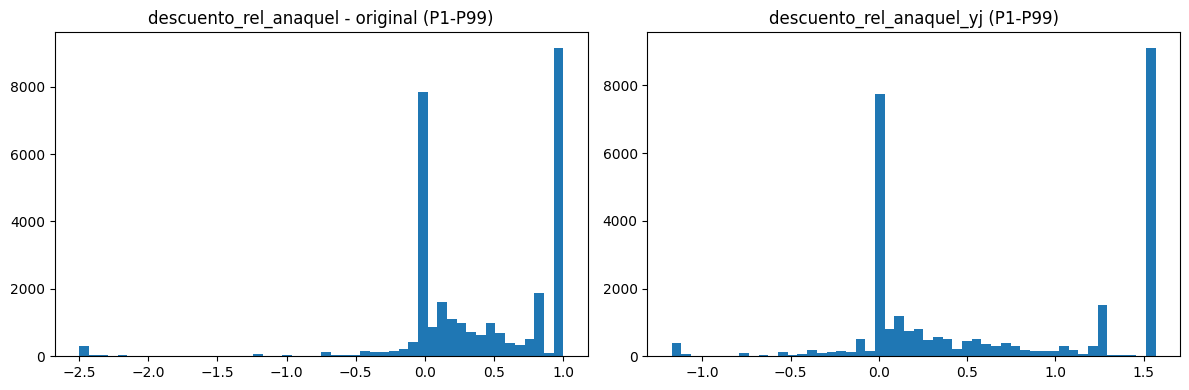

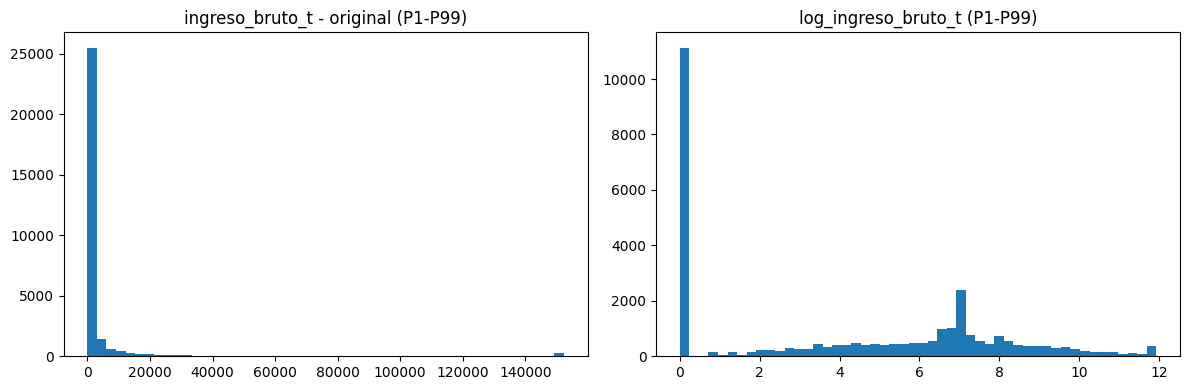

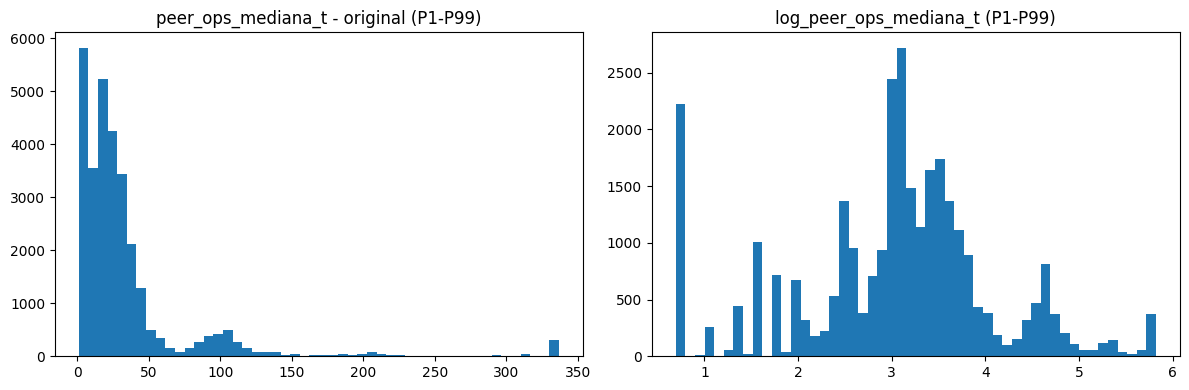

In [32]:
# Gráficas before/after para hasta tres transformaciones retenidas con mayor reducción de asimetría.
plot_candidates = transformaciones[
    transformaciones["transformacion"].isin(["log1p", "Yeo-Johnson"])
].sort_values("reduccion_abs_skew_pct", ascending=False).head(3)

for _, r in plot_candidates.iterrows():
    col = r["variable"]
    if r["transformacion"] == "log1p":
        new = f"log_{col}"
    else:
        new = f"{col}_yj"
    if new not in df_model:
        continue
    sample = df_model.loc[train_mask_df, [col, new]].dropna()
    if len(sample) > 30000:
        sample = sample.sample(30000, random_state=RANDOM_STATE)
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    axes[0].hist(sample[col].clip(lower=sample[col].quantile(.01), upper=sample[col].quantile(.99)), bins=50)
    axes[0].set_title(f"{col} - original (P1-P99)")
    axes[1].hist(sample[new].clip(lower=sample[new].quantile(.01), upper=sample[new].quantile(.99)), bins=50)
    axes[1].set_title(f"{new} (P1-P99)")
    plt.tight_layout(); plt.show()

### Diagnóstico raw vs transformada

Una transformación monotónica como `log1p` conserva el orden y, por construcción, puede presentar Spearman cercano a 1 con la variable original. Por ello, raw y transformada no se descartan entre sí con el filtro de correlación. Dataset A puede conservar ambas como candidatas; Dataset B prioriza la representación transformada cuando reduce materialmente la asimetría.


In [33]:
raw_vs_transform = transformaciones.loc[
    transformaciones["feature_transformada"].notna(),
    ["variable", "feature_transformada", "skew_raw", "skew_transformada", "kurt_raw", "kurt_transformada", "reduccion_abs_skew_pct"]
].copy()
raw_vs_transform["decision_dataset_A"] = "conservar raw + transformada como candidatas"
raw_vs_transform["decision_dataset_B"] = "preferir transformada"
display(raw_vs_transform.sort_values("reduccion_abs_skew_pct", ascending=False))


,variable,feature_transformada,skew_raw,skew_transformada,kurt_raw,kurt_transformada,reduccion_abs_skew_pct,decision_dataset_A,decision_dataset_B
17,descuento_rel_anaquel,descuento_rel_anaquel_yj,-101.863199,-0.106397,11125.369685,-0.665852,99.895549,conservar raw + transformada como candidatas,preferir transformada
3,ingreso_bruto_t,log_ingreso_bruto_t,51.447209,0.198704,6016.286032,-1.279169,99.613772,conservar raw + transformada como candidatas,preferir transformada
10,peer_ops_mediana_t,log_peer_ops_mediana_t,40.861632,-0.168861,2101.336719,0.872865,99.586748,conservar raw + transformada como candidatas,preferir transformada
0,ops_t,log_ops_t,88.012334,0.723819,10239.371890,0.338689,99.177594,conservar raw + transformada como candidatas,preferir transformada
5,ops_media_6m,log_ops_media_6m,76.653097,0.643487,7747.435698,0.323736,99.160521,conservar raw + transformada como candidatas,preferir transformada
4,ops_media_3m,log_ops_media_3m,79.623163,0.682971,8352.034456,0.350252,99.142246,conservar raw + transformada como candidatas,preferir transformada
11,peer_ops_media_t,log_peer_ops_media_t,18.018744,-0.203098,464.761158,-0.978357,98.872850,conservar raw + transformada como candidatas,preferir transformada
16,gap_anaquel,gap_anaquel_yj,-74.084258,1.129004,11313.267047,7319.047673,98.476054,conservar raw + transformada como candidatas,preferir transformada
1,tarifa_vigente_t,log_tarifa_vigente_t,124.797138,1.902496,17094.949814,3.783944,98.475529,conservar raw + transformada como candidatas,preferir transformada
2,tarifa_anaquel_t,log_tarifa_anaquel_t,66.744045,1.059027,7004.566069,0.503524,98.413301,conservar raw + transformada como candidatas,preferir transformada


## Imputación y significado del missing

La imputación se integra al pipeline y se ajusta solo en Train. El missing categórico se representa con `Desconocido`; las numéricas se imputan con mediana. La falta de historial se conserva adicionalmente mediante indicadores de disponibilidad para distinguirla de un problema de calidad.


### Conclusión FE-A5

Las transformaciones retenidas reducen de forma material la asimetría observada en Train; `log1p` reduce drásticamente el skew de operaciones, tarifas e ingreso, y Yeo-Johnson se reserva para variables con signo cuando mejora la distribución. La transformación no implica normalidad y no se elimina por su correlación monotónica con la versión raw. Dataset B prioriza estas representaciones antes de PCA.

# 11. FE-B1 — Filtrado y selección de características

**Objetivo.** Reducir redundancias y excluir variables no aptas para modelado sin eliminar señal potencial únicamente por resultados univariados.

**Justificación.** La selección se aplica de forma conservadora y en etapas: exclusiones deterministas y de leakage, constantes, variables técnicamente inválidas, redundancia extrema y ranking estadístico. Las decisiones se aprenden exclusivamente con Train. Validation y Test se reportan solo como diagnóstico fuera de muestra.


## FE-B1.1 Exclusiones deterministas


In [34]:
IDS_TRAZABILIDAD = ["id_grupo", "id_cliente", "línea_contrato", "convenio"]
EXCLUSIONES_DETERMINISTAS = {
    "operaciones_t1": "target",
    "fecha_target": "información futura / referencia del target",
    "fecha_siguiente_observada": "información futura",
    "operaciones_siguiente_observadas": "información futura",
    "gap_hacia_siguiente": "construcción del target",
    "negocio": "varianza nula observada en E1",
    "numero_operaciones": "duplicada por ops_t",
    "tarifa_vigente": "duplicada por tarifa_vigente_t",
    "tarifa_anaquel": "duplicada por tarifa_anaquel_t",
    "ingreso_bruto": "duplicada por ingreso_bruto_t",
    "seniority": "reemplazada por antiguedad_meses y seniority_invalido",
    "mes_idx": "auxiliar temporal",
    "mes_idx_siguiente": "auxiliar del target",
    "_ultimo_repricing_mes_idx": "auxiliar de ingeniería",
    "cambio_tarifa_pct": "auxiliar para construir repricing",
    "industria_peer": "auxiliar de definición peer",
    "split": "control de partición, no predictor",
    "fecha_corte": "key temporal para split, no predictor directo",
}
for col in IDS_TRAZABILIDAD:
    EXCLUSIONES_DETERMINISTAS[col] = "identificador de trazabilidad; no predictor directo"
for col in [
    c for c in df_model.columns
    if c.startswith("_ops_lag_") or c.startswith("_repricing_lag_")
    or c.startswith("_peer_") or c.startswith("_evento_repricing")
    or c in ["_bloque_continuidad", "_nuevo_bloque_continuidad"]
]:
    EXCLUSIONES_DETERMINISTAS[col] = "auxiliar de construcción de features"

tabla_exclusiones = pd.DataFrame([
    {"feature": k, "motivo_exclusion": v}
    for k, v in EXCLUSIONES_DETERMINISTAS.items() if k in df_model.columns
])
display(tabla_exclusiones)


,feature,motivo_exclusion
0,operaciones_t1,target
1,fecha_target,información futura / referencia del target
2,fecha_siguiente_observada,información futura
3,operaciones_siguiente_observadas,información futura
4,gap_hacia_siguiente,construcción del target
5,negocio,varianza nula observada en E1
6,numero_operaciones,duplicada por ops_t
7,tarifa_vigente,duplicada por tarifa_vigente_t
8,tarifa_anaquel,duplicada por tarifa_anaquel_t
9,ingreso_bruto,duplicada por ingreso_bruto_t


## FE-B1.2–B1.3 Varianza y redundancia numérica

La redundancia se diagnostica con $|\rho| \ge 0.95$, pero la selección es deliberadamente conservadora. `ops_t`, `tarifa_vigente_t`, `tarifa_anaquel_t` y `posicion_tarifaria` son features protegidas y no se eliminan automáticamente. Las parejas raw-vs-transformada tampoco compiten mediante Spearman. Cuando dos derivadas conceptualmente equivalentes son redundantes, la decisión considera primero cobertura y estabilidad temporal dentro de Train, después una diferencia material de asociación con el target y finalmente menor asimetría en Train e interpretación.

Adicionalmente, se aplica un filtro de relevancia univariada: solo se excluyen variables numéricas sin señal tanto en Spearman como en Mutual Information calculados con Train; las familias Pricing y Repricing se conservan para interacciones y las features protegidas no se eliminan.


In [35]:
# Añadir bins y transformaciones retenidas al catálogo predictivo.
for feat, familia in [
    ("posicion_tarifaria_bin", "Binning"), ("ops_t_bin", "Binning"), ("antiguedad_bin", "Binning")
]:
    if feat not in feature_catalog["feature"].values:
        feature_catalog.loc[len(feature_catalog)] = {
            "feature": feat, "familia": familia, "tipo": str(df_model[feat].dtype),
            "fuente": "derivada con parámetros Train" if feat != "posicion_tarifaria_bin" else "regla de negocio",
            "informacion_maxima": "t", "disponible_en_t": True, "usa_target": False,
            "uso": "predictor candidato", "incluir_X": True, "riesgo_leakage": "bajo",
            "pct_cobertura_train": 100 * df_model.loc[train_mask_df, feat].notna().mean(),
            "pct_cobertura_validation": 100 * df_model.loc[df_model["split"].eq("validation"), feat].notna().mean(),
            "pct_cobertura_test": 100 * df_model.loc[df_model["split"].eq("test"), feat].notna().mean(),
        }

for orig, feat in TRANSFORM_MAP.items():
    if feat not in df_model.columns or feat in feature_catalog["feature"].values:
        continue
    familia_orig = feature_catalog.loc[feature_catalog["feature"].eq(orig), "familia"]
    familia_orig = familia_orig.iloc[0] if len(familia_orig) else "Transformación"
    feature_catalog.loc[len(feature_catalog)] = {
        "feature": feat, "familia": familia_orig, "tipo": str(df_model[feat].dtype),
        "fuente": f"transformación de {orig} ajustada/definida con Train", "informacion_maxima": "t",
        "disponible_en_t": True, "usa_target": False, "uso": "predictor candidato", "incluir_X": True,
        "riesgo_leakage": "controlado: parámetros Train" if orig in yeo_transformers else "bajo",
        "pct_cobertura_train": 100 * df_model.loc[train_mask_df, feat].notna().mean(),
        "pct_cobertura_validation": 100 * df_model.loc[df_model["split"].eq("validation"), feat].notna().mean(),
        "pct_cobertura_test": 100 * df_model.loc[df_model["split"].eq("test"), feat].notna().mean(),
    }

# Categóricas y flags.
CATEGORICAS_LOW = [
    "producto", "industria", "moneda", "direccion_ultimo_repricing", "peer_nivel", "trimestre",
    "posicion_tarifaria_bin", "ops_t_bin", "antiguedad_bin"
]
CATEGORICAS_LOW = [c for c in CATEGORICAS_LOW if c in df_model.columns]
CATEGORICA_SUBPRODUCTO = ["subproducto"]

BINARIAS = [
    "missing_moneda", "missing_industria", "seniority_invalido", "anaquel_valido",
    "repricing_flag_t", "repricing_ultimo_mes", "peer_calificado_t",
    "ops_lag_1_disponible", "ops_lag_2_disponible", "ops_lag_3_disponible", "ops_lag_6_disponible"
]
BINARIAS = [c for c in BINARIAS if c in df_model.columns]
CICLICAS = ["mes_sin", "mes_cos"]

candidatas_catalogo = feature_catalog["feature"].drop_duplicates().tolist()
NUMERICAS_CANDIDATAS = [
    c for c in candidatas_catalogo
    if c in df_model.columns
    and pd.api.types.is_numeric_dtype(df_model[c])
    and c not in BINARIAS + CICLICAS
    and c not in EXCLUSIONES_DETERMINISTAS
]

train_num = df_model.loc[train_mask_df, NUMERICAS_CANDIDATAS + ["operaciones_t1"]].replace([np.inf, -np.inf], np.nan)
target_assoc = {}
skew_train = {c: abs(train_num[c].skew()) for c in NUMERICAS_CANDIDATAS}
for c in NUMERICAS_CANDIDATAS:
    tmp = train_num[[c, "operaciones_t1"]].dropna()
    target_assoc[c] = abs(tmp[c].corr(tmp["operaciones_t1"], method="spearman")) if len(tmp) >= 3 and tmp[c].nunique() >= 2 else np.nan

# Coberturas de todos los splits se reportan como diagnóstico; solo Train participa en selección.
coverage = {}
coverage_train_monthly = {}
for c in NUMERICAS_CANDIDATAS:
    coverage[c] = {
        split: 100 * df_model.loc[df_model["split"].eq(split), c].notna().mean()
        for split in ["train", "validation", "test"]
    }
    mensual = (
        df_model.loc[train_mask_df, ["fecha_corte", c]]
        .assign(_disp=lambda d: d[c].notna().astype(float))
        .groupby("fecha_corte", observed=True)["_disp"].mean()
        .mul(100)
    )
    coverage_train_monthly[c] = {
        "p10": float(mensual.quantile(.10)) if len(mensual) else np.nan,
        "min": float(mensual.min()) if len(mensual) else np.nan,
        "median": float(mensual.median()) if len(mensual) else np.nan,
    }

FEATURES_PROTEGIDAS = {"ops_t", "tarifa_vigente_t", "tarifa_anaquel_t", "posicion_tarifaria"}
RAW_TRANSFORM_PAIRS = {frozenset([raw, trans]) for raw, trans in TRANSFORM_MAP.items() if trans in df_model.columns}

corr_num = train_num[NUMERICAS_CANDIDATAS].corr(method="spearman").abs()
upper = corr_num.where(np.triu(np.ones(corr_num.shape), k=1).astype(bool))
redundancia_rows = []

# Estas exclusiones provienen de diagnósticos de Train en la propia familia Vinculación.
drop_corr = set(c for c in VINCULACION_EXCLUIR_DATASET_A if c in NUMERICAS_CANDIDATAS)
DROP_CORR_REASON = {c: VINCULACION_EXCLUSION_REASON.get(c, "decisión documentada de Vinculación") for c in drop_corr}

for col_b in upper.columns:
    for col_a, rho in upper[col_b].dropna().items():
        if rho < .95 or col_a in drop_corr or col_b in drop_corr:
            continue

        pair = frozenset([col_a, col_b])
        a = target_assoc.get(col_a, np.nan)
        b = target_assoc.get(col_b, np.nan)
        train_a = coverage[col_a]["train"]
        train_b = coverage[col_b]["train"]
        p10_a = coverage_train_monthly[col_a]["p10"]
        p10_b = coverage_train_monthly[col_b]["p10"]

        base_row = {
            "feature_A": col_a, "feature_B": col_b, "rho": rho,
            "spearman_A": a, "spearman_B": b,
            "cobertura_train_A": train_a, "cobertura_train_B": train_b,
            "cobertura_train_p10_A": p10_a, "cobertura_train_p10_B": p10_b,
            # Validation/Test son diagnóstico exclusivamente y nunca intervienen en la decisión.
            "cobertura_val_A": coverage[col_a]["validation"], "cobertura_val_B": coverage[col_b]["validation"],
            "cobertura_test_A": coverage[col_a]["test"], "cobertura_test_B": coverage[col_b]["test"],
        }

        # Una transformación monotónica no compite contra su variable raw mediante Spearman.
        if pair in RAW_TRANSFORM_PAIRS:
            redundancia_rows.append({
                **base_row,
                "decision": "mantener ambas: raw vs transformada se evalúa por asimetría/uso",
                "motivo": "transformación monotónica",
            })
            continue

        # Features estructurales de negocio no se eliminan automáticamente por correlación.
        if col_a in FEATURES_PROTEGIDAS or col_b in FEATURES_PROTEGIDAS:
            redundancia_rows.append({
                **base_row,
                "decision": "mantener ambas",
                "motivo": "al menos una feature está protegida por valor estructural/de negocio",
            })
            continue

        # Jerarquía de Train: cobertura temporal > diferencia material de señal > simplicidad.
        if abs(np.nan_to_num(p10_a, nan=-1) - np.nan_to_num(p10_b, nan=-1)) >= 10:
            keep, drop = (col_a, col_b) if np.nan_to_num(p10_a, nan=-1) > np.nan_to_num(p10_b, nan=-1) else (col_b, col_a)
            motivo = "mayor cobertura P10 mensual dentro de Train"
        elif abs(train_a - train_b) >= 10:
            keep, drop = (col_a, col_b) if train_a > train_b else (col_b, col_a)
            motivo = "mayor cobertura global dentro de Train"
        elif abs(np.nan_to_num(a, nan=-1) - np.nan_to_num(b, nan=-1)) >= 0.01:
            keep, drop = (col_a, col_b) if np.nan_to_num(a, nan=-1) > np.nan_to_num(b, nan=-1) else (col_b, col_a)
            motivo = "asociación con target materialmente mayor en Train"
        else:
            keep, drop = sorted([col_a, col_b], key=lambda x: (np.nan_to_num(skew_train.get(x), nan=np.inf), x))
            motivo = "señal y cobertura Train equivalentes; se prioriza menor asimetría en Train"

        drop_corr.add(drop)
        DROP_CORR_REASON[drop] = motivo
        redundancia_rows.append({
            **base_row,
            "decision": f"conservar {keep}; excluir {drop}",
            "motivo": motivo,
        })

redundancia = pd.DataFrame(redundancia_rows)
display(redundancia.head(80))
# Filtro de relevancia univariada: solo se excluyen numéricas sin señal en Spearman ni en Mutual Information (Train).
UMBRAL_RELEVANCIA_RHO = 0.01
UMBRAL_RELEVANCIA_MI = 0.01
FAMILIAS_INTERACCION = {"Pricing", "Repricing"}
mi_train = utilidad.set_index("feature")["mutual_information"]
familia_feature = feature_catalog.set_index("feature")["familia"].to_dict()
RELEVANCIA_EXCLUIDAS = []
relevancia_rows = []
for c in NUMERICAS_CANDIDATAS:
    if c in drop_corr or c in FEATURES_PROTEGIDAS or c in core_interaccion:
        continue
    if familia_feature.get(c) in FAMILIAS_INTERACCION:
        continue
    rho_c = target_assoc.get(c, np.nan)
    mi_c = mi_train.get(c, np.nan)
    if pd.notna(rho_c) and pd.notna(mi_c) and rho_c < UMBRAL_RELEVANCIA_RHO and mi_c < UMBRAL_RELEVANCIA_MI:
        drop_corr.add(c)
        RELEVANCIA_EXCLUIDAS.append(c)
        DROP_CORR_REASON[c] = f"sin señal univariada en Train (|Spearman|={rho_c:.4f}; MI={mi_c:.4f})"
        relevancia_rows.append({"feature": c, "familia": familia_feature.get(c), "abs_spearman_train": rho_c, "mutual_information_train": mi_c})
display(pd.DataFrame(relevancia_rows))
print("Features numéricas excluidas por relevancia univariada:", len(RELEVANCIA_EXCLUIDAS))
print("Features numéricas excluidas por redundancia/baja prioridad:", len(drop_corr))
print("Las coberturas de Validation y Test se reportan exclusivamente como diagnóstico fuera de muestra y no intervienen en la selección de características.")
SELECCION_USA_TEST = False

NUMERICAS_FINALES = [c for c in NUMERICAS_CANDIDATAS if c not in drop_corr]
for feat in FEATURES_PROTEGIDAS:
    if feat in NUMERICAS_CANDIDATAS and feat not in NUMERICAS_FINALES:
        raise RuntimeError(f"Feature protegida eliminada indebidamente: {feat}")

# Auditoría final de leakage tras binning/transformaciones.
control_leakage_final = pd.concat([
    feature_catalog[[
        "feature", "familia", "fuente", "informacion_maxima", "disponible_en_t",
        "usa_target", "uso", "incluir_X", "riesgo_leakage"
    ]],
    diagnostic_catalog[[
        "feature", "familia", "fuente", "informacion_maxima", "disponible_en_t",
        "usa_target", "uso", "incluir_X", "riesgo_leakage"
    ]],
], ignore_index=True).drop_duplicates(subset=["feature"], keep="last")
display(control_leakage_final)


,feature_A,feature_B,rho,spearman_A,spearman_B,cobertura_train_A,cobertura_train_B,cobertura_train_p10_A,cobertura_train_p10_B,cobertura_val_A,cobertura_val_B,cobertura_test_A,cobertura_test_B,decision,motivo
0,ops_t,ops_lag_3,0.958202,0.937558,0.929941,100.000000,78.869609,100.000000,25.112036,100.000000,57.764715,100.000000,86.237523,mantener ambas,al menos una feature está protegida por valor estructural/de negocio
1,ops_lag_3,ops_lag_6,0.959032,0.929941,0.925327,78.869609,63.129576,25.112036,0.000000,57.764715,41.498000,86.237523,59.208051,conservar ops_lag_3; excluir ops_lag_6,mayor cobertura P10 mensual dentro de Train
2,ops_t,ops_media_3m,0.974427,0.937558,0.961735,100.000000,84.851624,100.000000,86.339208,100.000000,70.642952,100.000000,89.823086,mantener ambas,al menos una feature está protegida por valor estructural/de negocio
3,ops_lag_1,ops_media_3m,0.977427,0.940520,0.961735,91.643729,84.851624,92.456310,86.339208,84.453400,70.642952,94.348215,89.823086,conservar ops_media_3m; excluir ops_lag_1,asociación con target materialmente mayor en Train
4,ops_lag_2,ops_media_3m,0.973550,0.956493,0.961735,84.851624,84.851624,86.339208,86.339208,70.642952,70.642952,89.823086,89.823086,conservar ops_media_3m; excluir ops_lag_2,señal y cobertura Train equivalentes; se prioriza menor asimetría en Train
5,ops_lag_3,ops_media_3m,0.961535,0.929941,0.961735,78.869609,84.851624,25.112036,86.339208,57.764715,70.642952,86.237523,89.823086,conservar ops_media_3m; excluir ops_lag_3,mayor cobertura P10 mensual dentro de Train
6,ops_t,ops_mediana_3m,0.973865,0.937558,0.957805,100.000000,84.851624,100.000000,86.339208,100.000000,70.642952,100.000000,89.823086,mantener ambas,al menos una feature está protegida por valor estructural/de negocio
7,ops_media_3m,ops_mediana_3m,0.993820,0.961735,0.957805,84.851624,84.851624,86.339208,86.339208,70.642952,70.642952,89.823086,89.823086,conservar ops_media_3m; excluir ops_mediana_3m,señal y cobertura Train equivalentes; se prioriza menor asimetría en Train
8,ops_t,ops_media_6m,0.970005,0.937558,0.961765,100.000000,68.090698,100.000000,0.000000,100.000000,43.677534,100.000000,70.201174,mantener ambas,al menos una feature está protegida por valor estructural/de negocio
9,ops_media_3m,ops_media_6m,0.995102,0.961735,0.961765,84.851624,68.090698,86.339208,0.000000,70.642952,43.677534,89.823086,70.201174,conservar ops_media_3m; excluir ops_media_6m,mayor cobertura P10 mensual dentro de Train


,feature,familia,abs_spearman_train,mutual_information_train
0,grupo_hist_n_3,Vinculación,0.002039,0.000000
1,grupo_hist_n_6,Vinculación,0.007890,0.006595


Features numéricas excluidas por relevancia univariada: 2
Features numéricas excluidas por redundancia/baja prioridad: 28
Las coberturas de Validation y Test se reportan exclusivamente como diagnóstico fuera de muestra y no intervienen en la selección de características.


,feature,familia,fuente,informacion_maxima,disponible_en_t,usa_target,uso,incluir_X,riesgo_leakage
0,ops_t,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
1,ops_lag_1,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
2,ops_lag_2,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
3,ops_lag_3,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
4,ops_lag_6,Historia transaccional,información disponible hasta t,t,True,False,predictor candidato,True,bajo
...,...,...,...,...,...,...,...,...,...
101,pct_delta_tarifa_1m_yj,Pricing,transformación de pct_delta_tarifa_1m ajustada/definida con Train,t,True,False,predictor candidato,True,controlado: parámetros Train
102,gap_anaquel_yj,Pricing,transformación de gap_anaquel ajustada/definida con Train,t,True,False,predictor candidato,True,controlado: parámetros Train
103,descuento_rel_anaquel_yj,Pricing,transformación de descuento_rel_anaquel ajustada/definida con Train,t,True,False,predictor candidato,True,controlado: parámetros Train
104,ratio_retencion_ops,Diagnóstico Vinculación,operaciones_t1 / ops_t,t+1,False,True,solo diagnóstico,False,alto si entrara a X


## Construcción del preprocesador base y FE-B1.2 VarianceThreshold

Dataset A es deliberadamente **interpretable y rico**. La selección previa elimina leakage, constantes e invalidaciones técnicas, pero no intenta minimizar columnas agresivamente. Las numéricas se imputan con la mediana y se escalan con `RobustScaler`; OHE, flags y variables cíclicas permanecen fuera del escalamiento.


In [36]:
def crear_ohe(min_frequency=None):
    kwargs = {"handle_unknown": "infrequent_if_exist" if min_frequency else "ignore"}
    if min_frequency:
        kwargs["min_frequency"] = min_frequency
    try:
        return OneHotEncoder(sparse_output=True, **kwargs)
    except TypeError:  # Compatibilidad con versiones anteriores de scikit-learn.
        return OneHotEncoder(sparse=True, **kwargs)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", RobustScaler()),
])
binary_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
])
cyclic_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
])
cat_low_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Desconocido")),
    ("ohe", crear_ohe()),
])
cat_sub_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Desconocido")),
    ("ohe", crear_ohe(SUBPRODUCTO_MIN_FREQUENCY)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, NUMERICAS_FINALES),
    ("binary", binary_pipe, BINARIAS),
    ("cyclic", cyclic_pipe, CICLICAS),
    ("cat_low", cat_low_pipe, CATEGORICAS_LOW),
    ("subproducto", cat_sub_pipe, CATEGORICA_SUBPRODUCTO),
], remainder="drop", sparse_threshold=0.3, verbose_feature_names_out=True)

pipeline_a = Pipeline([
    ("preprocessor", preprocessor),
    ("variance", VarianceThreshold(threshold=0.0)),
])

PREDICTOR_INPUTS = list(dict.fromkeys(NUMERICAS_FINALES + BINARIAS + CICLICAS + CATEGORICAS_LOW + CATEGORICA_SUBPRODUCTO))

train_rows = df_model["split"].eq("train")
val_rows = df_model["split"].eq("validation")
test_rows = df_model["split"].eq("test")

X_train_df = df_model.loc[train_rows, PREDICTOR_INPUTS].copy()
X_val_df = df_model.loc[val_rows, PREDICTOR_INPUTS].copy()
X_test_df = df_model.loc[test_rows, PREDICTOR_INPUTS].copy()
y_train = df_model.loc[train_rows, "operaciones_t1"].astype(float)
y_val = df_model.loc[val_rows, "operaciones_t1"].astype(float)
y_test = df_model.loc[test_rows, "operaciones_t1"].astype(float)

X_train_A = pipeline_a.fit_transform(X_train_df)
X_val_A = pipeline_a.transform(X_val_df)
X_test_A = pipeline_a.transform(X_test_df)

pre_names = np.asarray(pipeline_a.named_steps["preprocessor"].get_feature_names_out(), dtype=object)
mask_var = pipeline_a.named_steps["variance"].get_support()
feature_names_A = pre_names[mask_var]

print("Dataset A:", X_train_A.shape, X_val_A.shape, X_test_A.shape)
print("Features antes de VarianceThreshold:", len(pre_names))
print("Features constantes eliminadas:", int((~mask_var).sum()))
print("Features después de VarianceThreshold:", len(feature_names_A))

Dataset A: (498093, 387) (99012, 387) (97279, 387)
Features antes de VarianceThreshold: 387
Features constantes eliminadas: 0
Features después de VarianceThreshold: 387


## FE-B1.4 Relevancia estadística

Se triangulan Spearman, Mutual Information y `f_regression`. La selección es conservadora: estos indicadores sirven para priorizar y documentar, no para eliminar automáticamente features potencialmente útiles en interacciones no lineales.


In [37]:
# Muestra reproducible limitada por número máximo de celdas densas.
n_features_encoded = X_train_A.shape[1]
max_cells = 5_000_000
n_rank = int(min(len(y_train), 30000, max(3000, max_cells // max(n_features_encoded,1))))
rng = np.random.default_rng(RANDOM_STATE)
idx = np.sort(rng.choice(len(y_train), size=n_rank, replace=False)) if len(y_train) > n_rank else np.arange(len(y_train))

X_rank_sparse = X_train_A[idx]
X_rank = X_rank_sparse.toarray() if sparse.issparse(X_rank_sparse) else np.asarray(X_rank_sparse)
y_rank = y_train.iloc[idx].to_numpy()

# Máscara de features discretas para MI: one-hot y flags binarios.
discrete_mask = np.array([
    str(name).startswith("cat_low__") or str(name).startswith("subproducto__") or str(name).startswith("binary__")
    for name in feature_names_A
])

mi_encoded = mutual_info_regression(
    X_rank, y_rank, discrete_features=discrete_mask, random_state=RANDOM_STATE
)
f_scores, f_pvalues = f_regression(X_rank, y_rank)

# Spearman se asigna a columnas numéricas/cíclicas/binarias cuando puede mapearse a la feature fuente.
spearman_source = {}
for c in NUMERICAS_FINALES + CICLICAS + BINARIAS:
    tmp = df_model.loc[train_rows, [c, "operaciones_t1"]].replace([np.inf,-np.inf], np.nan).dropna()
    spearman_source[c] = tmp[c].corr(tmp["operaciones_t1"], method="spearman") if len(tmp) >= 3 and tmp[c].nunique() >= 2 else np.nan

def fuente_desde_nombre(nombre):
    s = str(nombre)
    for prefix in ["num__", "binary__", "cyclic__"]:
        if s.startswith(prefix):
            return s[len(prefix):]
    return None

ranking = pd.DataFrame({
    "feature": feature_names_A,
    "mutual_information": mi_encoded,
    "f_score": f_scores,
    "p_value": f_pvalues,
})
ranking["feature_fuente"] = ranking["feature"].map(fuente_desde_nombre)
ranking["spearman"] = ranking["feature_fuente"].map(spearman_source)
ranking["abs_spearman"] = ranking["spearman"].abs()
ranking["ranking_spearman"] = ranking["abs_spearman"].rank(ascending=False, method="average")
ranking["ranking_MI"] = ranking["mutual_information"].rank(ascending=False, method="average")
ranking["ranking_f"] = ranking["f_score"].rank(ascending=False, method="average")
ranking["ranking_integrado"] = ranking[["ranking_spearman", "ranking_MI", "ranking_f"]].mean(axis=1, skipna=True)
ranking = ranking.sort_values("ranking_integrado")
display(ranking.head(40))

print(f"Ranking calculado sobre {n_rank:,} observaciones de Train y {n_features_encoded:,} features finales codificadas.")

,feature,mutual_information,f_score,p_value,feature_fuente,spearman,abs_spearman,ranking_spearman,ranking_MI,ranking_f,ranking_integrado
0,num__ops_t,1.826689,19288.179476,0.000000e+00,ops_t,0.937558,0.937558,1.5,2.0,1.0,1.500000
1,num__ops_std_3m,0.722154,10462.854884,0.000000e+00,ops_std_3m,0.848397,0.848397,3.0,4.0,2.0,3.000000
44,num__log_ops_t,1.877214,380.147894,1.821507e-83,log_ops_t,0.937558,0.937558,1.5,1.0,8.0,3.500000
42,num__ops_vs_peer,0.985279,3589.469844,0.000000e+00,ops_vs_peer,0.843998,0.843998,4.0,3.0,5.0,4.000000
33,num__share_ops_grupo,0.495898,176.984822,4.051752e-40,share_ops_grupo,0.684433,0.684433,5.0,8.0,11.0,8.000000
12,num__ingreso_bruto_t,0.476373,415.986210,4.920503e-91,ingreso_bruto_t,0.303973,0.303973,9.5,10.0,7.0,8.833333
128,cat_low__ops_t_bin_Q_5,0.409877,129.546764,7.144982e-30,None,NaN,NaN,NaN,12.0,13.0,12.500000
37,num__peer_ops_media_t,0.402696,119.283206,1.199273e-27,peer_ops_media_t,0.275962,0.275962,11.5,13.0,15.0,13.166667
35,num__share_subproducto_ops_grupo,0.352022,28.903802,7.738677e-08,share_subproducto_ops_grupo,0.510470,0.510470,6.0,14.0,21.0,13.666667
51,num__log_peer_ops_media_t,0.465708,40.778551,1.763336e-10,log_peer_ops_media_t,0.275962,0.275962,11.5,11.0,19.0,13.833333


Ranking calculado sobre 12,919 observaciones de Train y 387 features finales codificadas.


### Checkpoint 12 — Conteo de features


,Concepto,Cantidad,Interpretación
0,Columnas disponibles en df_model,164,Universo de trabajo antes de seleccionar predictores
1,Exclusiones deterministas documentadas,56,"IDs, target, auxiliares, duplicados de fuente y controles"
2,Columnas de fuente no excluidas determinísticamente,108,No equivale aún al feature set final; incluye variables derivadas y de diagnóstico


,Etapa,Entrada,Eliminadas,Salida,Criterio
0,Features candidatas del catálogo,104,0,104,familias derivadas y originales aptas para evaluación
1,Numéricas candidatas,85,0,85,subconjunto numérico sujeto a selección
2,Decisiones explícitas de Vinculación,85,3,82,redundancia exacta/casi exacta o baja variabilidad aprendida con Train
3,Redundancia numérica adicional,82,25,57,|rho| >= 0.95 con decisión basada exclusivamente en Train
4,Variables de entrada al preprocesador,80,0,80,numéricas retenidas + binarias + cíclicas + categóricas
5,Columnas después de encoding,387,0,387,expansión one-hot; no es una etapa sustractiva
6,VarianceThreshold,387,0,387,elimina únicamente columnas constantes en Train


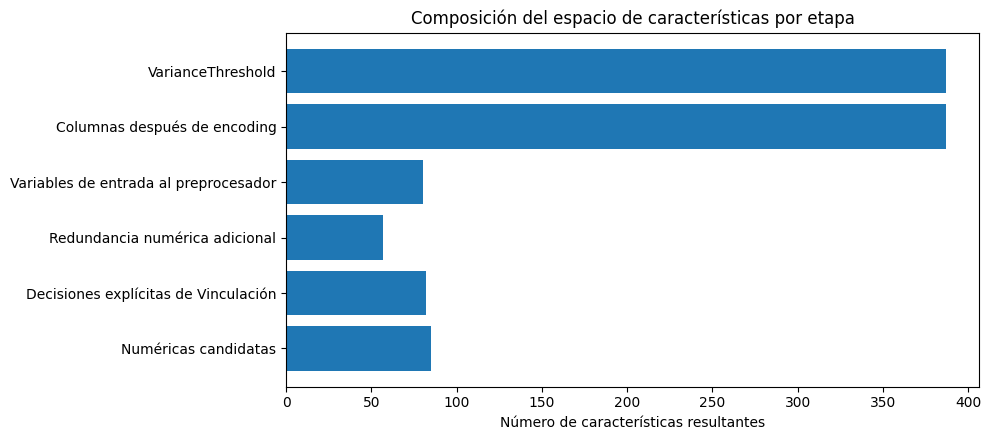

In [38]:
# El conteo se separa en dos universos para evitar mezclar columnas fuente con features derivadas.
tabla_columnas_fuente = pd.DataFrame([
    ["Columnas disponibles en df_model", len(df_model.columns), "Universo de trabajo antes de seleccionar predictores"],
    ["Exclusiones deterministas documentadas", len(tabla_exclusiones), "IDs, target, auxiliares, duplicados de fuente y controles"],
    ["Columnas de fuente no excluidas determinísticamente", len(df_model.columns) - len(tabla_exclusiones), "No equivale aún al feature set final; incluye variables derivadas y de diagnóstico"],
], columns=["Concepto", "Cantidad", "Interpretación"])
display(tabla_columnas_fuente)

n_vinc_excl = len([c for c in VINCULACION_EXCLUIR_DATASET_A if c in NUMERICAS_CANDIDATAS])
n_corr_adicional = len(drop_corr) - n_vinc_excl

tabla_feature_engineering = pd.DataFrame([
    ["Features candidatas del catálogo", len(candidatas_catalogo), 0, len(candidatas_catalogo), "familias derivadas y originales aptas para evaluación"],
    ["Numéricas candidatas", len(NUMERICAS_CANDIDATAS), 0, len(NUMERICAS_CANDIDATAS), "subconjunto numérico sujeto a selección"],
    ["Decisiones explícitas de Vinculación", len(NUMERICAS_CANDIDATAS), n_vinc_excl, len(NUMERICAS_CANDIDATAS)-n_vinc_excl, "redundancia exacta/casi exacta o baja variabilidad aprendida con Train"],
    ["Redundancia numérica adicional", len(NUMERICAS_CANDIDATAS)-n_vinc_excl, n_corr_adicional, len(NUMERICAS_FINALES), "|rho| >= 0.95 con decisión basada exclusivamente en Train"],
    ["Variables de entrada al preprocesador", len(PREDICTOR_INPUTS), 0, len(PREDICTOR_INPUTS), "numéricas retenidas + binarias + cíclicas + categóricas"],
    ["Columnas después de encoding", len(pre_names), 0, len(pre_names), "expansión one-hot; no es una etapa sustractiva"],
    ["VarianceThreshold", len(pre_names), int((~mask_var).sum()), len(feature_names_A), "elimina únicamente columnas constantes en Train"],
], columns=["Etapa", "Entrada", "Eliminadas", "Salida", "Criterio"])
display(tabla_feature_engineering)

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_tab = tabla_feature_engineering.loc[
    tabla_feature_engineering["Etapa"].isin(["Numéricas candidatas", "Decisiones explícitas de Vinculación", "Redundancia numérica adicional", "Variables de entrada al preprocesador", "Columnas después de encoding", "VarianceThreshold"])
]
ax.barh(plot_tab["Etapa"], plot_tab["Salida"])
ax.set_title("Composición del espacio de características por etapa")
ax.set_xlabel("Número de características resultantes")
plt.tight_layout(); plt.show()


### Conclusión FE-B1

La selección final es deliberadamente conservadora: se eliminan leakage, auxiliares, constantes, variables técnicamente inválidas y redundancias extremas justificadas; la relevancia univariada sirve para priorizar, no para descartar por sí sola. Las decisiones de cobertura, estabilidad y asociación se toman exclusivamente con Train. Validation y Test se muestran como diagnóstico fuera de muestra y no participan en la selección.

# 12. FE-B2 — Extracción de características mediante PCA

**Objetivo.** Evaluar una representación alternativa que comprima el bloque numérico sin mezclar identificadores ni variables categóricas one-hot dentro de PCA.

**Justificación.** El bloque numérico se imputa, transforma para reducir asimetría, estandariza con `StandardScaler` y después se proyecta mediante PCA, todo ajustado solo con Train. Dataset B se conserva como alternativa a Dataset A; E2 cuantifica compresión e interpreta loadings, pero no decide qué representación predice mejor.


,componente,varianza_explicada,varianza_acumulada
0,1,0.131081,0.131081
1,2,0.065339,0.196420
2,3,0.062003,0.258423
3,4,0.055125,0.313548
4,5,0.051265,0.364813
5,6,0.045259,0.410072
6,7,0.044316,0.454388
7,8,0.036062,0.490450
8,9,0.033799,0.524249
9,10,0.032722,0.556971


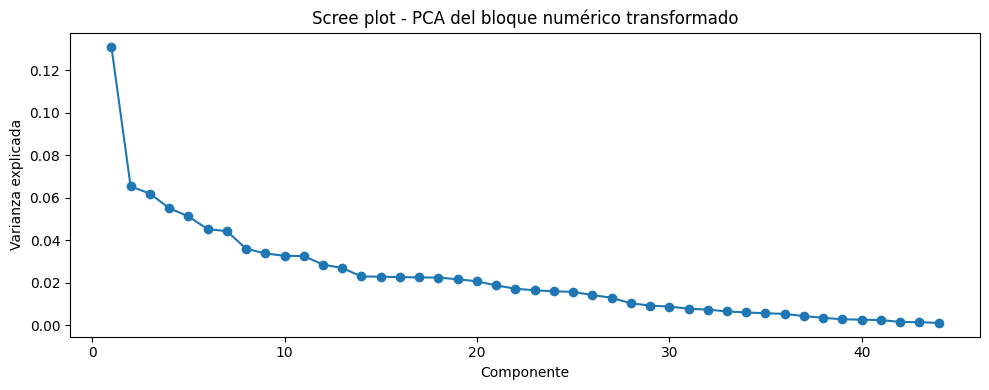

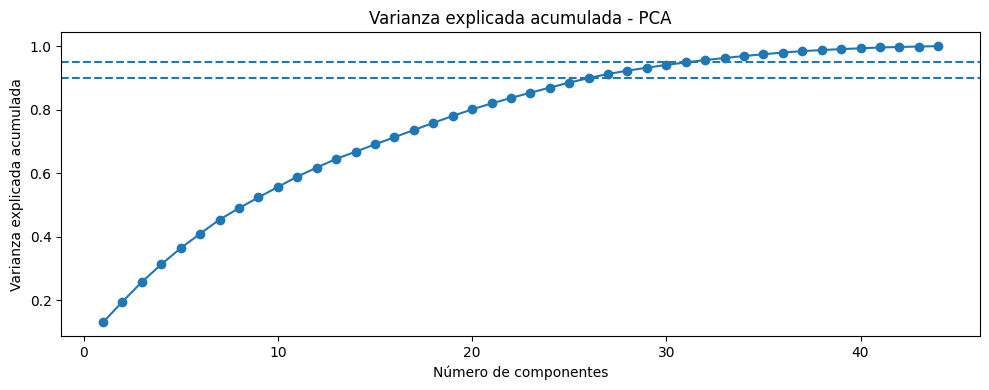

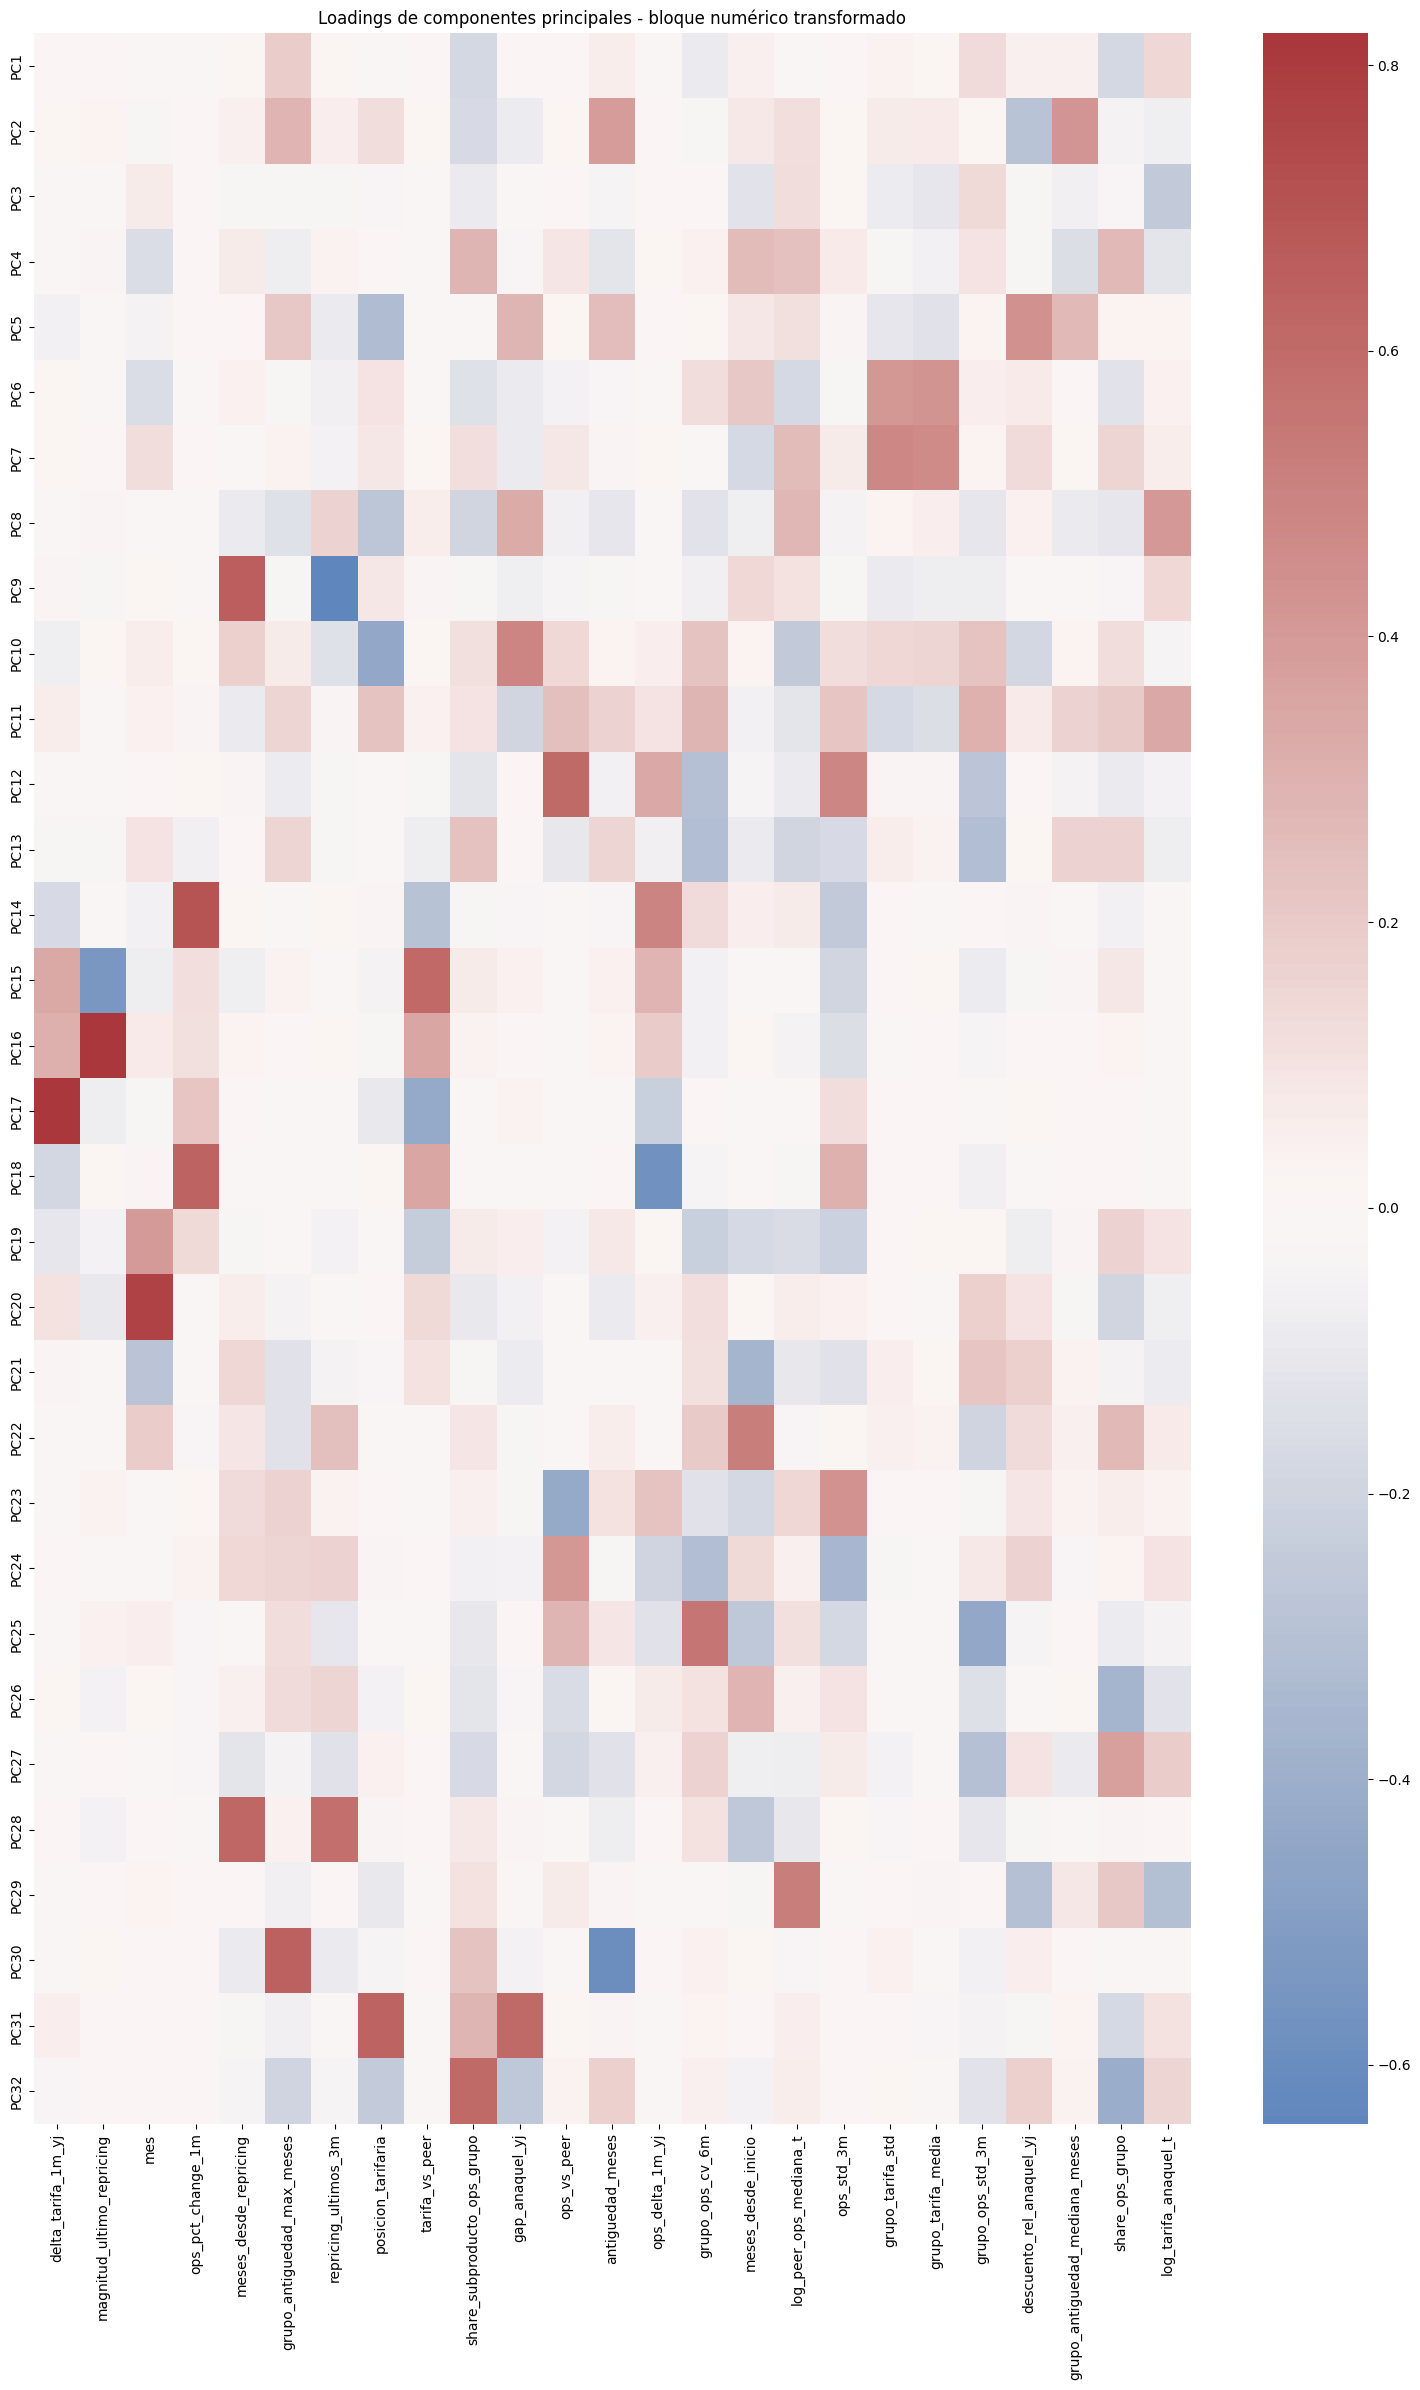

,componente,feature,loading,abs_loading
0,PC1,grupo_n_productos_hist,0.356129,0.356129
1,PC1,log_grupo_n_convenios,0.351630,0.351630
2,PC1,grupo_n_subproductos_hist,0.347580,0.347580
3,PC1,grupo_n_unidades,0.323899,0.323899
4,PC1,grupo_n_tarifas,0.310519,0.310519
...,...,...,...,...
155,PC9,meses_desde_repricing,0.659306,0.659306
156,PC9,repricing_ultimos_3m,-0.641207,0.641207
157,PC9,meses_desde_inicio,0.145046,0.145046
158,PC9,log_tarifa_anaquel_t,0.144662,0.144662


In [39]:
# Selección de una única representación por variable fuente para PCA.
transform_values = set(TRANSFORM_MAP.values())
PCA_NUMERICAS = []
for c in NUMERICAS_FINALES:
    if c in transform_values:
        # Se añadirá al procesar su variable fuente.
        continue
    if c in TRANSFORM_MAP and TRANSFORM_MAP[c] in NUMERICAS_FINALES:
        PCA_NUMERICAS.append(TRANSFORM_MAP[c])
    else:
        PCA_NUMERICAS.append(c)
PCA_NUMERICAS = list(dict.fromkeys(PCA_NUMERICAS))
# Excluir del PCA columnas completamente vacías en Train; no contienen varianza estimable.
PCA_NUMERICAS_VALIDAS = [c for c in PCA_NUMERICAS if X_train_df[c].notna().any()]
PCA_NUMERICAS_SIN_DATOS = [c for c in PCA_NUMERICAS if c not in PCA_NUMERICAS_VALIDAS]
if PCA_NUMERICAS_SIN_DATOS:
    print("Numéricas excluidas de PCA por ausencia total en Train:", PCA_NUMERICAS_SIN_DATOS)

num_pca_base = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
])
Xnum_train = num_pca_base.fit_transform(X_train_df[PCA_NUMERICAS_VALIDAS])

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(Xnum_train)
exp = pca_full.explained_variance_ratio_
cum = np.cumsum(exp)
n90 = int(np.searchsorted(cum, .90) + 1)
n95 = int(np.searchsorted(cum, .95) + 1)

pca_summary = pd.DataFrame({
    "componente": np.arange(1, len(exp) + 1),
    "varianza_explicada": exp,
    "varianza_acumulada": cum,
})
display(pca_summary.head(20))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pca_summary["componente"], pca_summary["varianza_explicada"], marker="o")
ax.set_title("Scree plot - PCA del bloque numérico transformado")
ax.set_xlabel("Componente")
ax.set_ylabel("Varianza explicada")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pca_summary["componente"], pca_summary["varianza_acumulada"], marker="o")
ax.axhline(.90, linestyle="--")
ax.axhline(.95, linestyle="--")
ax.set_title("Varianza explicada acumulada - PCA")
ax.set_xlabel("Número de componentes")
ax.set_ylabel("Varianza explicada acumulada")
plt.tight_layout(); plt.show()

n_load = min(max(n95, 4), pca_full.components_.shape[0])
loadings = pd.DataFrame(
    pca_full.components_[:n_load],
    index=[f"PC{i+1}" for i in range(n_load)],
    columns=PCA_NUMERICAS_VALIDAS,
)
cols_load = loadings.abs().max(axis=0).sort_values(ascending=False).head(min(25, loadings.shape[1])).index
fig, ax = plt.subplots(figsize=(15, max(4, n_load * .75)))
sns.heatmap(loadings[cols_load], center=0, cmap="vlag", ax=ax)
ax.set_title("Loadings de componentes principales - bloque numérico transformado")
plt.tight_layout(); plt.show()

# Top 5 loadings absolutos por componente para interpretación.
loadings_long = (
    loadings.reset_index(names="componente")
    .melt(id_vars="componente", var_name="feature", value_name="loading")
)
loadings_long["abs_loading"] = loadings_long["loading"].abs()
pca_loadings_top = (
    loadings_long.sort_values(["componente", "abs_loading"], ascending=[True, False])
    .groupby("componente", observed=True)
    .head(5)
    .reset_index(drop=True)
)
display(pca_loadings_top)


### Checkpoint 13 — ¿PCA aporta compresión?


In [40]:
compresion_pca = pd.Series({
    "n_variables_numericas_dataset_A": len(NUMERICAS_FINALES),
    "n_variables_numericas_entrada_PCA": len(PCA_NUMERICAS_VALIDAS),
    "n_componentes_90": n90,
    "n_componentes_95": n95,
    "reduccion_bloque_numerico_90_pct": 100 * (1 - n90 / max(len(PCA_NUMERICAS_VALIDAS), 1)),
    "reduccion_bloque_numerico_95_pct": 100 * (1 - n95 / max(len(PCA_NUMERICAS_VALIDAS), 1)),
})
display(compresion_pca.to_frame("valor"))


,valor
n_variables_numericas_dataset_A,57.000000
n_variables_numericas_entrada_PCA,44.000000
n_componentes_90,27.000000
n_componentes_95,32.000000
reduccion_bloque_numerico_90_pct,38.636364
reduccion_bloque_numerico_95_pct,27.272727


## Construcción de Dataset B con PCA

Dataset B retiene al menos 95% de la varianza del bloque numérico **transformado y estandarizado**. Las variables binarias, cíclicas y categóricas codificadas permanecen fuera del PCA. La reducción del bloque numérico se reporta separadamente de la reducción total del dataset.


In [41]:
num_pca_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n95, random_state=RANDOM_STATE)),
])

preprocessor_pca = ColumnTransformer([
    ("num_pca", num_pca_pipe, PCA_NUMERICAS_VALIDAS),
    ("binary", binary_pipe, BINARIAS),
    ("cyclic", cyclic_pipe, CICLICAS),
    ("cat_low", cat_low_pipe, CATEGORICAS_LOW),
    ("subproducto", cat_sub_pipe, CATEGORICA_SUBPRODUCTO),
], remainder="drop", sparse_threshold=0.3, verbose_feature_names_out=True)

pipeline_b = Pipeline([
    ("preprocessor", preprocessor_pca),
    ("variance", VarianceThreshold(threshold=0.0)),
])

X_train_B = pipeline_b.fit_transform(X_train_df)
X_val_B = pipeline_b.transform(X_val_df)
X_test_B = pipeline_b.transform(X_test_df)

pre_names_b = np.asarray(pipeline_b.named_steps["preprocessor"].get_feature_names_out(), dtype=object)
mask_var_b = pipeline_b.named_steps["variance"].get_support()
feature_names_B = pre_names_b[mask_var_b]

reduccion_total_pct = 100 * (1 - X_train_B.shape[1] / max(X_train_A.shape[1], 1))
print("Dataset B:", X_train_B.shape, X_val_B.shape, X_test_B.shape)
print(f"Reducción total de columnas frente a Dataset A: {reduccion_total_pct:.2f}%")


Dataset B: (498093, 362) (99012, 362) (97279, 362)
Reducción total de columnas frente a Dataset A: 6.46%


### Conclusión FE-B2

PCA ofrece una compresión material del bloque numérico, pero la reducción del dataset completo es moderada porque gran parte de la dimensionalidad proviene del one-hot encoding. Los loadings muestran que los primeros componentes combinan principalmente escala/profundidad operativa, actividad y estructura tarifaria; esta interpretación no se equipara a un factor causal. Dataset B se conserva como alternativa para E3, sin afirmar que sea superior a Dataset A.

# 13. Pipeline y datasets finales

Se mantienen dos ramas reproducibles:

- **Dataset A:** features originales/derivadas seleccionadas, con codificación e imputación, sin PCA.
- **Dataset B:** PCA sobre el bloque numérico, más categóricas/flags fuera del PCA.

Los objetos ajustados se persisten para que E3 utilice exactamente la misma preparación.


# 14. Artefactos para modelado

Los artefactos se almacenan en `artifacts_e2/` junto a la base cuando se ejecuta desde Google Drive. Se exportan matrices, targets, keys, nombres de features y manifiestos suficientes para que E3 reproduzca exactamente las dos ramas de preparación.


In [42]:
KEYS_EXPORT = [
    "fecha_corte", "id_grupo", "id_cliente", "línea_contrato", "convenio",
    "producto", "subproducto", "moneda"
]
split_manifest = resumen_split.reset_index().rename(columns={"split": "particion"})

# Manifiesto de selección de features de entrada.
selection_rows = []
for _, r in tabla_exclusiones.iterrows():
    selection_rows.append({"feature": r["feature"], "estado": "Excluida", "motivo": r["motivo_exclusion"]})
for c in sorted(drop_corr):
    selection_rows.append({"feature": c, "estado": "Excluida por redundancia", "motivo": DROP_CORR_REASON.get(c, "correlación extrema / redundancia")})
for c in NUMERICAS_FINALES:
    estado = "Protegida" if c in FEATURES_PROTEGIDAS else "Retenida"
    if c in set(VINCULACION_FEATURES) and "vinc_decisiones" in globals():
        match = vinc_decisiones.loc[vinc_decisiones["feature"].eq(c), "decision"]
        if len(match):
            estado = match.iloc[0]
    selection_rows.append({"feature": c, "estado": estado, "motivo": "numérica disponible para Dataset A"})
for c in BINARIAS + CICLICAS + CATEGORICAS_LOW + CATEGORICA_SUBPRODUCTO:
    selection_rows.append({"feature": c, "estado": "Retenida", "motivo": "entrada no numérica/categórica del pipeline"})
feature_selection_manifest = pd.DataFrame(selection_rows).drop_duplicates(subset=["feature", "estado"])

# Nombres de features finales.
pd.DataFrame({"feature": feature_names_A}).to_csv(ARTIFACT_DIR / "feature_names_A.csv", index=False)
pd.DataFrame({"feature": feature_names_B}).to_csv(ARTIFACT_DIR / "feature_names_B.csv", index=False)


def origen_codificado(nombre, dataset):
    s = str(nombre)
    if dataset == "B" and s.startswith("num_pca__"):
        return "bloque_numerico_transformado"
    for prefix in ["num__", "binary__", "cyclic__"]:
        if s.startswith(prefix):
            return s[len(prefix):]
    if s.startswith("subproducto__"):
        return "subproducto"
    if s.startswith("cat_low__"):
        resto = s[len("cat_low__"):]
        for col in sorted(CATEGORICAS_LOW, key=len, reverse=True):
            if resto == col or resto.startswith(col + "_"):
                return col
        return "categórica"
    return "desconocido"

family_map = dict(zip(feature_catalog["feature"], feature_catalog["familia"]))
master_rows = []
for dataset, names in [("A", feature_names_A), ("B", feature_names_B)]:
    for name in names:
        src = origen_codificado(name, dataset)
        if src == "bloque_numerico_transformado":
            familia = "PCA"
            transf = "PCA sobre numéricas transformadas + StandardScaler"
        else:
            familia = family_map.get(src, "Codificación")
            transf = "OHE" if "cat_low__" in str(name) or "subproducto__" in str(name) else (
                "PCA" if "num_pca__" in str(name) else "pipeline"
            )
        master_rows.append({
            "feature_final": str(name),
            "feature_origen": src,
            "familia": familia,
            "subfamilia": "",
            "transformacion": transf,
            "tipo": "codificada",
            "disponible_en_t": True,
            "usa_target": False,
            "dataset_A": dataset == "A",
            "dataset_B": dataset == "B",
            "decision": "Retenida",
            "motivo": "feature final del pipeline",
            "uso": "predictor",
        })

for _, r in diagnostic_catalog.iterrows():
    master_rows.append({
        "feature_final": r["feature"], "feature_origen": r["feature"],
        "familia": r["familia"], "subfamilia": "diagnóstico",
        "transformacion": "ninguna", "tipo": r["tipo"],
        "disponible_en_t": False, "usa_target": True,
        "dataset_A": False, "dataset_B": False,
        "decision": "Solo diagnóstico", "motivo": "utiliza t+1",
        "uso": "diagnóstico",
    })
feature_manifest_completo = pd.DataFrame(master_rows)

# Persistencia de pipelines y objetos auxiliares.
joblib.dump(pipeline_a, ARTIFACT_DIR / "preprocessor_A.joblib")
joblib.dump(pipeline_b, ARTIFACT_DIR / "preprocessor_B.joblib")
joblib.dump(yeo_transformers, ARTIFACT_DIR / "yeo_johnson_transformers.joblib")

feature_catalog.to_csv(ARTIFACT_DIR / "feature_manifest.csv", index=False)
feature_manifest_completo.to_csv(ARTIFACT_DIR / "feature_manifest_completo.csv", index=False)
split_manifest.to_csv(ARTIFACT_DIR / "split_manifest.csv", index=False)
feature_selection_manifest.to_csv(ARTIFACT_DIR / "feature_selection_manifest.csv", index=False)
pca_summary.to_csv(ARTIFACT_DIR / "pca_summary.csv", index=False)
pca_loadings_top.to_csv(ARTIFACT_DIR / "pca_loadings.csv", index=False)
ranking.to_csv(ARTIFACT_DIR / "feature_ranking_train.csv", index=False)


def to_csr(x):
    return x.tocsr() if sparse.issparse(x) else sparse.csr_matrix(x)

for name, matrix in [
    ("X_train_A", X_train_A), ("X_validation_A", X_val_A), ("X_test_A", X_test_A),
    ("X_train_B", X_train_B), ("X_validation_B", X_val_B), ("X_test_B", X_test_B),
]:
    sparse.save_npz(ARTIFACT_DIR / f"{name}.npz", to_csr(matrix))

pd.DataFrame({"operaciones_t1": y_train.to_numpy()}).to_csv(ARTIFACT_DIR / "y_train.csv", index=False)
pd.DataFrame({"operaciones_t1": y_val.to_numpy()}).to_csv(ARTIFACT_DIR / "y_validation.csv", index=False)
pd.DataFrame({"operaciones_t1": y_test.to_numpy()}).to_csv(ARTIFACT_DIR / "y_test.csv", index=False)

for split, mask in [("train", train_rows), ("validation", val_rows), ("test", test_rows)]:
    df_model.loc[mask, KEYS_EXPORT].reset_index(drop=True).to_csv(ARTIFACT_DIR / f"keys_{split}.csv", index=False)

config = {
    "random_state": RANDOM_STATE,
    "peer_strategy": PEER_NOMBRE,
    "subproducto_min_frequency": SUBPRODUCTO_MIN_FREQUENCY,
    "ops_bin_edges": [float(x) for x in OPS_BIN_EDGES],
    "antiguedad_bin_edges": [float(x) for x in ANTIG_BIN_EDGES],
    "repricing_threshold_pct": UMBRAL_REPRICING,
    "pca_numeric_features": PCA_NUMERICAS_VALIDAS,
    "pca_components_90": n90,
    "pca_components_95": n95,
    "protected_features": sorted(FEATURES_PROTEGIDAS),
}
with open(ARTIFACT_DIR / "feature_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Artefactos guardados en:", ARTIFACT_DIR.resolve())
for p in sorted(ARTIFACT_DIR.iterdir()):
    print(" -", p.name)


Artefactos guardados en: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e2
 - X_test_A.npz
 - X_test_B.npz
 - X_train_A.npz
 - X_train_B.npz
 - X_validation_A.npz
 - X_validation_B.npz
 - feature_config.json
 - feature_manifest.csv
 - feature_manifest_completo.csv
 - feature_names_A.csv
 - feature_names_B.csv
 - feature_ranking_train.csv
 - feature_selection_manifest.csv
 - keys_test.csv
 - keys_train.csv
 - keys_validation.csv
 - pca_loadings.csv
 - pca_summary.csv
 - preprocessor_A.joblib
 - preprocessor_B.joblib
 - split_manifest.csv
 - y_test.csv
 - y_train.csv
 - y_validation.csv
 - yeo_johnson_transformers.joblib


# 15. FE-C1 — Conclusiones de preparación de datos

La preparación final conserva la granularidad contractual y construye dos representaciones temporalmente consistentes. Las conclusiones se apoyan en los checkpoints ejecutados: historia y cobertura, Vinculación, peers por peer-mes, categorías no vistas, drift, transformaciones y compresión PCA.


In [43]:
# Resumen cuantitativo por familia del catálogo predictivo.
features_retenidas_base = set(NUMERICAS_FINALES + BINARIAS + CICLICAS + CATEGORICAS_LOW + CATEGORICA_SUBPRODUCTO)
utilidad_map = utilidad.set_index("feature") if "utilidad" in globals() and len(utilidad) else pd.DataFrame()
rows_fam = []
for familia, sub in feature_catalog.groupby("familia", observed=True):
    feats = [f for f in sub["feature"].tolist() if f in df_model.columns]
    retained = [f for f in feats if f in features_retenidas_base]
    low_priority = [f for f in feats if f in VINCULACION_EXCLUIR_DATASET_A and f == "grupo_pct_meses_activo"]
    excluded = [f for f in feats if f not in retained]
    vals = utilidad.loc[utilidad["feature"].isin(feats)] if "utilidad" in globals() else pd.DataFrame()
    rows_fam.append({
        "Familia": familia,
        "Features generadas": len(feats),
        "Features retenidas": len(retained),
        "Features baja prioridad": len(low_priority),
        "Features excluidas": len(excluded),
        "Max |Spearman|": vals["spearman"].abs().max() if len(vals) else np.nan,
        "Max MI": vals["mutual_information"].max() if len(vals) else np.nan,
        "Cobertura mínima Train (%)": min([100 * df_model.loc[train_rows, f].notna().mean() for f in retained], default=np.nan),
    })
resumen_familias_final = pd.DataFrame(rows_fam)
display(resumen_familias_final)

# Evidencia ejecutiva derivada de los outputs reales.
def fam_max(familia, metric, default=np.nan):
    if "utilidad" not in globals() or not len(utilidad):
        return default
    z = utilidad.loc[utilidad["familia"].eq(familia), metric]
    if not len(z):
        return default
    return float(z.abs().max() if metric == "spearman" else z.max())

hist_rho, hist_mi = fam_max("Historia transaccional", "spearman"), fam_max("Historia transaccional", "mutual_information")
peer_rho, peer_mi = fam_max("Peers", "spearman"), fam_max("Peers", "mutual_information")
vinc_rho, vinc_mi = fam_max("Vinculación", "spearman"), fam_max("Vinculación", "mutual_information")
price_rho, price_mi = fam_max("Pricing", "spearman"), fam_max("Pricing", "mutual_information")
econ_rho, econ_mi = fam_max("Económica / Comisiones", "spearman"), fam_max("Económica / Comisiones", "mutual_information")
repr_rho, repr_mi = fam_max("Repricing", "spearman"), fam_max("Repricing", "mutual_information")

sub_unseen_val = float(unseen_table.loc[unseen_table["variable"].eq("subproducto"), "pct_filas_validation_no_vistas"].iloc[0])
sub_unseen_test = float(unseen_table.loc[unseen_table["variable"].eq("subproducto"), "pct_filas_test_no_vistas"].iloc[0])
sub_drift_val = float(drift_table.loc[drift_table["variable"].eq("subproducto"), "train_validation"].iloc[0])
sub_drift_test = float(drift_table.loc[drift_table["variable"].eq("subproducto"), "train_test"].iloc[0])

# Participación, amplitud y estabilidad de Vinculación se interpretan por separado.
def get_vinc(feat, col):
    z = vinc_utilidad.loc[vinc_utilidad["feature"].eq(feat), col]
    return float(z.iloc[0]) if len(z) else np.nan

share_rho = get_vinc("share_ops_grupo", "spearman")
share_sub_rho = get_vinc("share_subproducto_ops_grupo", "spearman")
share_prod_rho = get_vinc("share_producto_ops_grupo", "spearman")

# Sostenimiento descriptivo para amplitud de productos.
prod_ret = vinc_sostenimiento.loc[vinc_sostenimiento["feature"].eq("grupo_n_productos")]
if len(prod_ret):
    prod_drop_min = float(prod_ret["pct_caida_50"].min())
    prod_drop_max = float(prod_ret["pct_caida_50"].max())
else:
    prod_drop_min = prod_drop_max = np.nan

decisiones_e2 = pd.DataFrame([
    ["Historia", f"max |rho|={hist_rho:.3f}; max MI={hist_mi:.3f}", "Conservar", "Es la principal fuente de señal y mantiene información contemporánea e histórica calendarizada.", "Baseline de persistencia y predictores principales"],
    ["Pricing", f"max |rho|={price_rho:.3f}; max MI={price_mi:.3f}", "Conservar", "La señal individual es menor que Historia/Peers, pero precio y posición frente a anaquel son variables de intervención centrales para Multipricing.", "Evaluar valor incremental e interacciones"],
    ["Económica", f"max |rho|={econ_rho:.3f}; max MI={econ_mi:.3f}", "Conservar", "El ingreso observado en t aporta contexto económico disponible al momento del scoring; no se utiliza como target.", "Contexto económico del modelo"],
    ["Repricing", f"max |rho|={repr_rho:.3f}; max MI={repr_mi:.3f}", "Conservar para interacción", "La prevalencia y señal univariada son limitadas, pero la familia es relevante para sensibilidad tarifaria y está construida sin mirar el futuro.", "Interacciones con historia, producto y pricing"],
    ["Calendario", "mes, trimestre, seno/coseno y tendencia", "Conservar", "Representación compacta y causal de temporalidad mensual.", "Control de estacionalidad y drift"],
    ["Antigüedad", "relación no monotónica en bins", "Conservar selectivamente", "La antigüedad aislada no explica de forma monotónica el target, pero puede interactuar con actividad y contexto comercial.", "Interacciones"],
    ["Contexto grupo", "agregados contemporáneos del grupo", "Conservar variables no redundantes", "La predicción se realiza a nivel contractual, pero el grupo aporta escala y estructura comercial sin memorizar su identificador.", "Contexto agregado"],
    ["Vinculación", f"max |rho|={vinc_rho:.3f}; max MI={vinc_mi:.3f}; share_ops_grupo rho={share_rho:.3f}", "Conservar como familia multidimensional", f"La señal se concentra en participación y estabilidad (share subproducto rho={share_sub_rho:.3f}; share producto rho={share_prod_rho:.3f}); antigüedad/amplitud aisladas son débiles. En el diagnóstico de amplitud, la caída >50% varía entre {prod_drop_min:.2f}% y {prod_drop_max:.2f}% según quintil. Se eliminan representaciones redundantes o casi constantes.", "Interacciones, estabilidad y participación"],
    ["Peers", f"max |rho|={peer_rho:.3f}; max MI={peer_mi:.3f}; estrategia={PEER_NOMBRE}", "Conservar fallback jerárquico", "Industria-producto aporta referencia específica cuando existe masa suficiente; producto funciona como respaldo robusto y la cobertura final es prácticamente total.", "Contexto comparativo"],
    ["Categóricas", f"subproducto unseen: Val={sub_unseen_val:.2f}%, Test={sub_unseen_test:.2f}%", "Mantener OHE con unknown/infrecuentes", "La codificación no falla ante nuevas categorías; los subproductos no vistos dependerán de features generalizables.", "Entrada categórica"],
    ["Transformaciones", "reducción material de skew en variables seleccionadas", "Conservar cuando mejora asimetría", "log1p/Yeo-Johnson se deciden con Train; raw vs transformación no se elimina por Spearman monotónico.", "Especialmente Dataset B/PCA"],
    ["PCA", f"{len(PCA_NUMERICAS_VALIDAS)} numéricas -> {n95} componentes al 95%; reducción total={reduccion_total_pct:.2f}%", "Conservar como Dataset B alternativo", "La compresión del bloque numérico es material, pero la reducción global es moderada por el peso del OHE; no se asume superioridad predictiva.", "Comparación contra Dataset A en E3"],
], columns=["Familia", "Evidencia principal", "Decisión E2", "Justificación", "Uso E3"])
display(decisiones_e2)

composicion_final = pd.DataFrame([
    ["Filas train", len(y_train)],
    ["Filas validation", len(y_val)],
    ["Filas test", len(y_test)],
    ["Features candidatas catálogo", len(candidatas_catalogo)],
    ["Exclusiones deterministas de columnas", len(tabla_exclusiones)],
    ["Numéricas excluidas por redundancia/baja prioridad", len(drop_corr)],
    ["Numéricas finales Dataset A", len(NUMERICAS_FINALES)],
    ["Features totales Dataset A", X_train_A.shape[1]],
    ["Numéricas de entrada a PCA", len(PCA_NUMERICAS_VALIDAS)],
    ["Componentes PCA 95%", n95],
    ["Features totales Dataset B", X_train_B.shape[1]],
    ["Reducción total Dataset B vs A (%)", reduccion_total_pct],
], columns=["Concepto", "Cantidad"])
display(composicion_final)

display(drift_table)
print(f"Drift de subproducto (Jensen-Shannon): Validation={sub_drift_val:.3f}; Test={sub_drift_test:.3f}.")
print("La selección y todos los parámetros del pipeline se aprendieron con Train; Test no intervino en ninguna decisión de preparación.")


,Familia,Features generadas,Features retenidas,Features baja prioridad,Features excluidas,Max |Spearman|,Max MI,Cobertura mínima Train (%)
0,Antigüedad,2,2,0,0,0.067105,0.033258,98.185680
1,Binning,3,3,0,0,NaN,NaN,100.000000
2,Contexto grupo,3,3,0,0,0.030982,0.154222,99.816500
3,Económica / Comisiones,2,2,0,0,0.303973,0.498723,100.000000
4,Historia transaccional,22,12,0,10,0.961765,1.829749,84.851624
5,Missing,2,2,0,0,0.044344,0.015604,100.000000
6,Peers,13,13,0,0,0.843998,1.016818,32.454180
7,Pricing,15,12,0,3,0.083926,0.327557,61.633872
8,Repricing,6,6,0,0,0.081832,0.030526,9.034056
9,Temporal,5,5,0,0,0.015877,0.062248,100.000000


,Familia,Evidencia principal,Decisión E2,Justificación,Uso E3
0,Historia,max |rho|=0.962; max MI=1.830,Conservar,Es la principal fuente de señal y mantiene información contemporánea e histórica calendarizada.,Baseline de persistencia y predictores principales
1,Pricing,max |rho|=0.084; max MI=0.328,Conservar,"La señal individual es menor que Historia/Peers, pero precio y posición frente a anaquel son variables de intervención centrales para Multipricing.",Evaluar valor incremental e interacciones
2,Económica,max |rho|=0.304; max MI=0.499,Conservar,El ingreso observado en t aporta contexto económico disponible al momento del scoring; no se utiliza como target.,Contexto económico del modelo
3,Repricing,max |rho|=0.082; max MI=0.031,Conservar para interacción,"La prevalencia y señal univariada son limitadas, pero la familia es relevante para sensibilidad tarifaria y está construida sin mirar el futuro.","Interacciones con historia, producto y pricing"
4,Calendario,"mes, trimestre, seno/coseno y tendencia",Conservar,Representación compacta y causal de temporalidad mensual.,Control de estacionalidad y drift
5,Antigüedad,relación no monotónica en bins,Conservar selectivamente,"La antigüedad aislada no explica de forma monotónica el target, pero puede interactuar con actividad y contexto comercial.",Interacciones
6,Contexto grupo,agregados contemporáneos del grupo,Conservar variables no redundantes,"La predicción se realiza a nivel contractual, pero el grupo aporta escala y estructura comercial sin memorizar su identificador.",Contexto agregado
7,Vinculación,max |rho|=0.684; max MI=0.561; share_ops_grupo rho=0.684,Conservar como familia multidimensional,"La señal se concentra en participación y estabilidad (share subproducto rho=0.510; share producto rho=0.204); antigüedad/amplitud aisladas son débiles. En el diagnóstico de amplitud, la caída >50% varía entre 4.29% y 7.63% según quintil. Se eliminan representaciones redundantes o casi constantes.","Interacciones, estabilidad y participación"
8,Peers,max |rho|=0.844; max MI=1.017; estrategia=fallback jerárquico industria × producto → producto,Conservar fallback jerárquico,Industria-producto aporta referencia específica cuando existe masa suficiente; producto funciona como respaldo robusto y la cobertura final es prácticamente total.,Contexto comparativo
9,Categóricas,"subproducto unseen: Val=9.30%, Test=11.86%",Mantener OHE con unknown/infrecuentes,La codificación no falla ante nuevas categorías; los subproductos no vistos dependerán de features generalizables.,Entrada categórica


,Concepto,Cantidad
0,Filas train,498093.000000
1,Filas validation,99012.000000
2,Filas test,97279.000000
3,Features candidatas catálogo,104.000000
4,Exclusiones deterministas de columnas,56.000000
5,Numéricas excluidas por redundancia/baja prioridad,28.000000
6,Numéricas finales Dataset A,57.000000
7,Features totales Dataset A,387.000000
8,Numéricas de entrada a PCA,44.000000
9,Componentes PCA 95%,32.000000


,variable,metrica,train_validation,train_test,interpretacion_validation,interpretacion_test
0,producto,Jensen-Shannon distance,0.152200,0.182392,moderado,moderado
1,subproducto,Jensen-Shannon distance,0.428858,0.532709,alto,alto
2,industria,Jensen-Shannon distance,0.040111,0.044889,bajo,bajo
3,moneda,Jensen-Shannon distance,0.055950,0.028128,bajo,bajo


Drift de subproducto (Jensen-Shannon): Validation=0.429; Test=0.533.
La selección y todos los parámetros del pipeline se aprendieron con Train; Test no intervino en ninguna decisión de preparación.


## Decisiones finales de preparación

1. **Se conserva la granularidad contractual.** Grupo, cliente, línea y convenio permanecen como llaves de trazabilidad y no se utilizan como identificadores directos para evitar que el modelo memorice entidades.
2. **La historia transaccional constituye la principal fuente de señal.** `ops_t` permanece protegida por su valor estructural y porque será la base del benchmark de persistencia; los lags y rolling se mantienen únicamente cuando respetan continuidad calendario.
3. **Pricing se conserva aunque su asociación univariada sea menor que la de Historia y Peers.** Tarifa vigente, anaquel y posición tarifaria son variables necesarias para el uso posterior del predictor dentro de Multipricing.
4. **Ingreso observado se mantiene como contexto económico disponible en $t$, no como variable objetivo.** Pricing y Comisiones se conservan como familias separadas para no atribuir al precio la señal del ingreso actual.
5. **Repricing se conserva para interacciones.** Su prevalencia y señal individual son limitadas, pero representa explícitamente cambios tarifarios históricos y se construye sin propagar eventos a través de huecos temporales.
6. **Vinculación se conserva como concepto multidimensional, no como score único.** La evidencia muestra mayor señal en participación relativa y estabilidad que en antigüedad o amplitud aisladas. Se elimina `grupo_ratio_diversificacion` por ser recíproca de `grupo_subproductos_por_producto`; `grupo_antiguedad_observada_meses` se elimina cuando reproduce prácticamente la misma trayectoria que `grupo_meses_observado`; y `grupo_pct_meses_activo` se excluye del Dataset A cuando Train confirma variabilidad y MI insuficientes.
7. **Peers se conserva mediante fallback jerárquico.** Industria-producto se usa cuando el peer-mes tiene masa y diversidad suficientes; producto funciona como respaldo. Los indicadores `peer_n_t`, `peer_grupos_n_t` y `peer_nivel` permiten distinguir la calidad de la referencia.
8. **Las categóricas se codifican con OHE y manejo de categorías desconocidas/infrecuentes.** Los IDs contractuales no se codifican directamente y no se utiliza target encoding. La presencia de subproductos no vistos se trata como riesgo real de generalización, no como motivo para contaminar Train con información futura.
9. **Dataset A conserva una representación rica e interpretable.** `RobustScaler` se ajusta solo con Train y la selección elimina constantes, leakage, invalidez y redundancias evidentes, sin depurar agresivamente señal potencial.
10. **Dataset B constituye una representación alternativa mediante PCA.** El bloque numérico se transforma, estandariza y comprime; la reducción total es menor que la reducción del bloque numérico debido a la expansión categórica.
11. **Test permanece aislado.** Ninguna decisión de binning, transformación, selección, encoding, escalamiento o PCA utiliza Test; sus estadísticas se reportan únicamente para diagnóstico fuera de muestra.


## Conclusión general de la fase de Preparación de los datos en el contexto de CRISP-ML(Q)

La metodología CRISP-ML(Q) incorpora a cada fase un aseguramiento de calidad: se definen requisitos, se aplican métodos de verificación y se documentan riesgos. La tabla siguiente relaciona las actividades de la fase de **Preparación de los datos** con la evidencia ejecutada en este notebook, el control de calidad aplicado y el riesgo residual que se traslada a la fase de Modelado y a la operación.

In [ ]:
crisp_ml_q = pd.DataFrame([
    [
        "Selección de datos",
        f"Panel contractual unívoco; target t+1 con cobertura de {cobertura_target:.2f}%; split temporal Train/Validation/Test.",
        "Checkpoint 1 de continuidad temporal; llave contractual unívoca; el split nunca se aleatoriza.",
        "Los contratos sin mes siguiente exacto se excluyen y su ausencia no equivale a cero operaciones; se monitorea la cobertura del target.",
    ],
    [
        "Limpieza de datos",
        f"{int(validacion_parseo.loc[validacion_parseo['variable'].eq('seniority'), 'n_parse_fail'].iloc[0]):,} fechas de antigüedad no interpretables; missing categórico como `Desconocido` con indicadores.",
        "Validación de parseo; fechas centinela invalidadas explícitamente; imputaciones ajustadas solo con Train.",
        "El missing de moneda e industria es compatible con MAR; se monitorea su proporción.",
    ],
    [
        "Ingeniería de características",
        f"{len(candidatas_catalogo)} candidatas en {feature_catalog['familia'].nunique()} familias, incluyendo bins, transformaciones y estadísticas por moneda.",
        "Catálogo con control de leakage: ninguna variable que usa $t+1$ ingresa a $X$.",
        "Las características contemporáneas suponen scoring posterior al cierre del mes $t$ (contrato de scoring).",
    ],
    [
        "Estandarización y transformación",
        f"`RobustScaler`; {len(TRANSFORM_MAP)} variables con `log1p`, Yeo-Johnson o `log1p` con signo.",
        "Parámetros aprendidos solo con Train; criterios de asimetría y curtosis documentados.",
        "Un cambio en la escala de las variables en producción exige revisar los parámetros aprendidos.",
    ],
    [
        "Selección y extracción",
        f"Dataset A: {len(NUMERICAS_FINALES)} numéricas finales y {X_train_A.shape[1]} columnas; Dataset B: {n95} componentes PCA al 95% y {X_train_B.shape[1]} columnas ({reduccion_total_pct:.2f}% menos que A).",
        f"Filtros de varianza, correlación y relevancia decididos con Train; `SELECCION_USA_TEST` = {SELECCION_USA_TEST}.",
        "La reducción global es moderada por el peso del one-hot; la superioridad predictiva se evalúa en E3.",
    ],
    [
        "Generalización de categóricas",
        f"Subproductos no vistos: Validation={sub_unseen_val:.2f}%, Test={sub_unseen_test:.2f}%; Jensen-Shannon Validation={sub_drift_val:.3f}, Test={sub_drift_test:.3f}.",
        "One-hot con categorías desconocidas e infrecuentes; sin target encoding.",
        "Monitorear la proporción de subproductos no vistos y el drift; reentrenar cuando supere lo observado.",
    ],
    [
        "Reproducibilidad y trazabilidad",
        f"`RANDOM_STATE`={RANDOM_STATE}; versiones registradas {VERSIONES}; pipelines, manifiestos y matrices persistidos en `artifacts_e2/`.",
        "El notebook se ejecuta de principio a fin de forma secuencial y los artefactos permiten reproducir ambas ramas.",
        "Fijar las versiones de las librerías en el entorno de E3.",
    ],
], columns=["Actividad CRISP-ML(Q)", "Evidencia ejecutada en E2", "Aseguramiento de calidad", "Riesgo residual y monitoreo"])
display(crisp_ml_q)


### Conclusión CRISP-ML(Q)

La fase de **Preparación de los datos** cumple los requisitos definidos en la Comprensión de los datos (E1): conserva la granularidad contractual, respeta el orden temporal, evita el uso de información posterior a $t$ y deja documentada cada decisión con evidencia obtenida exclusivamente en Train. El aseguramiento de calidad se materializa en verificaciones ejecutables: control de leakage con detención explícita, validación de parseo, criterios cuantitativos de asimetría, curtosis, redundancia y relevancia, y aislamiento de Test como criterio de aceptación.

Los riesgos identificados se trasladan de forma explícita a las siguientes fases. En **Modelado** (E3), la comparación entre Dataset A y Dataset B, junto con el baseline de persistencia, determinará el valor incremental de la ingeniería de características. En **Evaluación**, Test se utilizará una sola vez como holdout final.

En **Despliegue y monitoreo**, deberán vigilarse la cobertura del target, la proporción de subproductos no vistos, el drift de las distribuciones y el cumplimiento del contrato de scoring posterior al cierre del mes $t$.

Con ello, los datos quedan listos para la fase de Modelado con trazabilidad, reproducibilidad y riesgos documentados.


# 16. Handoff a E3

E3 recibe dos representaciones temporalmente consistentes y los artefactos necesarios para reproducirlas:

- **Dataset A — interpretable y rico:** historia, pricing, comisiones, repricing, calendario, antigüedad, contexto de grupo, vinculación seleccionada, peers y categóricas codificadas.
- **Dataset B — reducido:** PCA del bloque numérico transformado y estandarizado, más variables categóricas/flags fuera de PCA.
- targets de Train, Validation y Test;
- llaves de trazabilidad;
- nombres de features;
- preprocessors y manifiestos.

La fase de modelado comenzará con tres referencias claramente separadas: (1) baseline de persistencia `y_hat = ops_t`; (2) modelos sobre Dataset A; y (3) modelos sobre Dataset B. Validation se utilizará para desarrollo y comparación; Test no se utilizará para seleccionar modelo ni hiperparámetros.
